In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/dogs-vs-cats/test1.zip
/kaggle/input/competitions/dogs-vs-cats/train.zip
/kaggle/input/competitions/dogs-vs-cats/sampleSubmission.csv


In [2]:

import glob
import zipfile
from collections import Counter

files = glob.glob("/kaggle/input/**/train.zip", recursive=True)

print("Training ZIP:", files[0] if files else "Not found")

if files:
    with zipfile.ZipFile(files[0]) as z:
        images = [
            name for name in z.namelist()
            if name.lower().endswith(".jpg")
        ]
        counts = Counter(
            name.split("/")[-1].split(".")[0]
            for name in images
        )

    print("Total images:", len(images))
    print("Cats:", counts["cat"])
    print("Dogs:", counts["dog"])


Training ZIP: /kaggle/input/competitions/dogs-vs-cats/train.zip
Total images: 25000
Cats: 12500
Dogs: 12500


In [3]:

import zipfile
import random
import pandas as pd
from pathlib import Path

# 1. Find the original Kaggle training dataset
files = list(Path("/kaggle/input").rglob("train.zip"))
assert files, "train.zip not found. Check Kaggle Input."

zip_path = files[0]

# 2. Get cat and dog image filenames
with zipfile.ZipFile(zip_path) as z:
    images = [
        x for x in z.namelist()
        if x.lower().endswith(".jpg")
    ]

cats = [x for x in images if Path(x).name.startswith("cat.")]
dogs = [x for x in images if Path(x).name.startswith("dog.")]

assert len(cats) >= 1500 and len(dogs) >= 1500

# 3. Random sampling with a fixed seed
rng = random.Random(42)
rng.shuffle(cats)
rng.shuffle(dogs)

# 4. Create separate, non-overlapping datasets
train_pool = cats[:1000] + dogs[:1000]
validation = cats[1000:1250] + dogs[1000:1250]
test = cats[1250:1500] + dogs[1250:1500]

# Q1: Exactly 500 cats and 500 dogs
q1_train = cats[:500] + dogs[:500]

# 5. Save the complete dataset split
records = []

for split, names in [
    ("train", train_pool),
    ("validation", validation),
    ("test", test)
]:
    for name in names:
        label = Path(name).name.split(".")[0]
        records.append((split, name, label))

df = pd.DataFrame(
    records,
    columns=["split", "filename", "label"]
)

df.to_csv("/kaggle/working/data_split.csv", index=False)

q1_df = df[
    (df["split"] == "train") &
    (df["filename"].isin(q1_train))
]

q1_df.to_csv("/kaggle/working/q1_training.csv", index=False)

# 6. Verify the assignment requirements
assert len(q1_df) == 1000
assert len(validation) == 500
assert len(test) == 500
assert len(set(train_pool + validation + test)) == 3000

print("Q1 Training:", len(q1_df))
print("Validation:", len(validation))
print("Testing:", len(test))
print("\nClass distribution:")
print(q1_df["label"].value_counts())
print("\nDataset verification: PASSED")


Q1 Training: 1000
Validation: 500
Testing: 500

Class distribution:
label
cat    500
dog    500
Name: count, dtype: int64

Dataset verification: PASSED


In [4]:

import pandas as pd
import zipfile
import shutil
from pathlib import Path
from PIL import Image

# Load our existing dataset selections
df = pd.read_csv("/kaggle/working/data_split.csv")
q1 = pd.read_csv("/kaggle/working/q1_training.csv")

# Find the original image archive
zip_path = list(Path("/kaggle/input").rglob("train.zip"))[0]

# Destination for the selected images
output_dir = Path("/kaggle/working/assignment2_images")

# Extract only our selected 3,000 images
with zipfile.ZipFile(zip_path) as archive:
    for row in df.itertuples(index=False):
        destination = (
            output_dir / row.split / row.label /
            Path(row.filename).name
        )
        destination.parent.mkdir(parents=True, exist_ok=True)

        if not destination.exists():
            with archive.open(row.filename) as source:
                with open(destination, "wb") as target:
                    shutil.copyfileobj(source, target)

# Add image paths to our records
def get_image_path(row):
    return str(
        output_dir / row["split"] / row["label"] /
        Path(row["filename"]).name
    )

df["image_path"] = df.apply(get_image_path, axis=1)
q1["image_path"] = q1.apply(get_image_path, axis=1)

# Verify that all selected images can be opened
invalid = []

for path in df["image_path"]:
    try:
        with Image.open(path) as image:
            image.verify()
    except Exception:
        invalid.append(path)

# Save files for subsequent experiments
df.to_csv("/kaggle/working/assignment2_manifest.csv", index=False)
q1.to_csv("/kaggle/working/q1_training.csv", index=False)

print("Q1 Training:", len(q1))
print("Validation:", sum(df["split"] == "validation"))
print("Testing:", sum(df["split"] == "test"))
print("Invalid images:", len(invalid))

if invalid:
    print("Images requiring attention:", invalid[:10])
else:
    print("IMAGE PREPARATION: PASSED")


Q1 Training: 1000
Validation: 500
Testing: 500
Invalid images: 0
IMAGE PREPARATION: PASSED


TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

DATASET INFORMATION
Training images: 1000
Validation images: 500
Testing images: 500 (reserved for final evaluation)


I0000 00:00:1792624755.075064      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792624755.079139      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,043,905 (3.98 MB)

 Trainable params: 1,043,905 (3.98 MB)

 Non-trainable params: 0 (0.00 B)


STARTING FULL 25-EPOCH TRAINING
Epoch 1/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5053 - loss: 0.7028
Epoch 1: val_loss improved from None to 0.69258, saving model to /kaggle/working/q1_full25/best_model.keras

Epoch 1: finished saving model to /kaggle/working/q1_full25/best_model.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 56ms/step - accuracy: 0.5060 - loss: 0.6996 - val_accuracy: 0.5360 - val_loss: 0.6926
Epoch 2/25
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5428 - loss: 0.6927
Epoch 2: val_loss did not improve from 0.69258
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.5250 - loss: 0.6918 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 3/25
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.4900 - loss: 0.6916
Epoch 3: val_loss improved from 0.69258 to 0.69055, saving model to /kaggle/working/q1_full25/best_model.keras

Epoch 3: finished saving model to /kaggle/working/q1_full25/best_model.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.5100

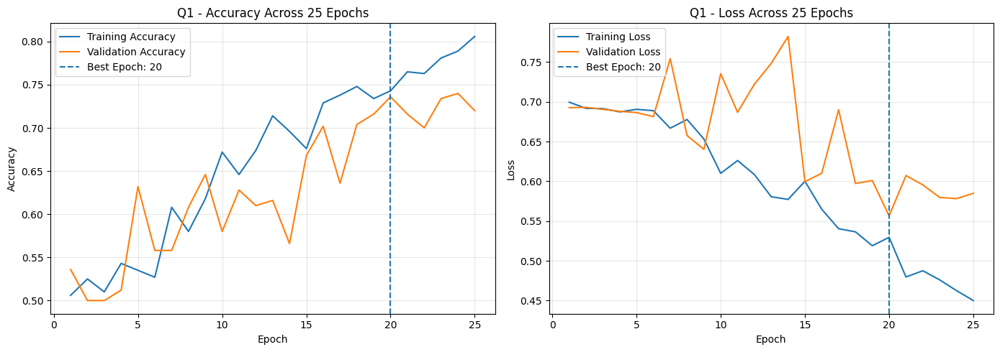


Results saved in: /kaggle/working/q1_full25
QUESTION 1 TRAINING COMPLETE


In [5]:

# ============================================================
# ASSIGNMENT 2 - QUESTION 1
# CNN FROM SCRATCH - FULL 25 EPOCHS
# Training: 1000 | Validation: 500 | Testing: 500
# ============================================================

import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow.keras import layers, models

# ------------------------------------------------------------
# 1. REPRODUCIBILITY
# ------------------------------------------------------------

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:",
      tf.config.list_physical_devices("GPU"))

# Create a separate results folder
results_dir = Path("/kaggle/working/q1_full25")
results_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD DATASET
# ------------------------------------------------------------

train_df = pd.read_csv(
    "/kaggle/working/q1_training.csv"
)

manifest = pd.read_csv(
    "/kaggle/working/assignment2_manifest.csv"
)

val_df = manifest[
    manifest["split"] == "validation"
].copy()

# Verify assignment requirements
assert len(train_df) == 1000
assert len(val_df) == 500

print("\nDATASET INFORMATION")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images: 500 (reserved for final evaluation)")

# ------------------------------------------------------------
# 3. PREPARE IMAGES
# ------------------------------------------------------------

label_map = {"cat": 0, "dog": 1}

def prepare_dataset(frame, training=False):

    paths = frame["image_path"].astype(str).to_numpy()

    labels = frame["label"].map(
        label_map
    ).to_numpy(dtype="float32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            len(frame),
            seed=42,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):

        image = tf.io.read_file(path)

        image = tf.image.decode_jpeg(
            image, channels=3
        )

        image = tf.image.resize(
            image, (150, 150)
        )

        return image, tf.expand_dims(label, -1)

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

train_ds = prepare_dataset(
    train_df, training=True
)

val_ds = prepare_dataset(val_df)

# ------------------------------------------------------------
# 4. BUILD CNN FROM SCRATCH
# ------------------------------------------------------------

model = models.Sequential([

    layers.Input(shape=(150, 150, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.10),

    # Normalize pixels
    layers.Rescaling(1.0 / 255),

    # Convolution layers
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    # Classification layers
    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    # Prevent overfitting
    layers.Dropout(0.5),

    # Binary classification
    layers.Dense(1, activation="sigmoid")

])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ------------------------------------------------------------
# 5. SAVE THE BEST MODEL WITHOUT STOPPING TRAINING
# ------------------------------------------------------------

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(results_dir / "best_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# ------------------------------------------------------------
# 6. TRAIN FOR ALL 25 EPOCHS
# ------------------------------------------------------------

print("\nSTARTING FULL 25-EPOCH TRAINING")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[checkpoint],
    verbose=1
)

print("\nALL 25 EPOCHS COMPLETED")

# Save the model as it stands after epoch 25
model.save(str(results_dir / "final_epoch_model.keras"))

# ------------------------------------------------------------
# 7. LOAD THE BEST MODEL
# ------------------------------------------------------------

best_model = tf.keras.models.load_model(
    str(results_dir / "best_model.keras")
)

best_loss, best_accuracy = best_model.evaluate(
    val_ds,
    verbose=0
)

# ------------------------------------------------------------
# 8. IDENTIFY THE BEST EPOCH
# ------------------------------------------------------------

history_df = pd.DataFrame(history.history)

best_epoch_index = history_df["val_loss"].idxmin()
best_epoch = best_epoch_index + 1

print("\n===================================")
print("QUESTION 1 - FINAL RESULTS")
print("===================================")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("Epochs completed:",
      len(history.history["loss"]))

print("Best epoch:", best_epoch)

print(
    "Training accuracy at best epoch:",
    f"{history_df.loc[best_epoch_index, 'accuracy'] * 100:.2f}%"
)

print(
    "Validation accuracy at best epoch:",
    f"{best_accuracy * 100:.2f}%"
)

print(
    "Validation loss at best epoch:",
    f"{best_loss:.4f}"
)

print(
    "Validation accuracy at epoch 25:",
    f"{history_df['val_accuracy'].iloc[-1] * 100:.2f}%"
)

print(
    "Validation loss at epoch 25:",
    f"{history_df['val_loss'].iloc[-1]:.4f}"
)

# ------------------------------------------------------------
# 9. SAVE TRAINING HISTORY
# ------------------------------------------------------------

history_df.to_csv(
    results_dir / "training_history.csv",
    index=False
)

# Save summary results
results_df = pd.DataFrame([{
    "experiment": "Q1 CNN from Scratch",
    "training_images": 1000,
    "validation_images": 500,
    "epochs_completed": 25,
    "best_epoch": best_epoch,
    "best_val_accuracy": best_accuracy,
    "best_val_loss": best_loss
}])

results_df.to_csv(
    results_dir / "results_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 10. PLOT ACCURACY AND LOSS
# ------------------------------------------------------------

epochs_range = range(
    1, len(history.history["loss"]) + 1
)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5)
)

# Accuracy graph
axes[0].plot(
    epochs_range,
    history.history["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs_range,
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

axes[0].set_title("Q1 - Accuracy Across 25 Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss graph
axes[1].plot(
    epochs_range,
    history.history["loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs_range,
    history.history["val_loss"],
    label="Validation Loss"
)

axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

axes[1].set_title("Q1 - Loss Across 25 Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    results_dir / "learning_curves.png",
    dpi=200
)

plt.show()

print("\nResults saved in:", results_dir)
print("QUESTION 1 TRAINING COMPLETE")


In [6]:

import pandas as pd

# Read the LATEST 25-epoch experiment
history_df = pd.read_csv(
    "/kaggle/working/q1_full25/training_history.csv"
)

# Find best epoch based on validation loss
best_idx = history_df["val_loss"].idxmin()

print("===== LATEST Q1 RESULTS =====")
print("Total epochs:", len(history_df))
print("Best epoch:", best_idx + 1)

print(
    "Training accuracy at best epoch:",
    f"{history_df.loc[best_idx, 'accuracy'] * 100:.2f}%"
)

print(
    "Validation accuracy at best epoch:",
    f"{history_df.loc[best_idx, 'val_accuracy'] * 100:.2f}%"
)

print(
    "Validation loss at best epoch:",
    f"{history_df.loc[best_idx, 'val_loss']:.4f}"
)


===== LATEST Q1 RESULTS =====
Total epochs: 25
Best epoch: 20
Training accuracy at best epoch: 74.30%
Validation accuracy at best epoch: 73.60%
Validation loss at best epoch: 0.5566


TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

===== Q2 DATASET =====
Training: 1500
Validation: 500
Testing: 500
label
cat    750
dog    750
Name: count, dtype: int64
DATASET VERIFICATION: PASSED


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,043,905 (3.98 MB)

 Trainable params: 1,043,905 (3.98 MB)

 Non-trainable params: 0 (0.00 B)


STARTING Q2 TRAINING - 1500 IMAGES
Epoch 1/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5056 - loss: 0.7011
Epoch 1: val_loss improved from None to 0.69089, saving model to /kaggle/working/q2_full25/best_model.keras

Epoch 1: finished saving model to /kaggle/working/q2_full25/best_model.keras
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.5033 - loss: 0.6967 - val_accuracy: 0.5000 - val_loss: 0.6909
Epoch 2/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5359 - loss: 0.6879
Epoch 2: val_loss did not improve from 0.69089
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.5267 - loss: 0.6893 - val_accuracy: 0.5260 - val_loss: 0.6925
Epoch 3/25
46/47 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5130 - loss: 0.6927
Epoch 3: val_loss did not improve from 0.69089
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.5207 - loss: 0.6926 - val_accuracy: 0.5000 - val_loss: 0.6919
Epoch 4/25
46/47 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5533 - loss: 0.6

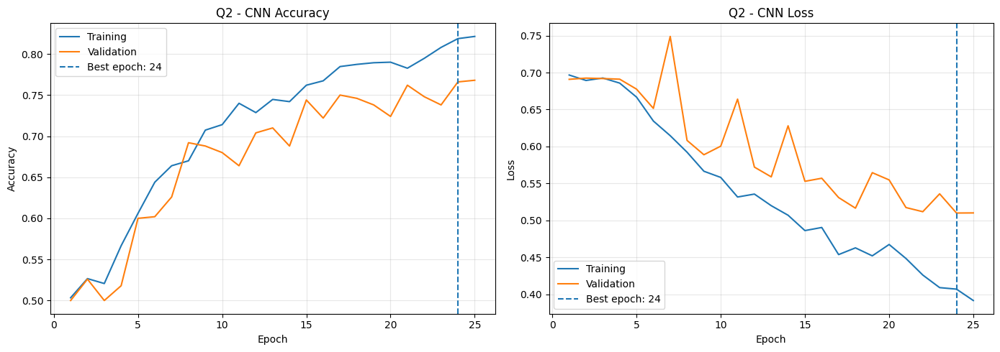


Q2 COMPLETE
Results saved in: /kaggle/working/q2_full25


In [7]:

# ============================================================
# ASSIGNMENT 2 - QUESTION 2
# CNN FROM SCRATCH - 1500 TRAINING IMAGES
# 25 EPOCHS - NO EARLY STOPPING
# ============================================================

import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. SETUP
# ------------------------------------------------------------

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

results_dir = Path("/kaggle/working/q2_full25")
results_dir.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

# ------------------------------------------------------------
# 2. PREPARE Q2 DATASET
# ------------------------------------------------------------

manifest = pd.read_csv(
    "/kaggle/working/assignment2_manifest.csv"
)

q1_df = pd.read_csv(
    "/kaggle/working/q1_training.csv"
)

train_pool = manifest[
    manifest["split"] == "train"
].copy()

val_df = manifest[
    manifest["split"] == "validation"
].copy()

test_df = manifest[
    manifest["split"] == "test"
].copy()

# Select 750 cats and 750 dogs from original pool
q2_df = (
    train_pool.groupby("label", group_keys=False)
    .head(750)
    .copy()
)

# Verify dataset sizes and class balance
assert len(q2_df) == 1500
assert len(val_df) == 500
assert len(test_df) == 500

assert q2_df["label"].value_counts().to_dict() == {
    "cat": 750,
    "dog": 750
}

# Q2 must contain all Q1 training images
assert set(q1_df["filename"]).issubset(
    set(q2_df["filename"])
)

# No overlap between training, validation and test
assert set(q2_df["filename"]).isdisjoint(
    set(val_df["filename"])
)

assert set(q2_df["filename"]).isdisjoint(
    set(test_df["filename"])
)

# Confirm image files exist
assert q2_df["image_path"].map(
    lambda p: Path(p).is_file()
).all()

q2_df.to_csv(
    results_dir / "q2_training_selection.csv",
    index=False
)

print("\n===== Q2 DATASET =====")
print("Training:", len(q2_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print(q2_df["label"].value_counts())
print("DATASET VERIFICATION: PASSED")

# ------------------------------------------------------------
# 3. IMAGE PREPARATION
# ------------------------------------------------------------

label_map = {"cat": 0, "dog": 1}

def prepare_dataset(frame, training=False):

    paths = frame["image_path"].astype(str).to_numpy()

    labels = frame["label"].map(
        label_map
    ).to_numpy(dtype="float32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            len(frame),
            seed=42,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):

        image = tf.io.read_file(path)
        image = tf.image.decode_jpeg(
            image, channels=3
        )
        image = tf.image.resize(
            image, (150, 150)
        )

        return image, tf.expand_dims(label, -1)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

train_ds = prepare_dataset(q2_df, training=True)
val_ds = prepare_dataset(val_df)

# ------------------------------------------------------------
# 4. BUILD THE SAME CNN AS Q1
# ------------------------------------------------------------

model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(150, 150, 3)),

    # Data augmentation
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.06),
    tf.keras.layers.RandomZoom(0.10),

    tf.keras.layers.Rescaling(1.0 / 255),

    tf.keras.layers.Conv2D(
        32, 3, activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        64, 3, activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        128, 3, activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        128, 3, activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        128, activation="relu"
    ),

    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(
        1, activation="sigmoid"
    )

])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ------------------------------------------------------------
# 5. SAVE BEST MODEL WITHOUT STOPPING TRAINING
# ------------------------------------------------------------

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(results_dir / "best_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# ------------------------------------------------------------
# 6. TRAIN ALL 25 EPOCHS
# ------------------------------------------------------------

print("\nSTARTING Q2 TRAINING - 1500 IMAGES")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[checkpoint],
    verbose=1
)

# Preserve the epoch-25 model separately
model.save(
    str(results_dir / "final_epoch_model.keras")
)

# ------------------------------------------------------------
# 7. LOAD THE BEST MODEL
# ------------------------------------------------------------

best_model = tf.keras.models.load_model(
    str(results_dir / "best_model.keras")
)

val_loss, val_accuracy = best_model.evaluate(
    val_ds,
    verbose=0
)

# ------------------------------------------------------------
# 8. RESULTS
# ------------------------------------------------------------

history_df = pd.DataFrame(history.history)

best_idx = history_df["val_loss"].idxmin()
best_epoch = best_idx + 1

print("\n===================================")
print("QUESTION 2 - FINAL RESULTS")
print("===================================")

print("Training images:", len(q2_df))
print("Validation images:", len(val_df))
print("Epochs completed:", len(history_df))
print("Best epoch:", best_epoch)

print(
    "Training accuracy at best epoch:",
    f"{history_df.loc[best_idx, 'accuracy'] * 100:.2f}%"
)

print(
    "Validation accuracy at best epoch:",
    f"{val_accuracy * 100:.2f}%"
)

print(
    "Validation loss at best epoch:",
    f"{val_loss:.4f}"
)

print(
    "Validation accuracy at epoch 25:",
    f"{history_df['val_accuracy'].iloc[-1] * 100:.2f}%"
)

print(
    "Validation loss at epoch 25:",
    f"{history_df['val_loss'].iloc[-1]:.4f}"
)

# ------------------------------------------------------------
# 9. SAVE RESULTS
# ------------------------------------------------------------

history_df.to_csv(
    results_dir / "training_history.csv",
    index=False
)

pd.DataFrame([{
    "experiment": "Q2 CNN from Scratch",
    "training_images": 1500,
    "validation_images": 500,
    "epochs_completed": len(history_df),
    "best_epoch": best_epoch,
    "best_val_accuracy": val_accuracy,
    "best_val_loss": val_loss
}]).to_csv(
    results_dir / "results_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 10. COMPARE AGAINST Q1
# ------------------------------------------------------------

q1_path = Path(
    "/kaggle/working/q1_full25/results_summary.csv"
)

if q1_path.exists():

    q1_results = pd.read_csv(q1_path).iloc[0]

    q1_accuracy = float(
        q1_results["best_val_accuracy"]
    )

    difference = (val_accuracy - q1_accuracy) * 100

    print("\n===== Q1 vs Q2 =====")
    print(f"Q1 accuracy: {q1_accuracy * 100:.2f}%")
    print(f"Q2 accuracy: {val_accuracy * 100:.2f}%")
    print(f"Difference: {difference:+.2f} percentage points")

# ------------------------------------------------------------
# 11. PLOT LEARNING CURVES
# ------------------------------------------------------------

epochs_range = range(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    epochs_range,
    history_df["accuracy"],
    label="Training"
)
axes[0].plot(
    epochs_range,
    history_df["val_accuracy"],
    label="Validation"
)
axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)
axes[0].set_title("Q2 - CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs_range,
    history_df["loss"],
    label="Training"
)
axes[1].plot(
    epochs_range,
    history_df["val_loss"],
    label="Validation"
)
axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)
axes[1].set_title("Q2 - CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    results_dir / "learning_curves.png",
    dpi=200
)

plt.show()

print("\nQ2 COMPLETE")
print("Results saved in:", results_dir)


Q3 Training: 2000
Validation: 500
Testing: 500
DATASET VERIFICATION: PASSED

STARTING Q3 TRAINING
Epoch 1/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5037 - loss: 0.6974
Epoch 1: val_loss improved from None to 0.68960, saving model to /kaggle/working/q3_full25/best_model.keras

Epoch 1: finished saving model to /kaggle/working/q3_full25/best_model.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.5145 - loss: 0.6942 - val_accuracy: 0.5800 - val_loss: 0.6896
Epoch 2/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5322 - loss: 0.6868
Epoch 2: val_loss improved from 0.68960 to 0.67698, saving model to /kaggle/working/q3_full25/best_model.keras

Epoch 2: finished saving model to /kaggle/working/q3_full25/best_model.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.5415 - loss: 0.6859 - val_accuracy: 0.5980 - val_loss: 0.6770
Epoch 3/25
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6127 - loss: 0.6693
Epoch 3: val_loss improved from 0.67698 

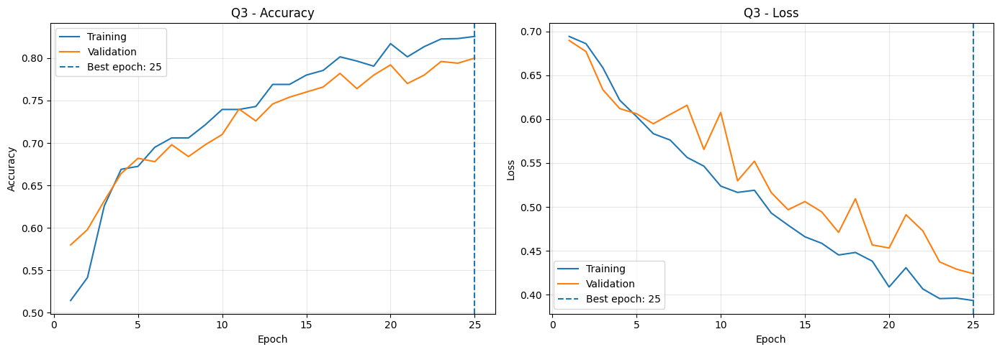


QUESTION 3 COMPLETE
Results saved in: /kaggle/working/q3_full25


In [8]:

# ============================================================
# ASSIGNMENT 2 - QUESTION 3
# CNN FROM SCRATCH - 2000 TRAINING IMAGES
# 25 EPOCHS - BEST MODEL SAVED
# ============================================================

import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. SETUP
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

results_dir = Path("/kaggle/working/q3_full25")
results_dir.mkdir(parents=True, exist_ok=True)

# 2. LOAD ORIGINAL DATA SPLITS
manifest = pd.read_csv(
    "/kaggle/working/assignment2_manifest.csv"
)

train_pool = manifest[
    manifest["split"] == "train"
].copy()

val_df = manifest[
    manifest["split"] == "validation"
].copy()

test_df = manifest[
    manifest["split"] == "test"
].copy()

# Q3: Select 1000 cats + 1000 dogs
q3_df = (
    train_pool.groupby("label", group_keys=False)
    .head(1000)
    .copy()
)

# 3. VERIFY DATASET
assert len(q3_df) == 2000
assert len(val_df) == 500
assert len(test_df) == 500

assert q3_df["label"].value_counts().to_dict() == {
    "cat": 1000,
    "dog": 1000
}

# Verify Q3 contains Q2 training samples
q2_df = pd.read_csv(
    "/kaggle/working/q2_full25/q2_training_selection.csv"
)

assert set(q2_df["filename"]).issubset(
    set(q3_df["filename"])
)

# No training/validation/test overlap
assert set(q3_df["filename"]).isdisjoint(
    set(val_df["filename"])
)
assert set(q3_df["filename"]).isdisjoint(
    set(test_df["filename"])
)

assert q3_df["image_path"].map(
    lambda p: Path(p).is_file()
).all()

q3_df.to_csv(
    results_dir / "q3_training_selection.csv",
    index=False
)

print("Q3 Training:", len(q3_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("DATASET VERIFICATION: PASSED")

# 4. PREPARE IMAGE DATA
label_map = {"cat": 0, "dog": 1}

def prepare_dataset(frame, training=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label"].map(
        label_map
    ).to_numpy(dtype="float32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            len(frame),
            seed=42,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.image.decode_jpeg(
            image, channels=3
        )
        image = tf.image.resize(image, (150, 150))
        return image, tf.expand_dims(label, -1)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

train_ds = prepare_dataset(q3_df, training=True)
val_ds = prepare_dataset(val_df)

# 5. BUILD A NEW CNN FROM SCRATCH
# Same architecture as Q1 and Q2

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(150, 150, 3)),

    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.06),
    tf.keras.layers.RandomZoom(0.10),

    tf.keras.layers.Rescaling(1.0 / 255),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 6. SAVE BEST MODEL, COMPLETE 25 EPOCHS
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    str(results_dir / "best_model.keras"),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

print("\nSTARTING Q3 TRAINING")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[checkpoint],
    verbose=1
)

model.save(
    str(results_dir / "final_epoch_model.keras")
)

# 7. RESTORE BEST MODEL
best_model = tf.keras.models.load_model(
    str(results_dir / "best_model.keras")
)

val_loss, val_accuracy = best_model.evaluate(
    val_ds,
    verbose=0
)

history_df = pd.DataFrame(history.history)
best_idx = history_df["val_loss"].idxmin()
best_epoch = best_idx + 1

# 8. DISPLAY RESULTS
print("\n===================================")
print("QUESTION 3 - FINAL RESULTS")
print("===================================")

print("Training images:", len(q3_df))
print("Validation images:", len(val_df))
print("Epochs completed:", len(history_df))
print("Best epoch:", best_epoch)

print(
    "Training accuracy at best epoch:",
    f"{history_df.loc[best_idx, 'accuracy'] * 100:.2f}%"
)

print(
    "Validation accuracy at best epoch:",
    f"{val_accuracy * 100:.2f}%"
)

print(
    "Validation loss at best epoch:",
    f"{val_loss:.4f}"
)

print(
    "Validation accuracy at epoch 25:",
    f"{history_df['val_accuracy'].iloc[-1] * 100:.2f}%"
)

# 9. SAVE EXPERIMENT RESULTS
history_df.to_csv(
    results_dir / "training_history.csv",
    index=False
)

pd.DataFrame([{
    "experiment": "Q3 CNN from Scratch",
    "training_images": 2000,
    "validation_images": 500,
    "epochs_completed": 25,
    "best_epoch": best_epoch,
    "best_val_accuracy": val_accuracy,
    "best_val_loss": val_loss
}]).to_csv(
    results_dir / "results_summary.csv",
    index=False
)

# 10. COMPARE Q1, Q2 AND Q3
comparison = []

for question in ["q1", "q2", "q3"]:
    path = Path(
        f"/kaggle/working/{question}_full25/results_summary.csv"
    )

    if path.exists():
        data = pd.read_csv(path).iloc[0]

        comparison.append({
            "Question": question.upper(),
            "Training Images": int(data["training_images"]),
            "Validation Accuracy (%)":
                round(float(data["best_val_accuracy"]) * 100, 2),
            "Validation Loss":
                round(float(data["best_val_loss"]), 4)
        })

comparison_df = pd.DataFrame(comparison)

print("\n===== Q1 vs Q2 vs Q3 =====")
print(comparison_df.to_string(index=False))

comparison_df.to_csv(
    results_dir / "comparison.csv",
    index=False
)

# 11. PLOT LEARNING CURVES
epochs_range = range(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    epochs_range, history_df["accuracy"],
    label="Training"
)
axes[0].plot(
    epochs_range, history_df["val_accuracy"],
    label="Validation"
)
axes[0].axvline(
    best_epoch, linestyle="--",
    label=f"Best epoch: {best_epoch}"
)
axes[0].set_title("Q3 - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs_range, history_df["loss"],
    label="Training"
)
axes[1].plot(
    epochs_range, history_df["val_loss"],
    label="Validation"
)
axes[1].axvline(
    best_epoch, linestyle="--",
    label=f"Best epoch: {best_epoch}"
)
axes[1].set_title("Q3 - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    results_dir / "learning_curves.png",
    dpi=200
)
plt.show()

print("\nQUESTION 3 COMPLETE")
print("Results saved in:", results_dir)


In [9]:

# ============================================================
# EXTENDED ANALYSIS - DATA PREPARATION
# 12,000 and 18,000 training images
# Additional validation: 2,000 images
# ============================================================

import pandas as pd
import random
import zipfile
from pathlib import Path
from PIL import Image
from io import BytesIO

root = Path("/kaggle/working")
output = root / "extended_experiments"
output.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(root / "assignment2_manifest.csv")

original_train = manifest[
    manifest["split"] == "train"
].copy()

original_val = manifest[
    manifest["split"] == "validation"
].copy()

original_test = manifest[
    manifest["split"] == "test"
].copy()

assert len(original_train) == 2000
assert len(original_val) == 500
assert len(original_test) == 500

# Exclude every image already allocated
used_names = {
    Path(name).name for name in manifest["filename"]
}

zip_path = list(
    Path("/kaggle/input").rglob("train.zip")
)[0]

extra_train_records = []
extra_val_records = []

rng = random.Random(2026)

with zipfile.ZipFile(zip_path) as archive:

    # Identify original image filenames
    lookup = {
        Path(name).name: name
        for name in archive.namelist()
        if name.lower().endswith(".jpg")
    }

    for label in ["cat", "dog"]:

        candidates = sorted([
            name for name in lookup
            if name.startswith(label + ".")
            and name not in used_names
        ])

        rng.shuffle(candidates)
        selected = 0

        for name in candidates:

            if selected >= 9000:
                break

            # Read and verify the image
            try:
                image_bytes = archive.read(lookup[name])

                with Image.open(BytesIO(image_bytes)) as im:
                    im.load()

            except Exception:
                print("Skipping unreadable image:", name)
                continue

            # First 1000 per class: extra validation
            # Remaining 8000 per class: extra training
            if selected < 1000:
                split = "extended_validation"
            else:
                split = "extended_train"

            path = output / "images" / split / label / name
            path.parent.mkdir(
                parents=True, exist_ok=True
            )
            path.write_bytes(image_bytes)

            record = {
                "split": split,
                "filename": lookup[name],
                "label": label,
                "image_path": str(path)
            }

            if split == "extended_validation":
                extra_val_records.append(record)
            else:
                extra_train_records.append(record)

            selected += 1

        assert selected == 9000, (
            f"Insufficient valid {label} images"
        )

extra_train = pd.DataFrame(extra_train_records)
extra_val = pd.DataFrame(extra_val_records)

# 12,000 images = original 2,000 + 10,000 extra
extra_10k = (
    extra_train.groupby("label", group_keys=False)
    .head(5000)
)

train_12k = pd.concat(
    [original_train, extra_10k],
    ignore_index=True
)

# 18,000 images = original 2,000 + 16,000 extra
train_18k = pd.concat(
    [original_train, extra_train],
    ignore_index=True
)

# Check all sizes
assert len(train_12k) == 12000
assert len(train_18k) == 18000
assert len(extra_val) == 2000

assert train_12k["label"].value_counts().to_dict() == {
    "cat": 6000, "dog": 6000
}

assert train_18k["label"].value_counts().to_dict() == {
    "cat": 9000, "dog": 9000
}

# Confirm datasets are nested
assert set(train_12k["filename"]).issubset(
    set(train_18k["filename"])
)

# Verify no overlap with either validation or test
training_names = set(train_18k["filename"])

for frame in [original_val, original_test, extra_val]:
    assert training_names.isdisjoint(
        set(frame["filename"])
    )

# Save selections
train_12k.to_csv(output / "train_12000.csv", index=False)
train_18k.to_csv(output / "train_18000.csv", index=False)
extra_val.to_csv(
    output / "extended_validation_2000.csv",
    index=False
)

print("\n===== EXTENDED DATASET SUMMARY =====")
print("Experiment A training:", len(train_12k))
print("Experiment B training:", len(train_18k))
print("Original validation:", len(original_val))
print("Additional validation:", len(extra_val))
print("Original test (untouched):", len(original_test))
print("No overlapping samples: PASSED")
print("DATA PREPARATION COMPLETE")



===== EXTENDED DATASET SUMMARY =====
Experiment A training: 12000
Experiment B training: 18000
Original validation: 500
Additional validation: 2000
Original test (untouched): 500
No overlapping samples: PASSED
DATA PREPARATION COMPLETE



STARTING EXPERIMENT: 12000 IMAGES
Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 28ms/step - accuracy: 0.5863 - loss: 0.6620 - val_accuracy: 0.6600 - val_loss: 0.6161
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.6987 - loss: 0.5770 - val_accuracy: 0.7300 - val_loss: 0.5447
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.7355 - loss: 0.5295 - val_accuracy: 0.7700 - val_loss: 0.4748
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7688 - loss: 0.4861 - val_accuracy: 0.7920 - val_loss: 0.4369
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.7942 - loss: 0.4474 - val_accuracy: 0.8320 - val_loss: 0.3705
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.8067 - loss: 0.4221 - val_accuracy: 0.8140 - val_loss: 0.3776
Epoch 7/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.8221 - loss: 0.3986 - val_accuracy: 0.8320 - val_loss: 0.3528
Epoch 8/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step -

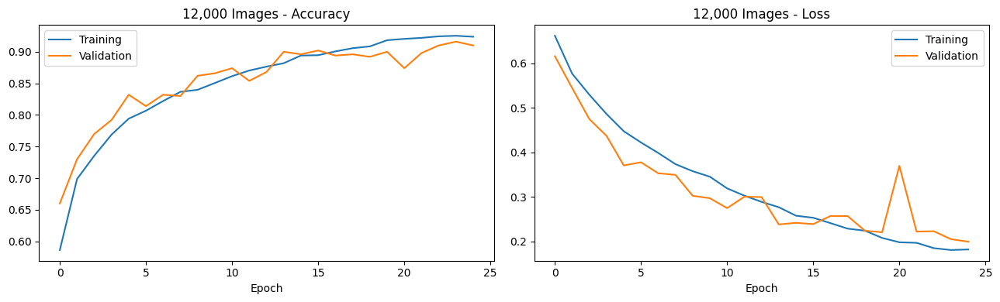


RESULTS: 12,000 IMAGES
Best epoch: 25
Original validation accuracy: 91.00%
Extended validation accuracy: 91.05%
Original validation loss: 0.1991
Extended validation loss: 0.2291
Training time: 4.30 minutes

STARTING EXPERIMENT: 18000 IMAGES
Epoch 1/25
563/563 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.6260 - loss: 0.6358 - val_accuracy: 0.6820 - val_loss: 0.6010
Epoch 2/25
563/563 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step - accuracy: 0.7291 - loss: 0.5387 - val_accuracy: 0.8100 - val_loss: 0.4450
Epoch 3/25
563/563 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step - accuracy: 0.7776 - loss: 0.4699 - val_accuracy: 0.8160 - val_loss: 0.3682
Epoch 4/25
563/563 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step - accuracy: 0.7987 - loss: 0.4305 - val_accuracy: 0.8420 - val_loss: 0.3473
Epoch 5/25
563/563 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step - accuracy: 0.8252 - loss: 0.3898 - val_accuracy: 0.8380 - val_loss: 0.3627
Epoch 6/25
563/563 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step - accuracy: 0.8363 - loss: 0.3642 - val_accuracy: 0.86

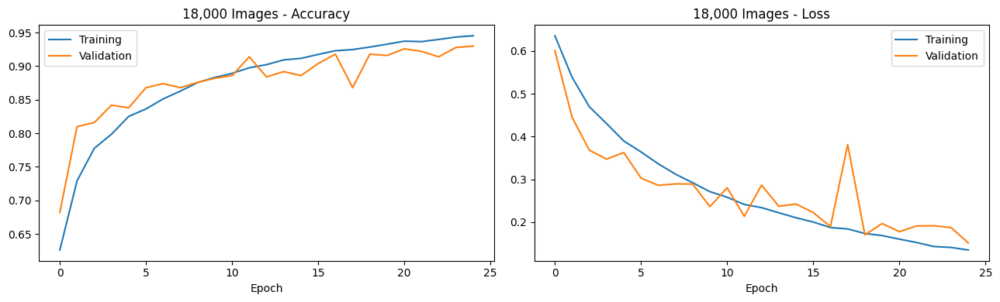


RESULTS: 18,000 IMAGES
Best epoch: 25
Original validation accuracy: 93.00%
Extended validation accuracy: 93.70%
Original validation loss: 0.1514
Extended validation loss: 0.1602
Training time: 6.36 minutes


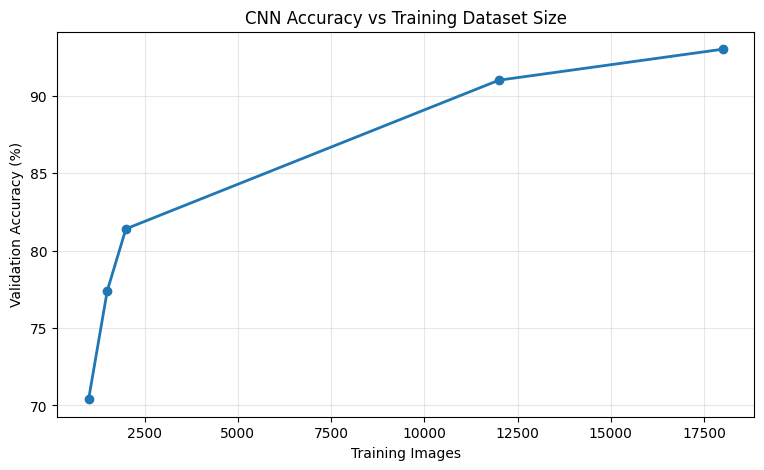


===== ALL FIVE EXPERIMENTS =====
 Images  Accuracy
   1000 70.400000
   1500 77.400000
   2000 81.400000
  12000 91.000003
  18000 93.000001

===== ADDITIONAL VALIDATION RESULTS =====
 training_images  epochs_completed  best_epoch  original_val_accuracy  original_val_loss  extended_val_accuracy  extended_val_loss  training_minutes
           12000                25          25                   0.91           0.199091                 0.9105           0.229063              4.30
           18000                25          25                   0.93           0.151408                 0.9370           0.160250              6.36

ALL EXTENDED EXPERIMENTS COMPLETE


In [10]:

# ============================================================
# EXTENDED ANALYSIS - TWO CNN EXPERIMENTS
# Experiment A: 12,000 images
# Experiment B: 18,000 images
# 25 epochs each, trained independently from scratch
# ============================================================

import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import time
from pathlib import Path

root = Path("/kaggle/working")
output = root / "extended_experiments"

manifest = pd.read_csv(
    root / "assignment2_manifest.csv"
)

original_val = manifest[
    manifest["split"] == "validation"
].copy()

extended_val = pd.read_csv(
    output / "extended_validation_2000.csv"
)

label_map = {"cat": 0, "dog": 1}

# ------------------------------------------------------------
# DATA LOADER
# ------------------------------------------------------------

def make_dataset(frame, training=False):

    paths = frame["image_path"].astype(str).to_numpy()

    labels = frame["label"].map(
        label_map
    ).to_numpy(dtype="float32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            len(frame),
            seed=42,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.image.decode_jpeg(
            image, channels=3
        )
        image = tf.image.resize(
            image, (150, 150)
        )
        return image, tf.expand_dims(label, -1)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

# ------------------------------------------------------------
# SAME CNN ARCHITECTURE AS Q1-Q3
# ------------------------------------------------------------

def build_model():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=(150, 150, 3)),

        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.06),
        tf.keras.layers.RandomZoom(0.10),

        tf.keras.layers.Rescaling(1.0 / 255),

        tf.keras.layers.Conv2D(
            32, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(
            64, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(
            128, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(
            128, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(
            128, activation="relu"
        ),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(
            1, activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0003
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# Fixed validation datasets
val_ds = make_dataset(original_val)
extended_val_ds = make_dataset(extended_val)

all_results = []

# ------------------------------------------------------------
# RUN BOTH EXPERIMENTS
# ------------------------------------------------------------

for sample_size in [12000, 18000]:

    print("\n" + "=" * 50)
    print(f"STARTING EXPERIMENT: {sample_size} IMAGES")
    print("=" * 50)

    # Start each experiment from scratch
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    experiment_dir = output / f"cnn_{sample_size}"
    experiment_dir.mkdir(
        parents=True, exist_ok=True
    )

    train_df = pd.read_csv(
        output / f"train_{sample_size}.csv"
    )

    assert len(train_df) == sample_size

    train_ds = make_dataset(
        train_df, training=True
    )

    model = build_model()

    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        str(experiment_dir / "best_model.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=0
    )

    start_time = time.perf_counter()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=25,
        callbacks=[checkpoint],
        verbose=1
    )

    elapsed_minutes = (
        time.perf_counter() - start_time
    ) / 60

    # Save the epoch-25 model
    model.save(
        str(experiment_dir / "epoch25_model.keras")
    )

    # Load model selected by original validation loss
    best_model = tf.keras.models.load_model(
        str(experiment_dir / "best_model.keras")
    )

    # Original 500-image validation set
    val_loss, val_accuracy = best_model.evaluate(
        val_ds, verbose=0
    )

    # Additional 2000-image validation set
    ext_loss, ext_accuracy = best_model.evaluate(
        extended_val_ds, verbose=0
    )

    history_df = pd.DataFrame(history.history)

    best_epoch = (
        history_df["val_loss"].idxmin() + 1
    )

    result = {
        "training_images": sample_size,
        "epochs_completed": len(history_df),
        "best_epoch": best_epoch,
        "original_val_accuracy": val_accuracy,
        "original_val_loss": val_loss,
        "extended_val_accuracy": ext_accuracy,
        "extended_val_loss": ext_loss,
        "training_minutes": round(elapsed_minutes, 2)
    }

    all_results.append(result)

    history_df.to_csv(
        experiment_dir / "training_history.csv",
        index=False
    )

    pd.DataFrame([result]).to_csv(
        experiment_dir / "results_summary.csv",
        index=False
    )

    # Plot learning curves
    fig, axes = plt.subplots(
        1, 2, figsize=(13, 4)
    )

    axes[0].plot(
        history_df["accuracy"],
        label="Training"
    )
    axes[0].plot(
        history_df["val_accuracy"],
        label="Validation"
    )
    axes[0].set_title(
        f"{sample_size:,} Images - Accuracy"
    )
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(
        history_df["loss"],
        label="Training"
    )
    axes[1].plot(
        history_df["val_loss"],
        label="Validation"
    )
    axes[1].set_title(
        f"{sample_size:,} Images - Loss"
    )
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()

    plt.savefig(
        experiment_dir / "learning_curves.png",
        dpi=180
    )

    plt.show()

    print(f"\nRESULTS: {sample_size:,} IMAGES")
    print("Best epoch:", best_epoch)
    print(
        "Original validation accuracy:",
        f"{val_accuracy * 100:.2f}%"
    )
    print(
        "Extended validation accuracy:",
        f"{ext_accuracy * 100:.2f}%"
    )
    print(
        "Original validation loss:",
        f"{val_loss:.4f}"
    )
    print(
        "Extended validation loss:",
        f"{ext_loss:.4f}"
    )
    print(
        "Training time:",
        f"{elapsed_minutes:.2f} minutes"
    )

# ------------------------------------------------------------
# FINAL COMPARISON
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

results_df.to_csv(
    output / "extended_comparison.csv",
    index=False
)

# Combine Q1-Q3 with extended experiments
comparison = [
    {"Images": 1000, "Accuracy": 70.4},
    {"Images": 1500, "Accuracy": 77.4},
    {"Images": 2000, "Accuracy": 81.4}
]

for result in all_results:
    comparison.append({
        "Images": result["training_images"],
        "Accuracy":
            result["original_val_accuracy"] * 100
    })

comparison_df = pd.DataFrame(comparison)

plt.figure(figsize=(9, 5))

plt.plot(
    comparison_df["Images"],
    comparison_df["Accuracy"],
    marker="o",
    linewidth=2
)

plt.title(
    "CNN Accuracy vs Training Dataset Size"
)
plt.xlabel("Training Images")
plt.ylabel("Validation Accuracy (%)")
plt.grid(alpha=0.3)

plt.savefig(
    output / "all_five_experiments.png",
    dpi=200
)
plt.show()

print("\n===== ALL FIVE EXPERIMENTS =====")
print(comparison_df.to_string(index=False))

print("\n===== ADDITIONAL VALIDATION RESULTS =====")
print(results_df.to_string(index=False))

print("\nALL EXTENDED EXPERIMENTS COMPLETE")


TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

DATASET VERIFIED
Training: 1000
Validation: 500
Test: 500 (untouched)


/tmp/ipykernel_48/3919961652.py:111: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Pretrained base loaded successfully


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


STARTING Q4A PRETRAINED TRAINING
Epoch 1/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4919 - loss: 1.0828
Epoch 1: val_loss improved from None to 0.44080, saving model to /kaggle/working/q4a_pretrained/best_model.keras

Epoch 1: finished saving model to /kaggle/working/q4a_pretrained/best_model.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 118ms/step - accuracy: 0.5210 - loss: 0.9899 - val_accuracy: 0.8060 - val_loss: 0.4408
Epoch 2/25
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.7045 - loss: 0.6293
Epoch 2: val_loss improved from 0.44080 to 0.23922, saving model to /kaggle/working/q4a_pretrained/best_model.keras

Epoch 2: finished saving model to /kaggle/working/q4a_pretrained/best_model.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 0.7260 - loss: 0.5872 - val_accuracy: 0.9340 - val_loss: 0.2392
Epoch 3/25
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.7959 - loss: 0.4276
Epoch 3: val_loss improved from 0.23922 to 0.16439, saving model to /kaggle/working

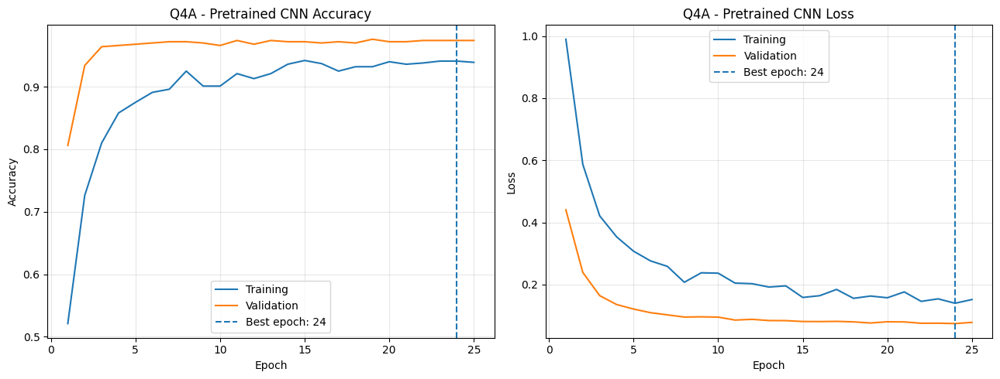


Q4A COMPLETE
Results saved in: /kaggle/working/q4a_pretrained


In [11]:

# =====================================================
# ASSIGNMENT 2 - QUESTION 4A
# PRETRAINED CNN - MobileNetV2
# Training: 1000 | Validation: 500
# 25 Epochs | Feature Extraction
# =====================================================

import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. SETUP
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

output = Path("/kaggle/working/q4a_pretrained")
output.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

# 2. LOAD DATA
train_df = pd.read_csv(
    "/kaggle/working/q1_training.csv"
)

manifest = pd.read_csv(
    "/kaggle/working/assignment2_manifest.csv"
)

val_df = manifest[
    manifest["split"] == "validation"
].copy()

test_df = manifest[
    manifest["split"] == "test"
].copy()

# Verify dataset
assert len(train_df) == 1000
assert len(val_df) == 500
assert len(test_df) == 500

assert train_df["label"].value_counts().to_dict() == {
    "cat": 500, "dog": 500
}

assert set(train_df["filename"]).isdisjoint(
    set(val_df["filename"])
)
assert set(train_df["filename"]).isdisjoint(
    set(test_df["filename"])
)

assert train_df["image_path"].map(
    lambda p: Path(p).is_file()
).all()

train_df.to_csv(
    output / "training_selection.csv", index=False
)

print("\nDATASET VERIFIED")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test: 500 (untouched)")

# 3. PREPARE DATA
label_map = {"cat": 0, "dog": 1}

def make_dataset(frame, training=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label"].map(
        label_map
    ).to_numpy(dtype="float32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            len(frame), seed=42,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.image.decode_jpeg(
            image, channels=3
        )
        image = tf.image.resize(
            image, (150, 150)
        )
        return image, tf.expand_dims(label, -1)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)

# 4. LOAD PRETRAINED MODEL
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(150, 150, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze original pretrained layers
base_model.trainable = False

print("\nPretrained base loaded successfully")

# 5. BUILD CLASSIFICATION MODEL
inputs = tf.keras.Input(shape=(150, 150, 3))

# Data augmentation
x = tf.keras.layers.RandomFlip("horizontal")(inputs)
x = tf.keras.layers.RandomRotation(0.06)(x)
x = tf.keras.layers.RandomZoom(0.10)(x)

# Correct preprocessing for MobileNetV2
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Extract pretrained features
x = base_model(x, training=False)

# Our new classification layers
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.5)(x)

outputs = tf.keras.layers.Dense(
    1, activation="sigmoid"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 6. SAVE BEST MODEL
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    str(output / "best_model.keras"),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

# 7. TRAIN ALL 25 EPOCHS
print("\nSTARTING Q4A PRETRAINED TRAINING")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[checkpoint],
    verbose=1
)

model.save(str(output / "epoch25_model.keras"))

# 8. EVALUATE BEST MODEL
best_model = tf.keras.models.load_model(
    str(output / "best_model.keras")
)

val_loss, val_accuracy = best_model.evaluate(
    val_ds, verbose=0
)

history_df = pd.DataFrame(history.history)

best_idx = history_df["val_loss"].idxmin()
best_epoch = best_idx + 1

print("\n===================================")
print("QUESTION 4A - PRETRAINED RESULTS")
print("===================================")

print("Model: MobileNetV2")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Epochs completed:", len(history_df))
print("Best epoch:", best_epoch)

print(
    "Training accuracy at best epoch:",
    f"{history_df.loc[best_idx, 'accuracy'] * 100:.2f}%"
)

print(
    "Validation accuracy at best epoch:",
    f"{val_accuracy * 100:.2f}%"
)

print(
    "Validation loss at best epoch:",
    f"{val_loss:.4f}"
)

print(
    "Validation accuracy at epoch 25:",
    f"{history_df['val_accuracy'].iloc[-1] * 100:.2f}%"
)

# 9. SAVE RESULTS
history_df.to_csv(
    output / "training_history.csv",
    index=False
)

pd.DataFrame([{
    "experiment": "Q4A Pretrained MobileNetV2",
    "training_images": 1000,
    "validation_images": 500,
    "best_epoch": best_epoch,
    "epochs_completed": len(history_df),
    "best_val_accuracy": val_accuracy,
    "best_val_loss": val_loss
}]).to_csv(
    output / "results_summary.csv",
    index=False
)

# 10. COMPARE WITH Q1
q1_results = pd.read_csv(
    "/kaggle/working/q1_full25/results_summary.csv"
).iloc[0]

scratch_acc = float(q1_results["best_val_accuracy"])

print("\n===== Q1 vs Q4A =====")
print(f"Scratch CNN: {scratch_acc*100:.2f}%")
print(f"Pretrained CNN: {val_accuracy*100:.2f}%")
print(
    f"Difference: "
    f"{(val_accuracy-scratch_acc)*100:+.2f} points"
)

# 11. PLOT LEARNING CURVES
epochs = range(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    epochs, history_df["accuracy"],
    label="Training"
)
axes[0].plot(
    epochs, history_df["val_accuracy"],
    label="Validation"
)
axes[0].axvline(
    best_epoch, linestyle="--",
    label=f"Best epoch: {best_epoch}"
)
axes[0].set_title("Q4A - Pretrained CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs, history_df["loss"],
    label="Training"
)
axes[1].plot(
    epochs, history_df["val_loss"],
    label="Validation"
)
axes[1].axvline(
    best_epoch, linestyle="--",
    label=f"Best epoch: {best_epoch}"
)
axes[1].set_title("Q4A - Pretrained CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    output / "learning_curves.png",
    dpi=200
)

plt.show()

print("\nQ4A COMPLETE")
print("Results saved in:", output)


DATASET VERIFIED
Training: 1500
Validation: 500
Testing: 500 (reserved)


/tmp/ipykernel_48/3083429693.py:120: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(



STARTING Q4-B TRAINING
Epoch 1/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 8s 85ms/step - accuracy: 0.5720 - loss: 0.8911 - val_accuracy: 0.8760 - val_loss: 0.3269
Epoch 2/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.8093 - loss: 0.4288 - val_accuracy: 0.9520 - val_loss: 0.1769
Epoch 3/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.8560 - loss: 0.3349 - val_accuracy: 0.9620 - val_loss: 0.1294
Epoch 4/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.8860 - loss: 0.2710 - val_accuracy: 0.9620 - val_loss: 0.1223
Epoch 5/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.9033 - loss: 0.2386 - val_accuracy: 0.9680 - val_loss: 0.1014
Epoch 6/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.9127 - loss: 0.2186 - val_accuracy: 0.9620 - val_loss: 0.1051
Epoch 7/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.9153 - loss: 0.2203 - val_accuracy: 0.9640 - val_loss: 0.0909
Epoch 8/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.9227 - loss: 0.1873 - 

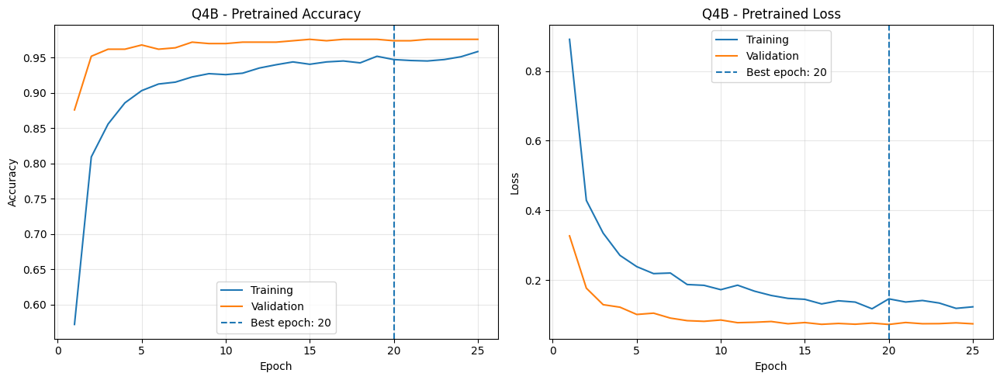


QUESTION 4-B COMPLETE
Results saved in: /kaggle/working/q4b_pretrained


In [12]:

# =====================================================
# ASSIGNMENT 2 - QUESTION 4B
# PRETRAINED MobileNetV2 - 1500 TRAINING IMAGES
# 25 EPOCHS - NO EARLY STOPPING
# =====================================================

import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. SETUP
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

root = Path("/kaggle/working")
output = root / "q4b_pretrained"
output.mkdir(parents=True, exist_ok=True)

# 2. LOAD SAME TRAINING SELECTION AS Q2
train_df = pd.read_csv(
    root / "q2_full25/q2_training_selection.csv"
)

q1_df = pd.read_csv(
    root / "q1_training.csv"
)

manifest = pd.read_csv(
    root / "assignment2_manifest.csv"
)

val_df = manifest[
    manifest["split"] == "validation"
].copy()

test_df = manifest[
    manifest["split"] == "test"
].copy()

assert len(train_df) == 1500
assert len(val_df) == 500
assert len(test_df) == 500

assert train_df["label"].value_counts().to_dict() == {
    "cat": 750, "dog": 750
}

assert set(q1_df["filename"]).issubset(
    set(train_df["filename"])
)

assert set(train_df["filename"]).isdisjoint(
    set(val_df["filename"])
)

assert set(train_df["filename"]).isdisjoint(
    set(test_df["filename"])
)

assert train_df["image_path"].map(
    lambda p: Path(p).is_file()
).all()

train_df.to_csv(
    output / "training_selection.csv",
    index=False
)

print("DATASET VERIFIED")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df), "(reserved)")

# 3. IMAGE DATA PIPELINE
label_map = {"cat": 0, "dog": 1}

def make_dataset(frame, training=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label"].map(
        label_map
    ).to_numpy(dtype="float32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            len(frame),
            seed=42,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.image.decode_jpeg(
            image, channels=3
        )
        image = tf.image.resize(
            image, (150, 150)
        )
        return image, tf.expand_dims(label, -1)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)

# 4. LOAD A FRESH IMAGENET PRETRAINED MODEL
# Do not reuse the classifier trained in Q4-A.

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(150, 150, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

# 5. BUILD THE SAME ARCHITECTURE AS Q4-A
inputs = tf.keras.Input(shape=(150, 150, 3))

x = tf.keras.layers.RandomFlip("horizontal")(inputs)
x = tf.keras.layers.RandomRotation(0.06)(x)
x = tf.keras.layers.RandomZoom(0.10)(x)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.5)(x)

outputs = tf.keras.layers.Dense(
    1, activation="sigmoid"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 6. SAVE BEST MODEL
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    str(output / "best_model.keras"),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=0
)

# 7. TRAIN ALL 25 EPOCHS
print("\nSTARTING Q4-B TRAINING")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[checkpoint],
    verbose=1
)

model.save(str(output / "epoch25_model.keras"))

# 8. LOAD THE BEST MODEL
best_model = tf.keras.models.load_model(
    str(output / "best_model.keras")
)

val_loss, val_accuracy = best_model.evaluate(
    val_ds, verbose=0
)

history_df = pd.DataFrame(history.history)

best_idx = history_df["val_loss"].idxmin()
best_epoch = best_idx + 1

# 9. DISPLAY RESULTS
print("\n===================================")
print("QUESTION 4B - PRETRAINED RESULTS")
print("===================================")

print("Model: MobileNetV2")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Epochs completed:", len(history_df))
print("Best epoch:", best_epoch)

print(
    "Training accuracy at best epoch:",
    f"{history_df.loc[best_idx, 'accuracy']*100:.2f}%"
)

print(
    "Validation accuracy at best epoch:",
    f"{val_accuracy*100:.2f}%"
)

print(
    "Validation loss at best epoch:",
    f"{val_loss:.4f}"
)

print(
    "Validation accuracy at epoch 25:",
    f"{history_df['val_accuracy'].iloc[-1]*100:.2f}%"
)

# 10. SAVE EXPERIMENT RESULTS
history_df.to_csv(
    output / "training_history.csv",
    index=False
)

pd.DataFrame([{
    "experiment": "Q4B Pretrained MobileNetV2",
    "training_images": 1500,
    "validation_images": 500,
    "epochs_completed": len(history_df),
    "best_epoch": best_epoch,
    "best_val_accuracy": val_accuracy,
    "best_val_loss": val_loss
}]).to_csv(
    output / "results_summary.csv",
    index=False
)

# 11. COMPARE Q4-A AND Q4-B
q4a = pd.read_csv(
    root / "q4a_pretrained/results_summary.csv"
).iloc[0]

q4a_acc = float(q4a["best_val_accuracy"])

print("\n===== PRETRAINED COMPARISON =====")
print(f"Q4-A (1000): {q4a_acc*100:.2f}%")
print(f"Q4-B (1500): {val_accuracy*100:.2f}%")
print(
    f"Difference: "
    f"{(val_accuracy-q4a_acc)*100:+.2f} points"
)

# 12. GENERATE LEARNING CURVES
epochs = range(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    epochs,
    history_df["accuracy"],
    label="Training"
)
axes[0].plot(
    epochs,
    history_df["val_accuracy"],
    label="Validation"
)
axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)
axes[0].set_title("Q4B - Pretrained Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs,
    history_df["loss"],
    label="Training"
)
axes[1].plot(
    epochs,
    history_df["val_loss"],
    label="Validation"
)
axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)
axes[1].set_title("Q4B - Pretrained Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    output / "learning_curves.png",
    dpi=200
)
plt.show()

print("\nQUESTION 4-B COMPLETE")
print("Results saved in:", output)


In [13]:

import tensorflow as tf

best_model = tf.keras.models.load_model(
    "/kaggle/working/q4b_pretrained/best_model.keras"
)

# Evaluate training images with augmentation
# and dropout automatically disabled
train_loss, train_accuracy = best_model.evaluate(
    train_ds, verbose=0
)

val_loss, val_accuracy = best_model.evaluate(
    val_ds, verbose=0
)

print("Training accuracy (evaluation mode):",
      f"{train_accuracy * 100:.2f}%")

print("Validation accuracy:",
      f"{val_accuracy * 100:.2f}%")


Training accuracy (evaluation mode): 97.80%
Validation accuracy: 97.40%


DATASET VERIFIED
Training: 2000
Validation: 500
Testing: 500 (reserved)


/tmp/ipykernel_48/4005938287.py:126: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


STARTING Q4-C PRETRAINED TRAINING
Epoch 1/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 71ms/step - accuracy: 0.6270 - loss: 0.7864 - val_accuracy: 0.9340 - val_loss: 0.2361
Epoch 2/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.8445 - loss: 0.3656 - val_accuracy: 0.9660 - val_loss: 0.1420
Epoch 3/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.8980 - loss: 0.2772 - val_accuracy: 0.9660 - val_loss: 0.1074
Epoch 4/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.9035 - loss: 0.2306 - val_accuracy: 0.9760 - val_loss: 0.0954
Epoch 5/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.9210 - loss: 0.2080 - val_accuracy: 0.9740 - val_loss: 0.0874
Epoch 6/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.9225 - loss: 0.1939 - val_accuracy: 0.9700 - val_loss: 0.0858
Epoch 7/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.9300 - loss: 0.1809 - val_accuracy: 0.9760 - val_loss: 0.0816
Epoch 8/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.9300 - loss

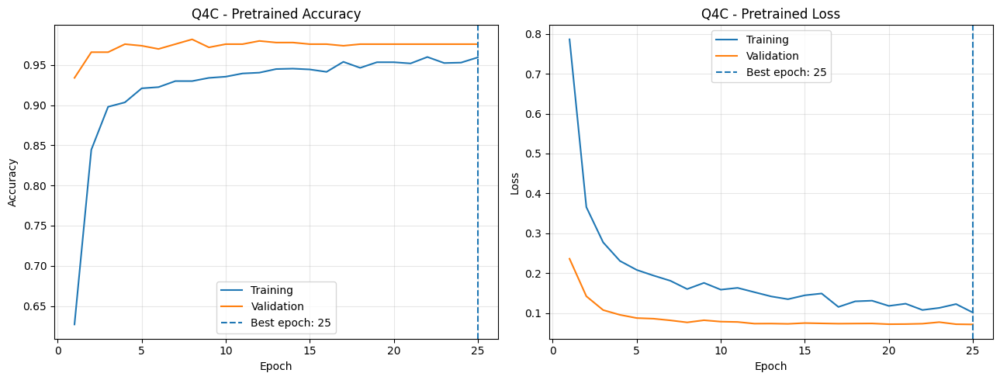

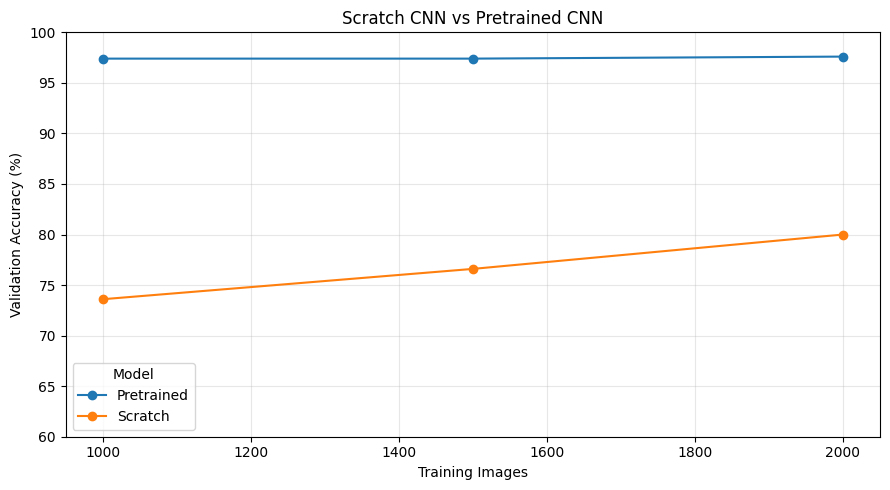


QUESTION 4C COMPLETE
Results saved in: /kaggle/working/q4c_pretrained


In [14]:

# ============================================================
# ASSIGNMENT 2 - QUESTION 4C
# PRETRAINED MobileNetV2 - 2000 TRAINING IMAGES
# 25 EPOCHS - FEATURE EXTRACTION
# ============================================================

import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. SETUP
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

root = Path("/kaggle/working")
output = root / "q4c_pretrained"
output.mkdir(parents=True, exist_ok=True)

# 2. LOAD DATASET
train_df = pd.read_csv(
    root / "q3_full25/q3_training_selection.csv"
)

q2_df = pd.read_csv(
    root / "q2_full25/q2_training_selection.csv"
)

manifest = pd.read_csv(
    root / "assignment2_manifest.csv"
)

val_df = manifest[
    manifest["split"] == "validation"
].copy()

test_df = manifest[
    manifest["split"] == "test"
].copy()

# Verify data sizes and independence
assert len(train_df) == 2000
assert len(val_df) == 500
assert len(test_df) == 500

assert train_df["label"].value_counts().to_dict() == {
    "cat": 1000,
    "dog": 1000
}

assert set(q2_df["filename"]).issubset(
    set(train_df["filename"])
)

assert set(train_df["filename"]).isdisjoint(
    set(val_df["filename"])
)

assert set(train_df["filename"]).isdisjoint(
    set(test_df["filename"])
)

assert train_df["image_path"].map(
    lambda p: Path(p).is_file()
).all()

train_df.to_csv(
    output / "training_selection.csv",
    index=False
)

print("DATASET VERIFIED")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df), "(reserved)")

# 3. IMAGE PREPARATION
label_map = {"cat": 0, "dog": 1}

def make_dataset(frame, training=False):

    paths = frame["image_path"].astype(str).to_numpy()

    labels = frame["label"].map(
        label_map
    ).to_numpy(dtype="float32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            len(frame),
            seed=42,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):

        image = tf.io.read_file(path)

        image = tf.image.decode_jpeg(
            image, channels=3
        )

        image = tf.image.resize(
            image, (150, 150)
        )

        return image, tf.expand_dims(label, -1)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)

# 4. LOAD FRESH PRETRAINED NETWORK
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(150, 150, 3),
    include_top=False,
    weights="imagenet"
)

# Preserve pretrained visual features
base_model.trainable = False

# 5. BUILD CLASSIFIER
inputs = tf.keras.Input(shape=(150, 150, 3))

x = tf.keras.layers.RandomFlip("horizontal")(inputs)
x = tf.keras.layers.RandomRotation(0.06)(x)
x = tf.keras.layers.RandomZoom(0.10)(x)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.5)(x)

outputs = tf.keras.layers.Dense(
    1, activation="sigmoid"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 6. SAVE BEST MODEL
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    str(output / "best_model.keras"),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=0
)

# 7. TRAIN ALL 25 EPOCHS
print("\nSTARTING Q4-C PRETRAINED TRAINING")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[checkpoint],
    verbose=1
)

model.save(str(output / "epoch25_model.keras"))

# 8. LOAD BEST MODEL
best_model = tf.keras.models.load_model(
    str(output / "best_model.keras")
)

val_loss, val_accuracy = best_model.evaluate(
    val_ds, verbose=0
)

# Also measure training accuracy in evaluation mode
train_eval_ds = make_dataset(train_df, training=False)

train_eval_loss, train_eval_accuracy = best_model.evaluate(
    train_eval_ds, verbose=0
)

history_df = pd.DataFrame(history.history)

best_idx = history_df["val_loss"].idxmin()
best_epoch = best_idx + 1

# 9. DISPLAY RESULTS
print("\n===================================")
print("QUESTION 4C - PRETRAINED RESULTS")
print("===================================")

print("Model: MobileNetV2")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Epochs completed:", len(history_df))
print("Best epoch:", best_epoch)

print(
    "Training accuracy at best epoch:",
    f"{history_df.loc[best_idx, 'accuracy']*100:.2f}%"
)

print(
    "Training accuracy (evaluation mode):",
    f"{train_eval_accuracy*100:.2f}%"
)

print(
    "Validation accuracy at best epoch:",
    f"{val_accuracy*100:.2f}%"
)

print(
    "Validation loss at best epoch:",
    f"{val_loss:.4f}"
)

print(
    "Validation accuracy at epoch 25:",
    f"{history_df['val_accuracy'].iloc[-1]*100:.2f}%"
)

# 10. SAVE RESULTS
history_df.to_csv(
    output / "training_history.csv",
    index=False
)

pd.DataFrame([{
    "experiment": "Q4C Pretrained MobileNetV2",
    "training_images": 2000,
    "validation_images": 500,
    "epochs_completed": len(history_df),
    "best_epoch": best_epoch,
    "best_val_accuracy": val_accuracy,
    "best_val_loss": val_loss,
    "train_eval_accuracy": train_eval_accuracy
}]).to_csv(
    output / "results_summary.csv",
    index=False
)

# 11. COMPARISON OF ALL REQUIRED EXPERIMENTS
experiments = [
    ("Scratch", 1000, "q1_full25"),
    ("Scratch", 1500, "q2_full25"),
    ("Scratch", 2000, "q3_full25"),
    ("Pretrained", 1000, "q4a_pretrained"),
    ("Pretrained", 1500, "q4b_pretrained"),
    ("Pretrained", 2000, "q4c_pretrained")
]

comparison = []

for model_type, n, folder in experiments:

    path = root / folder / "results_summary.csv"

    result = pd.read_csv(path).iloc[0]

    comparison.append({
        "Model": model_type,
        "Training Images": n,
        "Validation Accuracy (%)":
            round(float(result["best_val_accuracy"]) * 100, 2),
        "Validation Loss":
            round(float(result["best_val_loss"]), 4)
    })

comparison_df = pd.DataFrame(comparison)

print("\n===== ALL REQUIRED EXPERIMENTS =====")
print(comparison_df.to_string(index=False))

comparison_df.to_csv(
    output / "all_required_comparison.csv",
    index=False
)

# 12. PLOT LEARNING CURVES
epochs = range(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    epochs,
    history_df["accuracy"],
    label="Training"
)
axes[0].plot(
    epochs,
    history_df["val_accuracy"],
    label="Validation"
)
axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)
axes[0].set_title("Q4C - Pretrained Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs,
    history_df["loss"],
    label="Training"
)
axes[1].plot(
    epochs,
    history_df["val_loss"],
    label="Validation"
)
axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)
axes[1].set_title("Q4C - Pretrained Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    output / "learning_curves.png",
    dpi=200
)

plt.show()

# 13. VISUAL COMPARISON
pivot_df = comparison_df.pivot(
    index="Training Images",
    columns="Model",
    values="Validation Accuracy (%)"
)

pivot_df.plot(
    marker="o",
    figsize=(9, 5),
    title="Scratch CNN vs Pretrained CNN"
)

plt.xlabel("Training Images")
plt.ylabel("Validation Accuracy (%)")
plt.ylim(60, 100)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    output / "scratch_vs_pretrained.png",
    dpi=200
)

plt.show()

print("\nQUESTION 4C COMPLETE")
print("Results saved in:", output)


TEST DATASET VERIFIED: 500

EVALUATING: CNN From Scratch
Saved validation accuracy: 80.00%
Verified validation accuracy: 80.00%


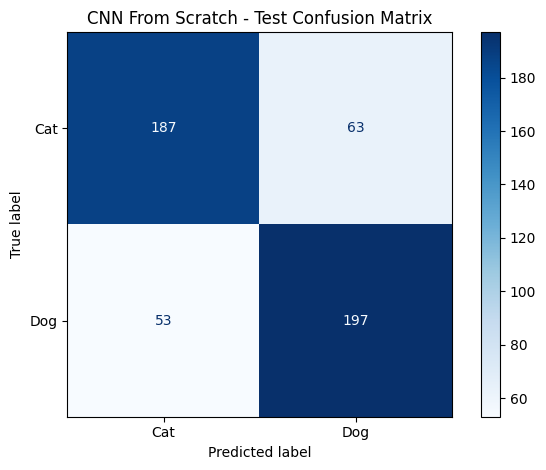


TEST RESULTS
Accuracy: 76.80%
Loss: 0.4798
Precision: 0.7577
Recall: 0.7880
F1 Score: 0.7725

EVALUATING: Pretrained MobileNetV2
Saved validation accuracy: 97.60%
Verified validation accuracy: 97.60%


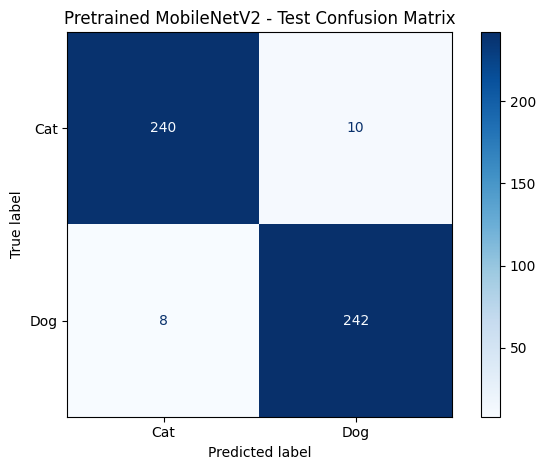


TEST RESULTS
Accuracy: 96.40%
Loss: 0.0699
Precision: 0.9603
Recall: 0.9680
F1 Score: 0.9641

FINAL TEST COMPARISON
                 Model  Training Images  Validation Accuracy (%)  Test Accuracy (%)  Test Loss  Precision  Recall  F1 Score
      CNN From Scratch             2000                     80.0               76.8     0.4798     0.7577   0.788    0.7725
Pretrained MobileNetV2             2000                     97.6               96.4     0.0699     0.9603   0.968    0.9641

Results saved in: /kaggle/working/final_assignment_results


In [15]:

# ============================================================
# ASSIGNMENT 2 - FINAL TEST EVALUATION
# Selected scratch and pretrained CNNs
# ============================================================

import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

root = Path("/kaggle/working")
output = root / "final_assignment_results"
output.mkdir(parents=True, exist_ok=True)

results_file = output / "final_test_results.csv"

# 1. LOAD FIXED DATA SPLITS

manifest = pd.read_csv(
    root / "assignment2_manifest.csv"
)

train_df = manifest[
    manifest["split"] == "train"
].copy()

val_df = manifest[
    manifest["split"] == "validation"
].copy()

test_df = manifest[
    manifest["split"] == "test"
].copy()

assert len(train_df) == 2000
assert len(val_df) == 500
assert len(test_df) == 500

assert test_df["label"].value_counts().to_dict() == {
    "cat": 250,
    "dog": 250
}

assert set(test_df["filename"]).isdisjoint(
    set(train_df["filename"])
)

assert set(test_df["filename"]).isdisjoint(
    set(val_df["filename"])
)

print("TEST DATASET VERIFIED:", len(test_df))

# 2. DATA LOADER

label_map = {"cat": 0, "dog": 1}

def make_dataset(frame):

    paths = frame["image_path"].astype(str).to_numpy()

    labels = frame["label"].map(
        label_map
    ).to_numpy(dtype="float32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    def load_image(path, label):

        image = tf.io.read_file(path)

        image = tf.image.decode_jpeg(
            image, channels=3
        )

        image = tf.image.resize(
            image, (150, 150)
        )

        return image, tf.expand_dims(label, -1)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# 3. SELECT MODELS USING VALIDATION RESULTS

models_to_test = [
    {
        "name": "CNN From Scratch",
        "folder": "q3_full25"
    },
    {
        "name": "Pretrained MobileNetV2",
        "folder": "q4c_pretrained"
    }
]

if results_file.exists():

    print("\nFINAL TEST WAS ALREADY RECORDED.")
    print("Using existing saved results:")
    print(pd.read_csv(results_file).to_string(index=False))

else:

    all_results = []

    for experiment in models_to_test:

        name = experiment["name"]
        folder = root / experiment["folder"]

        print("\n" + "=" * 45)
        print("EVALUATING:", name)
        print("=" * 45)

        # Load best model
        model = tf.keras.models.load_model(
            str(folder / "best_model.keras")
        )

        # Verify it matches the saved validation summary
        summary = pd.read_csv(
            folder / "results_summary.csv"
        ).iloc[0]

        expected_val_acc = float(
            summary["best_val_accuracy"]
        )

        val_loss, val_acc = model.evaluate(
            val_ds, verbose=0
        )

        print(
            "Saved validation accuracy:",
            f"{expected_val_acc * 100:.2f}%"
        )

        print(
            "Verified validation accuracy:",
            f"{val_acc * 100:.2f}%"
        )

        assert abs(val_acc - expected_val_acc) < 0.002, (
            "Saved checkpoint and validation summary "
            "do not match. Review the experiment files."
        )

        # Final untouched test evaluation
        test_loss, test_acc = model.evaluate(
            test_ds, verbose=0
        )

        probabilities = model.predict(
            test_ds, verbose=0
        ).reshape(-1)

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        actual = test_df["label"].map(
            label_map
        ).to_numpy()

        # Classification metrics
        precision = precision_score(
            actual, predictions, zero_division=0
        )

        recall = recall_score(
            actual, predictions, zero_division=0
        )

        f1 = f1_score(
            actual, predictions, zero_division=0
        )

        result = {
            "Model": name,
            "Training Images": 2000,
            "Validation Accuracy (%)": round(
                val_acc * 100, 2
            ),
            "Test Accuracy (%)": round(
                test_acc * 100, 2
            ),
            "Test Loss": round(test_loss, 4),
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1 Score": round(f1, 4)
        }

        all_results.append(result)

        # Save individual predictions
        safe_name = experiment["folder"]

        pd.DataFrame({
            "filename": test_df["filename"].to_numpy(),
            "actual_label": actual,
            "predicted_label": predictions,
            "dog_probability": probabilities
        }).to_csv(
            output / f"{safe_name}_predictions.csv",
            index=False
        )

        # Confusion matrix
        cm = confusion_matrix(
            actual, predictions,
            labels=[0, 1]
        )

        display = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Cat", "Dog"]
        )

        display.plot(
            cmap="Blues",
            values_format="d"
        )

        plt.title(f"{name} - Test Confusion Matrix")
        plt.tight_layout()

        plt.savefig(
            output / f"{safe_name}_confusion_matrix.png",
            dpi=180
        )

        plt.show()

        print("\nTEST RESULTS")
        print(f"Accuracy: {test_acc * 100:.2f}%")
        print(f"Loss: {test_loss:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall: {recall:.4f}")
        print(f"F1 Score: {f1:.4f}")

    # 4. SAVE FINAL COMPARISON

    final_results = pd.DataFrame(all_results)

    final_results.to_csv(
        results_file,
        index=False
    )

    print("\n===================================")
    print("FINAL TEST COMPARISON")
    print("===================================")

    print(final_results.to_string(index=False))

    print("\nResults saved in:", output)


DATASET VERIFICATION: PASSED
Original validation: 500
Original test: 500

TESTING SCRATCH CNN: 12,000 IMAGES
Recorded validation accuracy: 91.00%
Verified validation accuracy: 91.00%


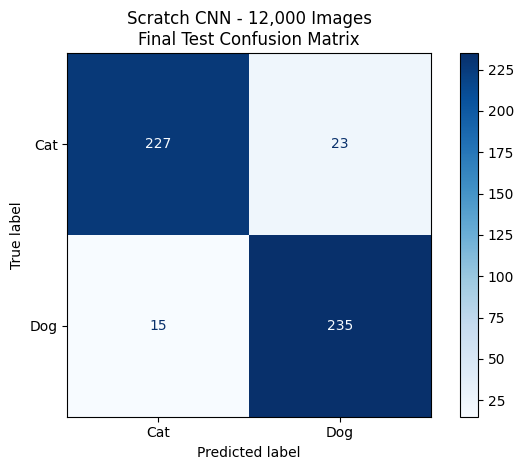


TEST RESULTS
Accuracy: 92.40%
Loss: 0.1926
Precision: 0.9109
Recall: 0.9400
F1 Score: 0.9252

TESTING SCRATCH CNN: 18,000 IMAGES
Recorded validation accuracy: 93.00%
Verified validation accuracy: 93.00%


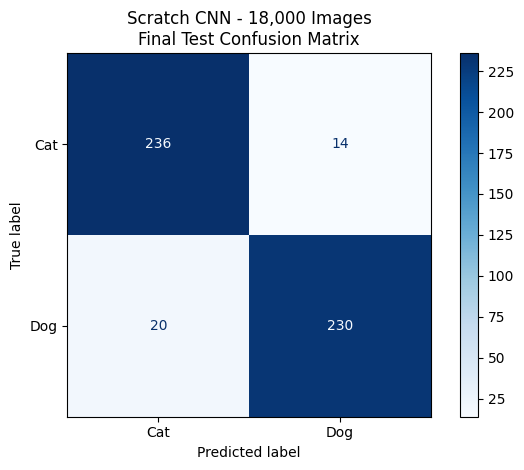


TEST RESULTS
Accuracy: 93.20%
Loss: 0.1667
Precision: 0.9426
Recall: 0.9200
F1 Score: 0.9312

FINAL TEST COMPARISON - ALL TESTED MODELS
                 Model  Training Images  Validation Accuracy (%)  Test Accuracy (%)  Test Loss  F1 Score
      CNN From Scratch             2000                     80.0               76.8     0.4798    0.7725
Pretrained MobileNetV2             2000                     97.6               96.4     0.0699    0.9641
  Scratch CNN (12,000)            12000                     91.0               92.4     0.1926    0.9252
  Scratch CNN (18,000)            18000                     93.0               93.2     0.1667    0.9312

ALL 8 TRAINING EXPERIMENTS
Model Type  Training Images  Validation Accuracy (%)
   Scratch             1000                     73.6
   Scratch             1500                     76.6
   Scratch             2000                     80.0
   Scratch            12000                     91.0
   Scratch            18000                  

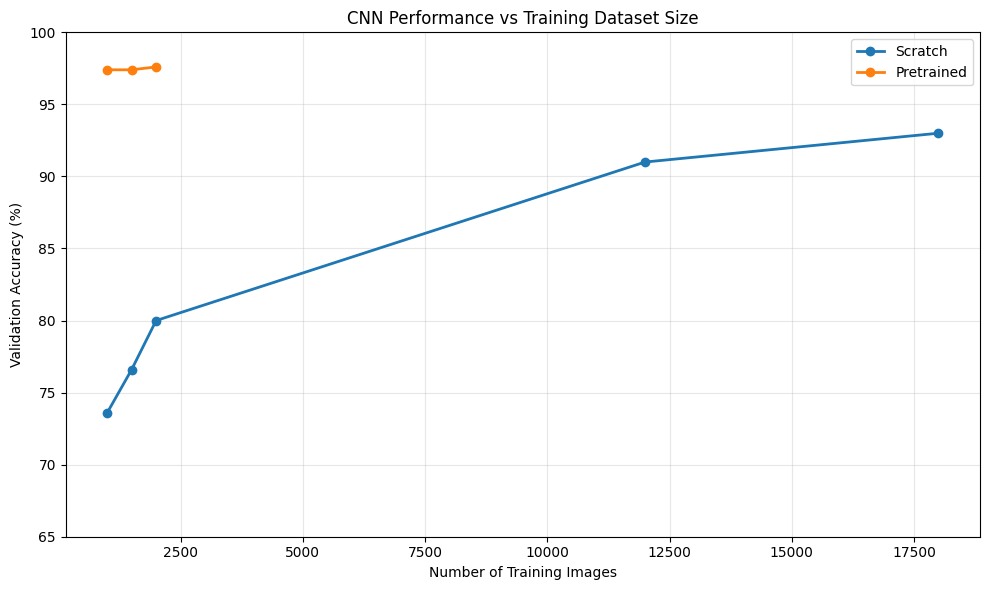

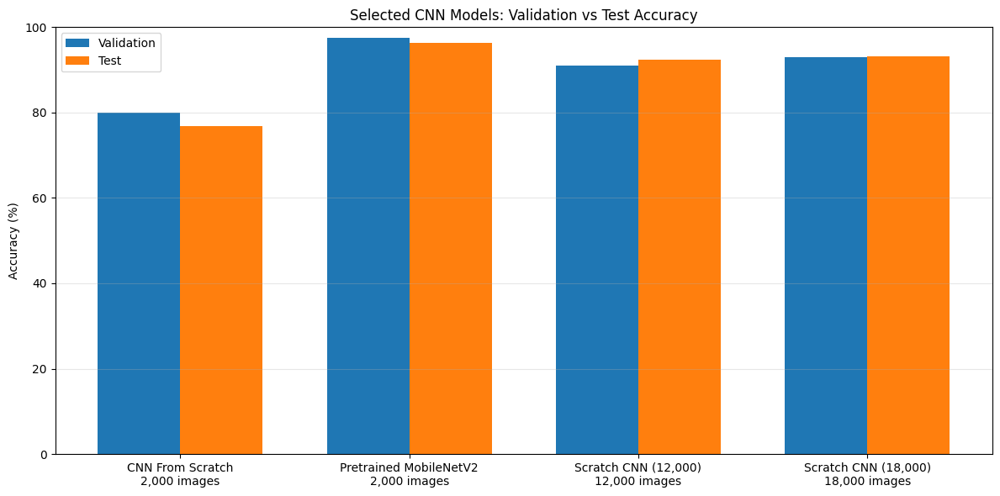


COMPLETE EVALUATION FINISHED
Files saved to: /kaggle/working/final_assignment_results


In [16]:

# ============================================================
# ASSIGNMENT 2 - COMPLETE EXPERIMENTAL EVALUATION
# Test 12K and 18K scratch CNNs
# Combine all 8 training experiments
# ============================================================

import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

root = Path("/kaggle/working")
extended = root / "extended_experiments"
output = root / "final_assignment_results"

output.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD FIXED VALIDATION AND TEST DATA
# ------------------------------------------------------------

manifest = pd.read_csv(
    root / "assignment2_manifest.csv"
)

val_df = manifest[
    manifest["split"] == "validation"
].copy().reset_index(drop=True)

test_df = manifest[
    manifest["split"] == "test"
].copy().reset_index(drop=True)

assert len(val_df) == 500
assert len(test_df) == 500

assert test_df["label"].value_counts().to_dict() == {
    "cat": 250,
    "dog": 250
}

# Verify no overlap with our largest training set
train_18k = pd.read_csv(
    extended / "train_18000.csv"
)

assert set(test_df["filename"]).isdisjoint(
    set(train_18k["filename"])
)

assert set(val_df["filename"]).isdisjoint(
    set(train_18k["filename"])
)

print("DATASET VERIFICATION: PASSED")
print("Original validation:", len(val_df))
print("Original test:", len(test_df))

# ------------------------------------------------------------
# 2. IMAGE DATA LOADER
# ------------------------------------------------------------

label_map = {"cat": 0, "dog": 1}

def make_dataset(frame):

    paths = frame["image_path"].astype(str).to_numpy()

    labels = frame["label"].map(
        label_map
    ).to_numpy(dtype="float32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    def load_image(path, label):

        image = tf.io.read_file(path)

        image = tf.image.decode_jpeg(
            image, channels=3
        )

        image = tf.image.resize(
            image, (150, 150)
        )

        return image, tf.expand_dims(label, -1)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

actual = test_df["label"].map(
    label_map
).to_numpy()

# ------------------------------------------------------------
# 3. TEST THE TWO EXTENDED SCRATCH CNNs
# ------------------------------------------------------------

extended_test_file = (
    output / "extended_test_results.csv"
)

if extended_test_file.exists():

    print("\nPreviously saved extended test results found.")
    extended_results = pd.read_csv(
        extended_test_file
    )

else:

    test_records = []

    for sample_size in [12000, 18000]:

        print("\n" + "=" * 50)
        print(f"TESTING SCRATCH CNN: {sample_size:,} IMAGES")
        print("=" * 50)

        folder = extended / f"cnn_{sample_size}"

        model_path = folder / "best_model.keras"
        summary_path = folder / "results_summary.csv"

        assert model_path.exists(), (
            f"Missing model: {model_path}"
        )

        assert summary_path.exists(), (
            f"Missing summary: {summary_path}"
        )

        summary = pd.read_csv(
            summary_path
        ).iloc[0]

        # Load the already-trained best model
        model = tf.keras.models.load_model(
            str(model_path)
        )

        # Verify original validation performance
        val_loss, val_accuracy = model.evaluate(
            val_ds,
            verbose=0
        )

        recorded_val_accuracy = float(
            summary["original_val_accuracy"]
        )

        print(
            "Recorded validation accuracy:",
            f"{recorded_val_accuracy * 100:.2f}%"
        )

        print(
            "Verified validation accuracy:",
            f"{val_accuracy * 100:.2f}%"
        )

        assert abs(
            val_accuracy - recorded_val_accuracy
        ) < 0.002, (
            "Validation result mismatch. "
            "Check the saved model and summary."
        )

        # FINAL TEST EVALUATION
        test_loss, test_accuracy = model.evaluate(
            test_ds,
            verbose=0
        )

        probabilities = model.predict(
            test_ds,
            verbose=0
        ).reshape(-1)

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        precision = precision_score(
            actual, predictions,
            zero_division=0
        )

        recall = recall_score(
            actual, predictions,
            zero_division=0
        )

        f1 = f1_score(
            actual, predictions,
            zero_division=0
        )

        record = {
            "Model": f"Scratch CNN ({sample_size:,})",
            "Training Images": sample_size,
            "Validation Accuracy (%)":
                round(val_accuracy * 100, 2),
            "Extended Validation Accuracy (%)":
                round(
                    float(summary["extended_val_accuracy"]) * 100,
                    2
                ),
            "Test Accuracy (%)":
                round(test_accuracy * 100, 2),
            "Test Loss": round(test_loss, 4),
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1 Score": round(f1, 4)
        }

        test_records.append(record)

        # Save individual predictions
        pd.DataFrame({
            "filename": test_df["filename"],
            "actual": actual,
            "predicted": predictions,
            "dog_probability": probabilities
        }).to_csv(
            output / f"scratch_{sample_size}_predictions.csv",
            index=False
        )

        # Confusion matrix
        cm = confusion_matrix(
            actual, predictions,
            labels=[0, 1]
        )

        display = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Cat", "Dog"]
        )

        display.plot(
            cmap="Blues",
            values_format="d"
        )

        plt.title(
            f"Scratch CNN - {sample_size:,} Images\n"
            "Final Test Confusion Matrix"
        )

        plt.tight_layout()

        plt.savefig(
            output / f"scratch_{sample_size}_test_cm.png",
            dpi=200
        )

        plt.show()

        print("\nTEST RESULTS")
        print(f"Accuracy: {test_accuracy * 100:.2f}%")
        print(f"Loss: {test_loss:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall: {recall:.4f}")
        print(f"F1 Score: {f1:.4f}")

    extended_results = pd.DataFrame(
        test_records
    )

    extended_results.to_csv(
        extended_test_file,
        index=False
    )

# ------------------------------------------------------------
# 4. COMBINE WITH ORIGINAL FINAL TEST RESULTS
# ------------------------------------------------------------

core_test_file = (
    output / "final_test_results.csv"
)

assert core_test_file.exists(), (
    "Original Q3/Q4C test results missing."
)

core_results = pd.read_csv(
    core_test_file
)

# Preserve the core results already measured
core_results = core_results[
    core_results["Model"].isin([
        "CNN From Scratch",
        "Pretrained MobileNetV2"
    ])
].copy()

assert len(core_results) == 2

overall_test = pd.concat(
    [core_results, extended_results],
    ignore_index=True
)

overall_test = overall_test.sort_values(
    "Training Images"
)

overall_test.to_csv(
    output / "overall_test_comparison.csv",
    index=False
)

print("\n" + "=" * 60)
print("FINAL TEST COMPARISON - ALL TESTED MODELS")
print("=" * 60)

print(
    overall_test[
        [
            "Model",
            "Training Images",
            "Validation Accuracy (%)",
            "Test Accuracy (%)",
            "Test Loss",
            "F1 Score"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 5. COMBINE ALL 8 VALIDATION EXPERIMENTS
# ------------------------------------------------------------

experiment_specs = [
    ("Scratch", 1000, root / "q1_full25", "best_val_accuracy"),
    ("Scratch", 1500, root / "q2_full25", "best_val_accuracy"),
    ("Scratch", 2000, root / "q3_full25", "best_val_accuracy"),
    ("Scratch", 12000, extended / "cnn_12000", "original_val_accuracy"),
    ("Scratch", 18000, extended / "cnn_18000", "original_val_accuracy"),
    ("Pretrained", 1000, root / "q4a_pretrained", "best_val_accuracy"),
    ("Pretrained", 1500, root / "q4b_pretrained", "best_val_accuracy"),
    ("Pretrained", 2000, root / "q4c_pretrained", "best_val_accuracy")
]

all_validation = []

for model_type, n, folder, metric in experiment_specs:

    data = pd.read_csv(
        folder / "results_summary.csv"
    ).iloc[0]

    all_validation.append({
        "Model Type": model_type,
        "Training Images": n,
        "Validation Accuracy (%)":
            round(float(data[metric]) * 100, 2)
    })

all_val_df = pd.DataFrame(all_validation)

all_val_df.to_csv(
    output / "all_8_validation_results.csv",
    index=False
)

print("\n" + "=" * 60)
print("ALL 8 TRAINING EXPERIMENTS")
print("=" * 60)

print(all_val_df.to_string(index=False))

# ------------------------------------------------------------
# 6. GRAPH: ALL 8 VALIDATION RESULTS
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for model_type in ["Scratch", "Pretrained"]:

    subset = all_val_df[
        all_val_df["Model Type"] == model_type
    ].sort_values("Training Images")

    plt.plot(
        subset["Training Images"],
        subset["Validation Accuracy (%)"],
        marker="o",
        linewidth=2,
        label=model_type
    )

plt.xlabel("Number of Training Images")
plt.ylabel("Validation Accuracy (%)")
plt.title(
    "CNN Performance vs Training Dataset Size"
)
plt.ylim(65, 100)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    output / "all_8_validation_comparison.png",
    dpi=200
)
plt.show()

# ------------------------------------------------------------
# 7. GRAPH: VALIDATION VS TEST PERFORMANCE
# ------------------------------------------------------------

labels = [
    f"{row['Model']}\n{int(row['Training Images']):,} images"
    for _, row in overall_test.iterrows()
]

x = np.arange(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - width / 2,
    overall_test["Validation Accuracy (%)"],
    width,
    label="Validation"
)

ax.bar(
    x + width / 2,
    overall_test["Test Accuracy (%)"],
    width,
    label="Test"
)

ax.set_xticks(x)
ax.set_xticklabels(labels)

ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.set_title(
    "Selected CNN Models: Validation vs Test Accuracy"
)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    output / "overall_validation_vs_test.png",
    dpi=200
)
plt.show()

print("\nCOMPLETE EVALUATION FINISHED")
print("Files saved to:", output)



NEW HOLDOUT VERIFIED
Total images: 2000
label
cat    1000
dog    1000
Name: count, dtype: int64
No overlap with earlier datasets: PASSED

EVALUATING: Scratch CNN - 2K


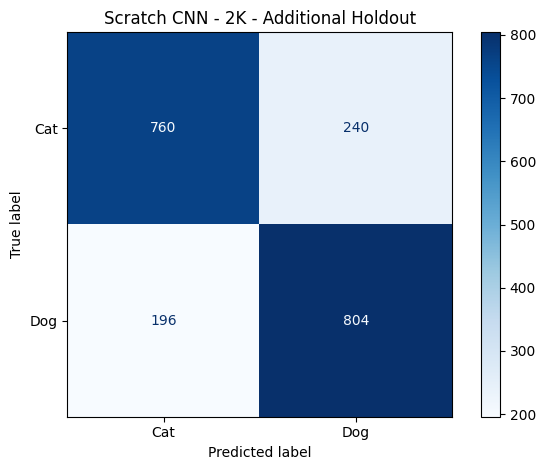

Accuracy: 78.20%
Loss: 0.4667

EVALUATING: Scratch CNN - 12K


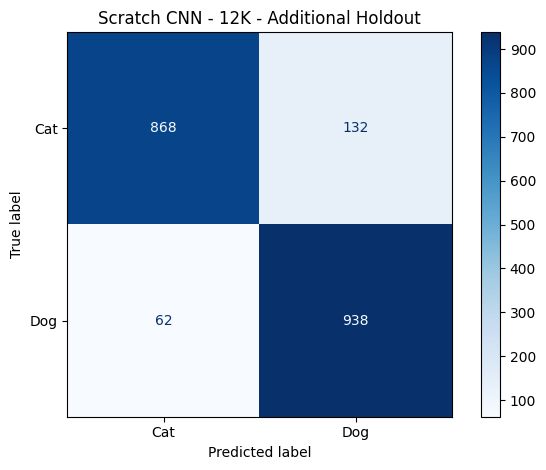

Accuracy: 90.30%
Loss: 0.2629

EVALUATING: Scratch CNN - 18K


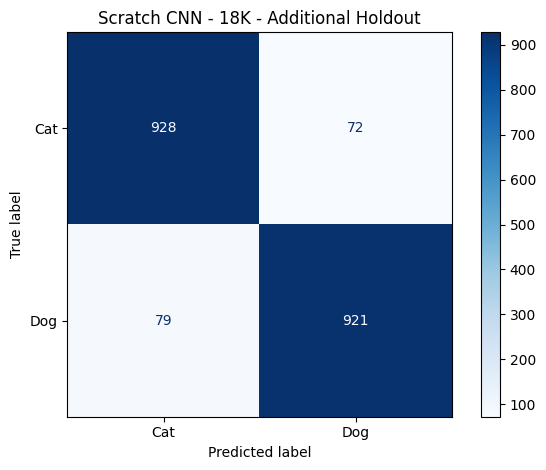

Accuracy: 92.45%
Loss: 0.1832

EVALUATING: Pretrained MobileNetV2 - 2K


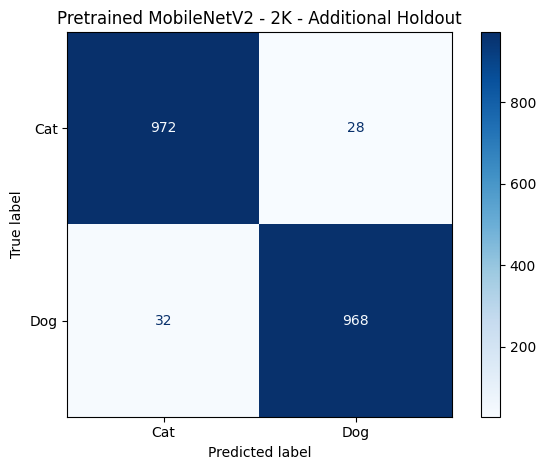

Accuracy: 97.00%
Loss: 0.0788

ADDITIONAL 2000-IMAGE HOLDOUT RESULTS
                      Model  Training Images  Holdout Images  Accuracy (%)   Loss  Precision  Recall  F1 Score  Incorrect Predictions
           Scratch CNN - 2K             2000            2000         78.20 0.4667     0.7701   0.804    0.7867                    436
          Scratch CNN - 12K            12000            2000         90.30 0.2629     0.8766   0.938    0.9063                    194
          Scratch CNN - 18K            18000            2000         92.45 0.1832     0.9275   0.921    0.9242                    151
Pretrained MobileNetV2 - 2K             2000            2000         97.00 0.0788     0.9719   0.968    0.9699                     60


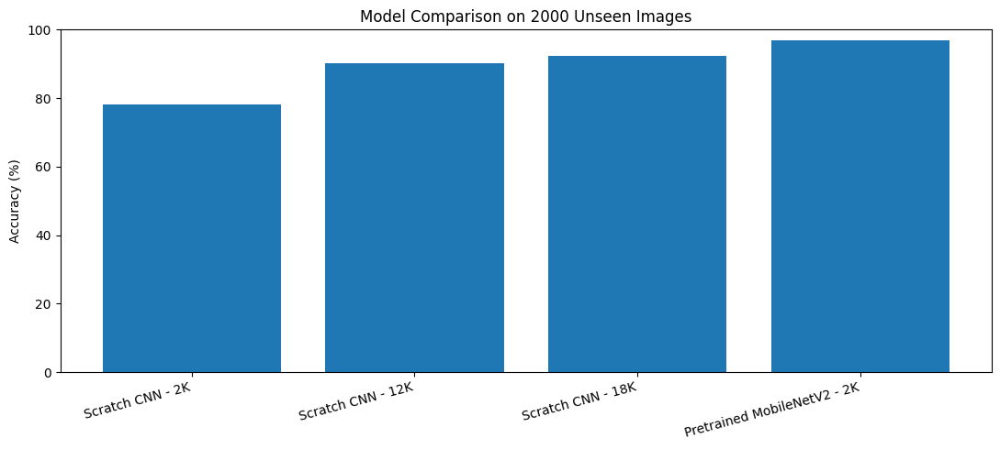


EVALUATION COMPLETE
Results saved in: /kaggle/working/additional_holdout_evaluation


In [17]:

# ======================================================
# ADDITIONAL INDEPENDENT HOLDOUT EVALUATION
# 2000 new images: 1000 cats + 1000 dogs
# Evaluate 4 existing saved models - NO RETRAINING
# ======================================================

import tensorflow as tf
import pandas as pd
import numpy as np
import random
import zipfile
import gc
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from io import BytesIO

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

root = Path("/kaggle/working")
extended = root / "extended_experiments"
output = root / "additional_holdout_evaluation"
output.mkdir(parents=True, exist_ok=True)

holdout_file = output / "holdout_2000.csv"

# ------------------------------------------------------
# 1. BUILD A NEW INDEPENDENT HOLDOUT (ONCE ONLY)
# ------------------------------------------------------

original = pd.read_csv(
    root / "assignment2_manifest.csv"
)

train_18k = pd.read_csv(
    extended / "train_18000.csv"
)

extra_val = pd.read_csv(
    extended / "extended_validation_2000.csv"
)

# All images used anywhere in earlier experiments
used = set()

for frame in [original, train_18k, extra_val]:
    used.update(
        Path(n).name for n in frame["filename"]
    )

if holdout_file.exists():
    print("Reusing previously saved holdout.")
    holdout = pd.read_csv(holdout_file)

else:
    archive_path = list(
        Path("/kaggle/input").rglob("train.zip")
    )[0]

    rng = random.Random(20261021)
    records = []

    with zipfile.ZipFile(archive_path) as archive:

        lookup = {
            Path(name).name: name
            for name in archive.namelist()
            if name.lower().endswith(".jpg")
        }

        for label in ["cat", "dog"]:

            candidates = sorted([
                name for name in lookup
                if name.startswith(label + ".")
                and name not in used
            ])

            rng.shuffle(candidates)

            selected = 0

            for name in candidates:

                if selected == 1000:
                    break

                try:
                    image_bytes = archive.read(
                        lookup[name]
                    )

                    with Image.open(
                        BytesIO(image_bytes)
                    ) as img:
                        img.verify()

                except Exception:
                    continue

                destination = (
                    output / "images" / label / name
                )

                destination.parent.mkdir(
                    parents=True,
                    exist_ok=True
                )

                destination.write_bytes(image_bytes)

                records.append({
                    "filename": lookup[name],
                    "label": label,
                    "image_path": str(destination)
                })

                selected += 1

            assert selected == 1000, (
                f"Not enough valid unused {label} images."
            )

    holdout = pd.DataFrame(records)
    holdout.to_csv(holdout_file, index=False)

# ------------------------------------------------------
# 2. VERIFY INDEPENDENCE
# ------------------------------------------------------

assert len(holdout) == 2000

assert holdout["label"].value_counts().to_dict() == {
    "cat": 1000,
    "dog": 1000
}

assert set(
    Path(n).name for n in holdout["filename"]
).isdisjoint(used)

assert holdout["image_path"].map(
    lambda p: Path(p).is_file()
).all()

print("\nNEW HOLDOUT VERIFIED")
print("Total images:", len(holdout))
print(holdout["label"].value_counts())
print("No overlap with earlier datasets: PASSED")

# ------------------------------------------------------
# 3. PREPARE DATA FOR EXISTING MODELS
# ------------------------------------------------------

label_map = {"cat": 0, "dog": 1}

paths = holdout["image_path"].astype(str).to_numpy()
labels = holdout["label"].map(
    label_map
).to_numpy(dtype="float32")

ds = tf.data.Dataset.from_tensor_slices(
    (paths, labels)
)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(
        image, channels=3
    )
    image = tf.image.resize(
        image, (150, 150)
    )
    return image, tf.expand_dims(label, -1)

holdout_ds = (
    ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

actual = labels.astype(int)

# ------------------------------------------------------
# 4. EVALUATE EXISTING SAVED MODELS
# ------------------------------------------------------

models_to_evaluate = [
    (
        "Scratch CNN - 2K",
        root / "q3_full25/best_model.keras",
        2000
    ),
    (
        "Scratch CNN - 12K",
        extended / "cnn_12000/best_model.keras",
        12000
    ),
    (
        "Scratch CNN - 18K",
        extended / "cnn_18000/best_model.keras",
        18000
    ),
    (
        "Pretrained MobileNetV2 - 2K",
        root / "q4c_pretrained/best_model.keras",
        2000
    )
]

results = []

for name, model_path, training_size in models_to_evaluate:

    assert model_path.exists(), (
        f"Missing saved model: {model_path}"
    )

    print("\nEVALUATING:", name)

    tf.keras.backend.clear_session()

    model = tf.keras.models.load_model(
        str(model_path)
    )

    loss, accuracy = model.evaluate(
        holdout_ds, verbose=0
    )

    probabilities = model.predict(
        holdout_ds, verbose=0
    ).reshape(-1)

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    result = {
        "Model": name,
        "Training Images": training_size,
        "Holdout Images": 2000,
        "Accuracy (%)": round(
            accuracy * 100, 2
        ),
        "Loss": round(loss, 4),
        "Precision": round(
            precision_score(actual, predictions), 4
        ),
        "Recall": round(
            recall_score(actual, predictions), 4
        ),
        "F1 Score": round(
            f1_score(actual, predictions), 4
        ),
        "Incorrect Predictions": int(
            np.sum(predictions != actual)
        )
    }

    results.append(result)

    cm = confusion_matrix(
        actual, predictions, labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Cat", "Dog"]
    )

    display.plot(
        cmap="Blues",
        values_format="d"
    )

    plt.title(name + " - Additional Holdout")
    plt.tight_layout()

    safe_name = name.lower().replace(
        " ", "_"
    ).replace("-", "")

    plt.savefig(
        output / f"{safe_name}_confusion_matrix.png",
        dpi=180
    )

    plt.show()

    print("Accuracy:", f"{accuracy * 100:.2f}%")
    print("Loss:", f"{loss:.4f}")

    del model
    gc.collect()

# ------------------------------------------------------
# 5. FINAL COMPARISON
# ------------------------------------------------------

results_df = pd.DataFrame(results)

results_df.to_csv(
    output / "additional_holdout_results.csv",
    index=False
)

print("\n====================================")
print("ADDITIONAL 2000-IMAGE HOLDOUT RESULTS")
print("====================================")

print(results_df.to_string(index=False))

# Accuracy comparison chart
plt.figure(figsize=(11, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy (%)"]
)

plt.ylabel("Accuracy (%)")
plt.title("Model Comparison on 2000 Unseen Images")
plt.ylim(0, 100)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.savefig(
    output / "holdout_comparison.png",
    dpi=200
)

plt.show()

print("\nEVALUATION COMPLETE")
print("Results saved in:", output)



TRAINING WITH DROPOUT = 0.0
Epoch 1/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.5270 - loss: 0.6922 - val_accuracy: 0.5940 - val_loss: 0.6799
Epoch 2/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.5740 - loss: 0.6740 - val_accuracy: 0.6760 - val_loss: 0.6374
Epoch 3/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.6550 - loss: 0.6223 - val_accuracy: 0.6480 - val_loss: 0.6174
Epoch 4/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.6805 - loss: 0.5933 - val_accuracy: 0.6840 - val_loss: 0.6036
Epoch 5/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.7010 - loss: 0.5695 - val_accuracy: 0.6900 - val_loss: 0.5851
Epoch 6/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.7220 - loss: 0.5552 - val_accuracy: 0.7040 - val_loss: 0.5791
Epoch 7/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.7300 - loss: 0.5468 - val_accuracy: 0.6860 - val_loss: 0.6220
Epoch 8/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.7270 - loss: 0.54

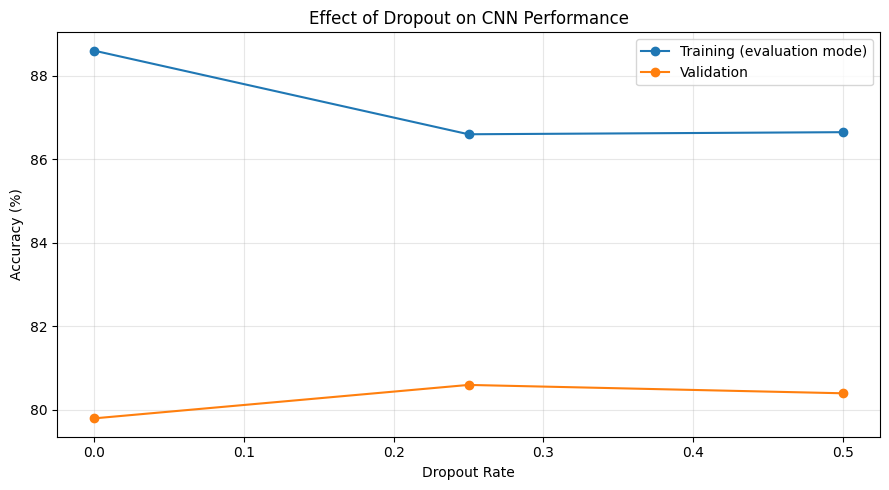

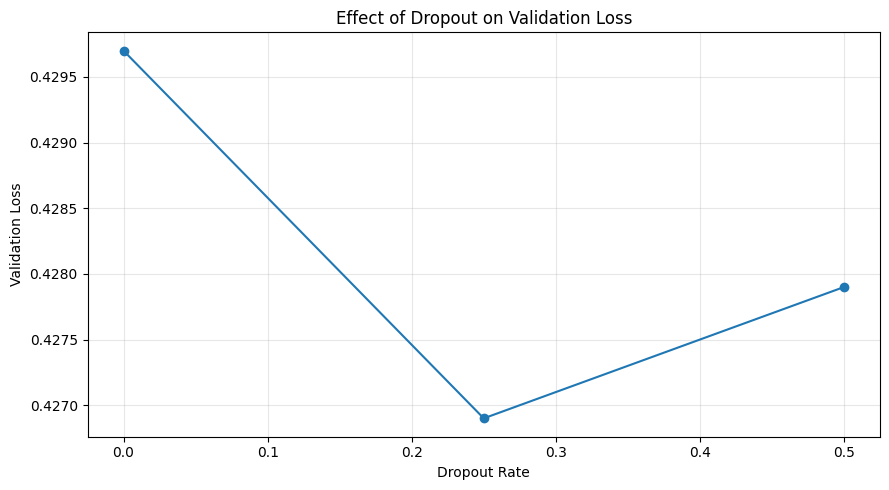


DROPOUT EXPERIMENT COMPLETE
Results saved in: /kaggle/working/dropout_experiments


In [18]:

# =====================================================
# ADDITIONAL EXPERIMENT: DROPOUT COMPARISON
# CNN FROM SCRATCH - 2000 TRAINING IMAGES
# Dropout rates: 0.0, 0.25, 0.5
# 25 epochs each
# =====================================================

import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

root = Path("/kaggle/working")
output = root / "dropout_experiments"
output.mkdir(parents=True, exist_ok=True)

# 1. LOAD THE SAME TRAINING AND VALIDATION DATA

train_df = pd.read_csv(
    root / "q3_full25/q3_training_selection.csv"
)

manifest = pd.read_csv(
    root / "assignment2_manifest.csv"
)

val_df = manifest[
    manifest["split"] == "validation"
].copy()

assert len(train_df) == 2000
assert len(val_df) == 500

assert set(train_df["filename"]).isdisjoint(
    set(val_df["filename"])
)

# 2. DATA PIPELINE

label_map = {"cat": 0, "dog": 1}

def make_dataset(frame, training=False):

    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label"].map(
        label_map
    ).to_numpy(dtype="float32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            len(frame),
            seed=42,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):

        image = tf.io.read_file(path)
        image = tf.image.decode_jpeg(
            image, channels=3
        )
        image = tf.image.resize(
            image, (150, 150)
        )

        return image, tf.expand_dims(label, -1)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

# 3. BUILD CNN WITH VARIABLE DROPOUT

def build_model(dropout_rate):

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(150, 150, 3)
        ),

        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.06),
        tf.keras.layers.RandomZoom(0.10),

        tf.keras.layers.Rescaling(1.0 / 255),

        tf.keras.layers.Conv2D(
            32, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(
            64, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(
            128, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(
            128, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Flatten(),

        tf.keras.layers.Dense(
            128, activation="relu"
        ),

        # VARIABLE DROPOUT
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(
            1, activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0003
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# 4. RUN THREE INDEPENDENT EXPERIMENTS

dropout_rates = [0.0, 0.25, 0.5]

results = []

for rate in dropout_rates:

    print("\n" + "=" * 45)
    print(f"TRAINING WITH DROPOUT = {rate}")
    print("=" * 45)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    folder = output / f"dropout_{str(rate).replace('.', 'p')}"
    folder.mkdir(parents=True, exist_ok=True)

    train_ds = make_dataset(train_df, training=True)
    val_ds = make_dataset(val_df)

    model = build_model(rate)

    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        str(folder / "best_model.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=0
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=25,
        callbacks=[checkpoint],
        verbose=1
    )

    history_df = pd.DataFrame(history.history)

    history_df.to_csv(
        folder / "training_history.csv",
        index=False
    )

    best_epoch = (
        history_df["val_loss"].idxmin() + 1
    )

    best_model = tf.keras.models.load_model(
        str(folder / "best_model.keras")
    )

    # Evaluate using the best saved checkpoint
    val_loss, val_accuracy = best_model.evaluate(
        val_ds,
        verbose=0
    )

    # Fair training evaluation: dropout and augmentation off
    train_eval_ds = make_dataset(
        train_df, training=False
    )

    train_loss, train_accuracy = best_model.evaluate(
        train_eval_ds,
        verbose=0
    )

    results.append({
        "Dropout Rate": rate,
        "Best Epoch": best_epoch,
        "Training Accuracy (%)":
            round(train_accuracy * 100, 2),
        "Validation Accuracy (%)":
            round(val_accuracy * 100, 2),
        "Validation Loss":
            round(val_loss, 4),
        "Accuracy Gap (points)":
            round(
                (train_accuracy - val_accuracy) * 100,
                2
            )
    })

    print(f"\nDROPOUT {rate} RESULTS")
    print("Best epoch:", best_epoch)
    print(
        "Training accuracy (evaluation mode):",
        f"{train_accuracy * 100:.2f}%"
    )
    print(
        "Validation accuracy:",
        f"{val_accuracy * 100:.2f}%"
    )
    print(
        "Validation loss:",
        f"{val_loss:.4f}"
    )

# 5. FINAL COMPARISON

results_df = pd.DataFrame(results)

results_df.to_csv(
    output / "dropout_comparison.csv",
    index=False
)

print("\n====================================")
print("DROPOUT EXPERIMENT - FINAL COMPARISON")
print("====================================")

print(results_df.to_string(index=False))

# 6. GRAPH: ACCURACY VS DROPOUT RATE

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["Dropout Rate"],
    results_df["Training Accuracy (%)"],
    marker="o",
    label="Training (evaluation mode)"
)

plt.plot(
    results_df["Dropout Rate"],
    results_df["Validation Accuracy (%)"],
    marker="o",
    label="Validation"
)

plt.xlabel("Dropout Rate")
plt.ylabel("Accuracy (%)")
plt.title("Effect of Dropout on CNN Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    output / "dropout_accuracy_comparison.png",
    dpi=200
)

plt.show()

# 7. GRAPH: VALIDATION LOSS VS DROPOUT

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["Dropout Rate"],
    results_df["Validation Loss"],
    marker="o"
)

plt.xlabel("Dropout Rate")
plt.ylabel("Validation Loss")
plt.title("Effect of Dropout on Validation Loss")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    output / "dropout_loss_comparison.png",
    dpi=200
)

plt.show()

print("\nDROPOUT EXPERIMENT COMPLETE")
print("Results saved in:", output)



NEW HOLDOUT VERIFIED
Images: 2000
label
cat    1000
dog    1000
Name: count, dtype: int64
No overlap: PASSED

DROPOUT - INDEPENDENT TEST RESULTS
 Dropout Rate  Test Images  Test Accuracy (%)  Test Loss  Precision  Recall  F1 Score  Incorrect
         0.00         2000              78.85     0.4640     0.7905   0.785    0.7878        423
         0.25         2000              78.65     0.4586     0.7716   0.814    0.7922        427
         0.50         2000              78.55     0.4673     0.7732   0.808    0.7902        429


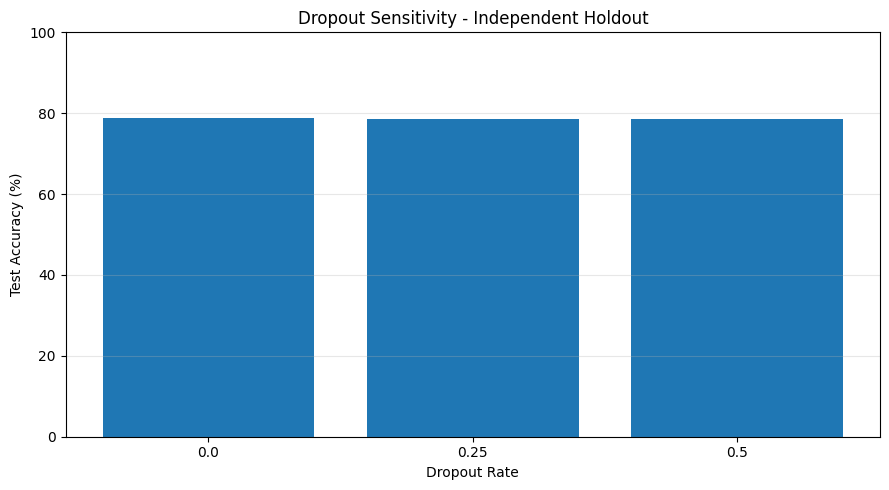


DROPOUT EVALUATION COMPLETE


In [19]:

# ============================================================
# DROPOUT EXPERIMENT - INDEPENDENT HOLDOUT TEST
# Rates: 0.0, 0.25, 0.5
# No retraining or further optimization
# ============================================================

import tensorflow as tf
import pandas as pd
import numpy as np
import random
import zipfile
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from io import BytesIO
from sklearn.metrics import precision_score, recall_score, f1_score

root = Path("/kaggle/working")
output = root / "dropout_experiments"
holdout_dir = output / "new_holdout"
holdout_dir.mkdir(parents=True, exist_ok=True)

holdout_csv = output / "unused_holdout.csv"
results_csv = output / "unused_holdout_results.csv"

# 1. IDENTIFY ALL PREVIOUSLY USED IMAGES

previous_files = [
    root / "assignment2_manifest.csv",
    root / "extended_experiments/train_18000.csv",
    root / "extended_experiments/extended_validation_2000.csv",
    root / "additional_holdout_evaluation/holdout_2000.csv"
]

used = set()

for file in previous_files:
    assert file.exists(), f"Missing split file: {file}"
    frame = pd.read_csv(file)
    used.update(
        Path(str(n)).name
        for n in frame["filename"]
    )

# 2. CREATE A NEW HOLDOUT ONLY ONCE

if holdout_csv.exists():

    holdout = pd.read_csv(holdout_csv)
    print("Reusing existing holdout.")

else:

    zip_path = list(
        Path("/kaggle/input").rglob("train.zip")
    )[0]

    rng = random.Random(98765)
    records = []

    with zipfile.ZipFile(zip_path) as archive:

        lookup = {
            Path(n).name: n
            for n in archive.namelist()
            if n.lower().endswith(".jpg")
        }

        for label in ["cat", "dog"]:

            candidates = sorted([
                n for n in lookup
                if n.startswith(label + ".")
                and n not in used
            ])

            rng.shuffle(candidates)
            count = 0

            for name in candidates:

                if count >= 1000:
                    break

                data = archive.read(lookup[name])

                try:
                    with Image.open(BytesIO(data)) as img:
                        img.verify()
                except Exception:
                    continue

                destination = holdout_dir / label / name
                destination.parent.mkdir(
                    parents=True, exist_ok=True
                )
                destination.write_bytes(data)

                records.append({
                    "filename": lookup[name],
                    "label": label,
                    "image_path": str(destination)
                })

                count += 1

    holdout = pd.DataFrame(records)

    # Use a balanced number of valid images
    counts = holdout["label"].value_counts()
    n_per_class = int(counts.min())

    assert n_per_class >= 500, (
        "Not enough unused valid images for testing."
    )

    holdout = (
        holdout.groupby("label", group_keys=False)
        .head(n_per_class)
        .reset_index(drop=True)
    )

    holdout.to_csv(holdout_csv, index=False)

# 3. VERIFY THE HOLDOUT

assert len(holdout) == holdout["filename"].nunique()

assert set(
    Path(str(n)).name for n in holdout["filename"]
).isdisjoint(used)

assert holdout["label"].value_counts().nunique() == 1

assert holdout["image_path"].map(
    lambda p: Path(p).is_file()
).all()

print("\nNEW HOLDOUT VERIFIED")
print("Images:", len(holdout))
print(holdout["label"].value_counts())
print("No overlap: PASSED")

# 4. IMAGE PIPELINE

labels = holdout["label"].map({
    "cat": 0,
    "dog": 1
}).to_numpy(dtype="float32")

paths = holdout["image_path"].astype(str).to_numpy()

ds = tf.data.Dataset.from_tensor_slices(
    (paths, labels)
)

def load_image(path, label):

    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(
        image, channels=3
    )
    image = tf.image.resize(
        image, (150, 150)
    )

    return image, tf.expand_dims(label, -1)

test_ds = (
    ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

# 5. EVALUATE ALL THREE PRE-SPECIFIED MODELS

if results_csv.exists():

    print("\nExisting test results found.")
    results_df = pd.read_csv(results_csv)

else:

    results = []

    for rate in [0.0, 0.25, 0.5]:

        folder = output / (
            f"dropout_{str(rate).replace('.', 'p')}"
        )

        model_path = folder / "best_model.keras"

        assert model_path.exists(), (
            f"Missing model: {model_path}"
        )

        tf.keras.backend.clear_session()

        model = tf.keras.models.load_model(
            str(model_path)
        )

        loss, accuracy = model.evaluate(
            test_ds, verbose=0
        )

        probabilities = model.predict(
            test_ds, verbose=0
        ).reshape(-1)

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        actual = labels.astype(int)

        results.append({
            "Dropout Rate": rate,
            "Test Images": len(holdout),
            "Test Accuracy (%)":
                round(accuracy * 100, 2),
            "Test Loss": round(loss, 4),
            "Precision": round(
                precision_score(actual, predictions), 4
            ),
            "Recall": round(
                recall_score(actual, predictions), 4
            ),
            "F1 Score": round(
                f1_score(actual, predictions), 4
            ),
            "Incorrect": int(
                np.sum(predictions != actual)
            )
        })

    results_df = pd.DataFrame(results)
    results_df.to_csv(results_csv, index=False)

# 6. DISPLAY RESULTS

print("\n====================================")
print("DROPOUT - INDEPENDENT TEST RESULTS")
print("====================================")

print(results_df.to_string(index=False))

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Dropout Rate"].astype(str),
    results_df["Test Accuracy (%)"]
)

plt.xlabel("Dropout Rate")
plt.ylabel("Test Accuracy (%)")
plt.title("Dropout Sensitivity - Independent Holdout")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    output / "dropout_holdout_comparison.png",
    dpi=200
)

plt.show()

print("\nDROPOUT EVALUATION COMPLETE")



DROPOUT=0.0, SEED=17
Validation accuracy: 80.40%
Validation loss: 0.4353
Best epoch: 25

DROPOUT=0.0, SEED=42
Validation accuracy: 79.60%
Validation loss: 0.4140
Best epoch: 24

DROPOUT=0.0, SEED=123
Validation accuracy: 79.20%
Validation loss: 0.4208
Best epoch: 25

DROPOUT=0.25, SEED=17
Validation accuracy: 80.40%
Validation loss: 0.4415
Best epoch: 23

DROPOUT=0.25, SEED=42
Validation accuracy: 79.60%
Validation loss: 0.4518
Best epoch: 24

DROPOUT=0.25, SEED=123
Validation accuracy: 79.60%
Validation loss: 0.4441
Best epoch: 24

DROPOUT=0.5, SEED=17
Validation accuracy: 77.60%
Validation loss: 0.4377
Best epoch: 25

DROPOUT=0.5, SEED=42
Validation accuracy: 79.60%
Validation loss: 0.4251
Best epoch: 24

DROPOUT=0.5, SEED=123
Validation accuracy: 81.00%
Validation loss: 0.4182
Best epoch: 24

===== INDIVIDUAL SEED RESULTS =====
 Dropout  Seed  Best Epoch  Training Accuracy (%)  Validation Accuracy (%)  Validation Loss  Accuracy Gap
    0.00    17          25                  89.15 

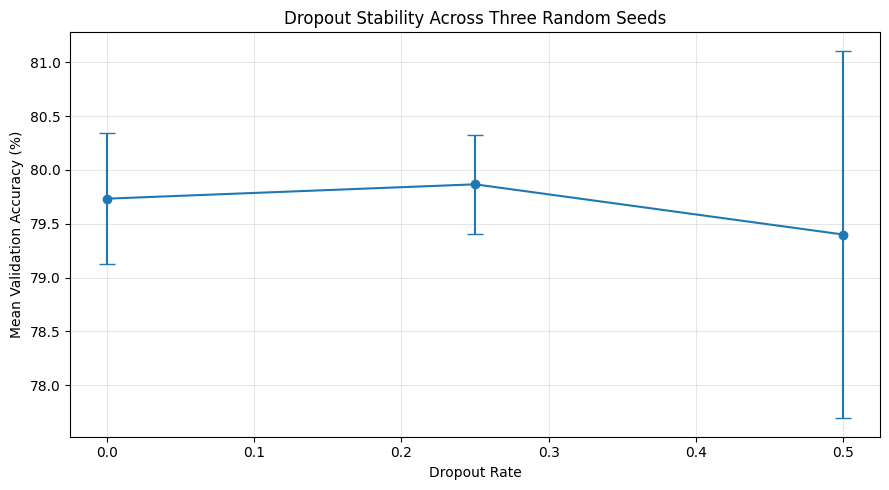

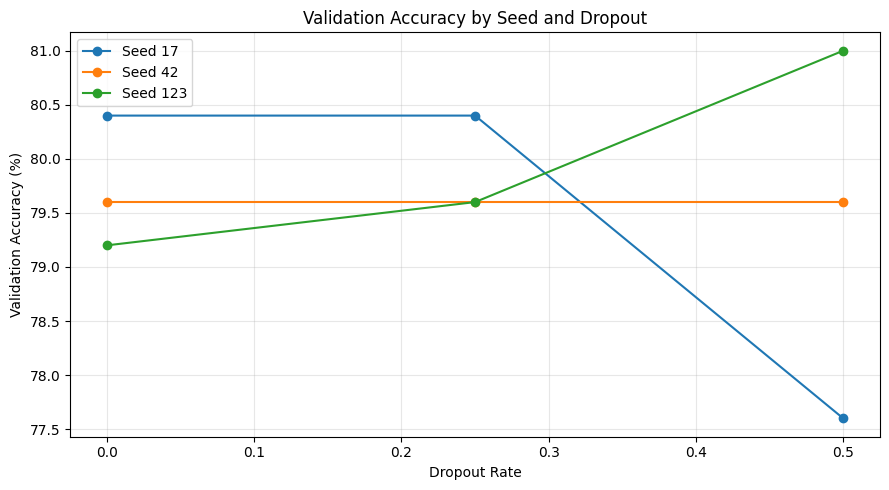


NINE EXPERIMENTS COMPLETE
Results saved to: /kaggle/working/dropout_seed_study


In [20]:

# =========================================================
# EXPERIMENT 1: DROPOUT STABILITY ACROSS RANDOM SEEDS
# 3 dropout rates x 3 predetermined seeds = 9 runs
# Scratch CNN, 2000 images, 25 epochs each
# =========================================================

import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gc
from pathlib import Path

root = Path("/kaggle/working")
output = root / "dropout_seed_study"
output.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(
    root / "q3_full25/q3_training_selection.csv"
)
manifest = pd.read_csv(
    root / "assignment2_manifest.csv"
)
val_df = manifest[
    manifest["split"] == "validation"
].copy()

assert len(train_df) == 2000
assert len(val_df) == 500
assert set(train_df["filename"]).isdisjoint(
    set(val_df["filename"])
)

# Predetermined settings
SEEDS = [17, 42, 123]
DROPOUT_RATES = [0.0, 0.25, 0.5]
EPOCHS = 25

label_map = {"cat": 0, "dog": 1}

# ---------------------------------------------------------
# DATA LOADER
# ---------------------------------------------------------

def make_dataset(frame, training=False, seed=42):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label"].map(
        label_map
    ).to_numpy(dtype="float32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            len(frame),
            seed=seed,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.image.decode_jpeg(
            image, channels=3
        )
        image = tf.image.resize(
            image, (150, 150)
        )
        return image, tf.expand_dims(label, -1)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    options = tf.data.Options()
    options.deterministic = True
    ds = ds.with_options(options)

    return ds.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

# ---------------------------------------------------------
# SAME CNN AS OUR PREVIOUS DROPOUT EXPERIMENT
# ---------------------------------------------------------

def build_cnn(rate):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(150, 150, 3)),
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.06),
        tf.keras.layers.RandomZoom(0.10),
        tf.keras.layers.Rescaling(1.0 / 255),

        tf.keras.layers.Conv2D(
            32, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(
            64, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(
            128, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(
            128, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(
            128, activation="relu"
        ),
        tf.keras.layers.Dropout(rate),
        tf.keras.layers.Dense(
            1, activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0003
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# ---------------------------------------------------------
# RUN ALL NINE EXPERIMENTS
# ---------------------------------------------------------

results = []

for rate in DROPOUT_RATES:
    for seed in SEEDS:

        print("\n" + "=" * 50)
        print(f"DROPOUT={rate}, SEED={seed}")
        print("=" * 50)

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)

        folder = output / f"dropout_{rate}_seed_{seed}"
        folder.mkdir(parents=True, exist_ok=True)

        train_ds = make_dataset(
            train_df, training=True, seed=seed
        )
        train_eval_ds = make_dataset(train_df)
        val_ds = make_dataset(val_df)

        model = build_cnn(rate)

        checkpoint = tf.keras.callbacks.ModelCheckpoint(
            str(folder / "best_model.keras"),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=0
        )

        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS,
            callbacks=[checkpoint],
            verbose=0
        )

        history_df = pd.DataFrame(history.history)
        history_df.to_csv(
            folder / "training_history.csv",
            index=False
        )

        best_epoch = history_df["val_loss"].idxmin() + 1

        best_model = tf.keras.models.load_model(
            str(folder / "best_model.keras")
        )

        val_loss, val_acc = best_model.evaluate(
            val_ds, verbose=0
        )

        train_loss, train_acc = best_model.evaluate(
            train_eval_ds, verbose=0
        )

        result = {
            "Dropout": rate,
            "Seed": seed,
            "Best Epoch": best_epoch,
            "Training Accuracy (%)": train_acc * 100,
            "Validation Accuracy (%)": val_acc * 100,
            "Validation Loss": val_loss,
            "Accuracy Gap": (train_acc - val_acc) * 100
        }

        results.append(result)

        print(
            f"Validation accuracy: {val_acc * 100:.2f}%"
        )
        print(f"Validation loss: {val_loss:.4f}")
        print(f"Best epoch: {best_epoch}")

        pd.DataFrame([result]).to_csv(
            folder / "result.csv",
            index=False
        )

        del model, best_model
        gc.collect()

# ---------------------------------------------------------
# RESULTS BY INDIVIDUAL SEED
# ---------------------------------------------------------

results_df = pd.DataFrame(results)
results_df.to_csv(
    output / "all_seed_results.csv",
    index=False
)

print("\n===== INDIVIDUAL SEED RESULTS =====")
print(results_df.round(4).to_string(index=False))

# ---------------------------------------------------------
# MEAN AND STANDARD DEVIATION
# ---------------------------------------------------------

summary = results_df.groupby("Dropout").agg(
    Mean_Accuracy=("Validation Accuracy (%)", "mean"),
    Std_Accuracy=("Validation Accuracy (%)", "std"),
    Mean_Loss=("Validation Loss", "mean"),
    Std_Loss=("Validation Loss", "std"),
    Mean_Gap=("Accuracy Gap", "mean")
).reset_index()

summary = summary.round(4)

summary.to_csv(
    output / "seed_stability_summary.csv",
    index=False
)

print("\n===== SEED STABILITY SUMMARY =====")
print(summary.to_string(index=False))

# ---------------------------------------------------------
# GRAPH: MEAN ACCURACY +/- STANDARD DEVIATION
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.errorbar(
    summary["Dropout"],
    summary["Mean_Accuracy"],
    yerr=summary["Std_Accuracy"],
    fmt="o-",
    capsize=6
)

plt.xlabel("Dropout Rate")
plt.ylabel("Mean Validation Accuracy (%)")
plt.title("Dropout Stability Across Three Random Seeds")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    output / "dropout_seed_stability.png",
    dpi=200
)
plt.show()

# ---------------------------------------------------------
# GRAPH: INDIVIDUAL SEEDS
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

for seed in SEEDS:
    subset = results_df[
        results_df["Seed"] == seed
    ].sort_values("Dropout")

    plt.plot(
        subset["Dropout"],
        subset["Validation Accuracy (%)"],
        marker="o",
        label=f"Seed {seed}"
    )

plt.xlabel("Dropout Rate")
plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy by Seed and Dropout")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    output / "individual_seed_comparison.png",
    dpi=200
)
plt.show()

print("\nNINE EXPERIMENTS COMPLETE")
print("Results saved to:", output)


scratch_2k: 436 errors
scratch_12k: 194 errors
scratch_18k: 151 errors
pretrained_2k: 60 errors

===== MODEL ERROR SUMMARY =====
        Model  Correct  Incorrect  Accuracy (%)
   scratch_2k     1564        436         78.20
  scratch_12k     1806        194         90.30
  scratch_18k     1849        151         92.45
pretrained_2k     1940         60         97.00

===== ERROR OVERLAP =====
Both 18K scratch and pretrained wrong: 23
Pretrained correct, 18K scratch wrong: 128
18K scratch correct, pretrained wrong: 37
All four models wrong: 15


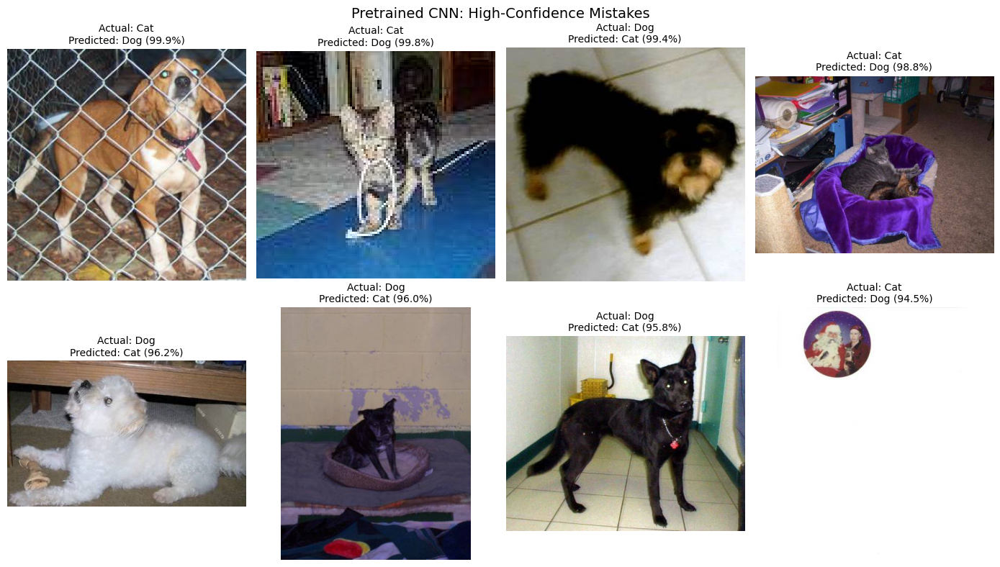

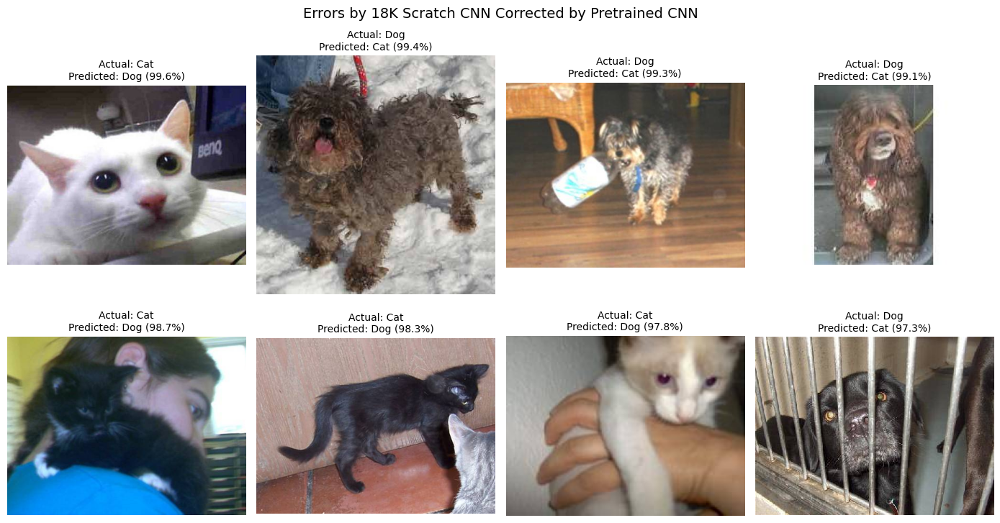

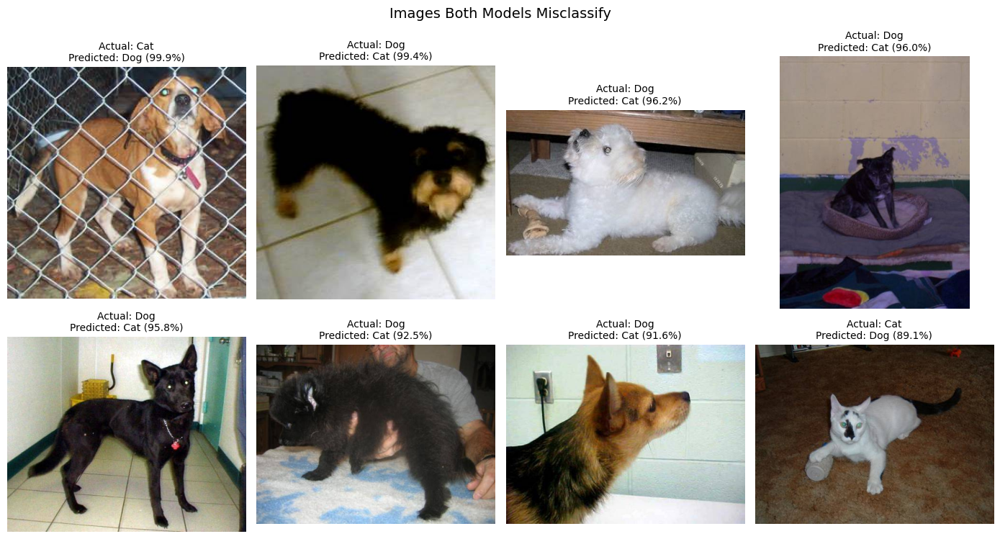


MISCLASSIFICATION ANALYSIS COMPLETE
Results saved in: /kaggle/working/misclassification_study


In [21]:

# =========================================================
# EXPERIMENT 2: MISCLASSIFICATION ANALYSIS
# Compare errors made by four saved CNN models
# Existing 2000-image independent holdout
# NO RETRAINING
# =========================================================

import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gc

from pathlib import Path
from PIL import Image

root = Path("/kaggle/working")
output = root / "misclassification_study"
output.mkdir(parents=True, exist_ok=True)

holdout = pd.read_csv(
    root / "additional_holdout_evaluation/holdout_2000.csv"
).reset_index(drop=True)

assert len(holdout) == 2000
assert holdout["filename"].is_unique
assert holdout["label"].value_counts().to_dict() == {
    "cat": 1000, "dog": 1000
}

# Confirm images exist and were not in largest training set
train_18k = pd.read_csv(
    root / "extended_experiments/train_18000.csv"
)

assert set(holdout["filename"]).isdisjoint(
    set(train_18k["filename"])
)

assert holdout["image_path"].map(
    lambda p: Path(p).is_file()
).all()

label_map = {"cat": 0, "dog": 1}
actual = holdout["label"].map(
    label_map
).to_numpy()

# ---------------------------------------------------------
# LOAD IMAGES
# ---------------------------------------------------------

paths = holdout["image_path"].astype(str).to_numpy()

ds = tf.data.Dataset.from_tensor_slices(paths)

def load_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(
        image, channels=3
    )
    return tf.image.resize(image, (150, 150))

ds = ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(32).prefetch(tf.data.AUTOTUNE)

# ---------------------------------------------------------
# EXISTING SAVED MODELS
# ---------------------------------------------------------

models = {
    "scratch_2k":
        root / "q3_full25/best_model.keras",

    "scratch_12k":
        root / "extended_experiments/cnn_12000/best_model.keras",

    "scratch_18k":
        root / "extended_experiments/cnn_18000/best_model.keras",

    "pretrained_2k":
        root / "q4c_pretrained/best_model.keras"
}

analysis = holdout.copy()
summary = []

# ---------------------------------------------------------
# GENERATE PREDICTIONS FOR EACH MODEL
# ---------------------------------------------------------

for name, path in models.items():

    assert path.exists(), f"Missing model: {path}"

    tf.keras.backend.clear_session()

    model = tf.keras.models.load_model(str(path))

    probability = model.predict(
        ds, verbose=0
    ).reshape(-1)

    predicted = (probability >= 0.5).astype(int)

    wrong = predicted != actual

    # Confidence in whichever label was predicted
    confidence = np.where(
        predicted == 1,
        probability,
        1 - probability
    )

    analysis[f"prediction_{name}"] = predicted
    analysis[f"probability_{name}"] = probability
    analysis[f"confidence_{name}"] = confidence
    analysis[f"wrong_{name}"] = wrong

    summary.append({
        "Model": name,
        "Correct": int((~wrong).sum()),
        "Incorrect": int(wrong.sum()),
        "Accuracy (%)": round(
            (~wrong).mean() * 100, 2
        )
    })

    print(
        f"{name}: {int(wrong.sum())} errors"
    )

    del model
    gc.collect()

# ---------------------------------------------------------
# SAVE COMPLETE PREDICTION TABLE
# ---------------------------------------------------------

analysis.to_csv(
    output / "all_predictions.csv",
    index=False
)

summary_df = pd.DataFrame(summary)
summary_df.to_csv(
    output / "error_summary.csv",
    index=False
)

print("\n===== MODEL ERROR SUMMARY =====")
print(summary_df.to_string(index=False))

# ---------------------------------------------------------
# IDENTIFY IMPORTANT ERROR CATEGORIES
# ---------------------------------------------------------

# Errors made by BOTH the largest scratch model
# and the pretrained model
both_wrong = analysis[
    analysis["wrong_scratch_18k"] &
    analysis["wrong_pretrained_2k"]
].copy()

# Scratch gets it wrong, pretrained gets it right
pretrained_fixes = analysis[
    analysis["wrong_scratch_18k"] &
    ~analysis["wrong_pretrained_2k"]
].copy()

# Pretrained gets it wrong, scratch gets it right
scratch_fixes = analysis[
    ~analysis["wrong_scratch_18k"] &
    analysis["wrong_pretrained_2k"]
].copy()

# Every model gets the same image wrong
all_wrong_columns = [
    f"wrong_{name}" for name in models
]

all_models_wrong = analysis[
    analysis[all_wrong_columns].all(axis=1)
].copy()

print("\n===== ERROR OVERLAP =====")
print("Both 18K scratch and pretrained wrong:",
      len(both_wrong))
print("Pretrained correct, 18K scratch wrong:",
      len(pretrained_fixes))
print("18K scratch correct, pretrained wrong:",
      len(scratch_fixes))
print("All four models wrong:",
      len(all_models_wrong))

both_wrong.to_csv(
    output / "both_models_wrong.csv", index=False
)

pretrained_fixes.to_csv(
    output / "pretrained_fixes.csv", index=False
)

scratch_fixes.to_csv(
    output / "scratch_fixes.csv", index=False
)

all_models_wrong.to_csv(
    output / "all_models_wrong.csv", index=False
)

# ---------------------------------------------------------
# DISPLAY ERROR IMAGES
# ---------------------------------------------------------

def show_examples(frame, model_name, title, filename):

    if len(frame) == 0:
        print("No examples for:", title)
        return

    subset = frame.head(8)

    fig, axes = plt.subplots(
        2, 4, figsize=(14, 8)
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, row) in zip(axes.flat, subset.iterrows()):

        with Image.open(row["image_path"]) as img:
            ax.imshow(img.convert("RGB"))

        predicted = (
            "Dog" if row[f"prediction_{model_name}"] == 1
            else "Cat"
        )

        confidence = row[
            f"confidence_{model_name}"
        ] * 100

        ax.set_title(
            f"Actual: {row['label'].title()}\n"
            f"Predicted: {predicted} "
            f"({confidence:.1f}%)",
            fontsize=10
        )

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()

    plt.savefig(
        output / filename,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

# Show pretrained errors with highest confidence first
pretrained_errors = analysis[
    analysis["wrong_pretrained_2k"]
].sort_values(
    "confidence_pretrained_2k",
    ascending=False
)

show_examples(
    pretrained_errors,
    "pretrained_2k",
    "Pretrained CNN: High-Confidence Mistakes",
    "pretrained_high_confidence_errors.png"
)

# Show examples pretrained gets right but scratch misses
pretrained_fixes = pretrained_fixes.sort_values(
    "confidence_scratch_18k",
    ascending=False
)

show_examples(
    pretrained_fixes,
    "scratch_18k",
    "Errors by 18K Scratch CNN Corrected by Pretrained CNN",
    "pretrained_advantage_examples.png"
)

# Show images both models get wrong
both_wrong = both_wrong.sort_values(
    "confidence_pretrained_2k",
    ascending=False
)

show_examples(
    both_wrong,
    "pretrained_2k",
    "Images Both Models Misclassify",
    "shared_model_errors.png"
)

print("\nMISCLASSIFICATION ANALYSIS COMPLETE")
print("Results saved in:", output)


Original filename: train/cat.4085.jpg
Assigned label: cat
Label from filename: cat
Predicted label: Dog
Prediction confidence: 99.87%
Matches original Kaggle image: True


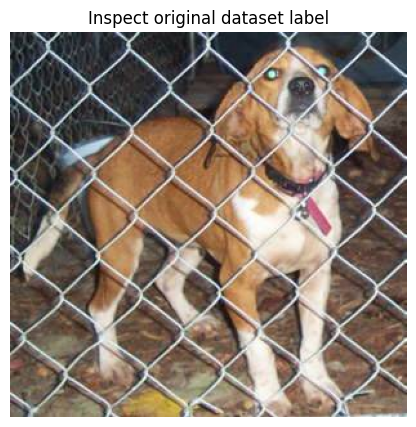

In [22]:

import pandas as pd
import zipfile
import hashlib
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

root = Path("/kaggle/working")

analysis = pd.read_csv(
    root / "misclassification_study/all_predictions.csv"
)

# The pretrained model's most confident incorrect prediction
errors = analysis[
    analysis["wrong_pretrained_2k"]
].sort_values(
    "confidence_pretrained_2k",
    ascending=False
)

row = errors.iloc[0]

print("Original filename:", row["filename"])
print("Assigned label:", row["label"])
print("Label from filename:",
      Path(row["filename"]).name.split(".")[0])
print("Predicted label:",
      "Dog" if row["prediction_pretrained_2k"] == 1
      else "Cat")
print("Prediction confidence:",
      f"{row['confidence_pretrained_2k']*100:.2f}%")

# Verify the image against the original ZIP archive
zip_path = list(
    Path("/kaggle/input").rglob("train.zip")
)[0]

with zipfile.ZipFile(zip_path) as archive:
    original_bytes = archive.read(row["filename"])

saved_bytes = Path(row["image_path"]).read_bytes()

print(
    "Matches original Kaggle image:",
    hashlib.sha256(original_bytes).digest()
    == hashlib.sha256(saved_bytes).digest()
)

with Image.open(row["image_path"]) as img:
    plt.figure(figsize=(6, 5))
    plt.imshow(img.convert("RGB"))
    plt.axis("off")
    plt.title("Inspect original dataset label")
    plt.show()



Scratch CNN - 2,000 Images
Total errors: 436


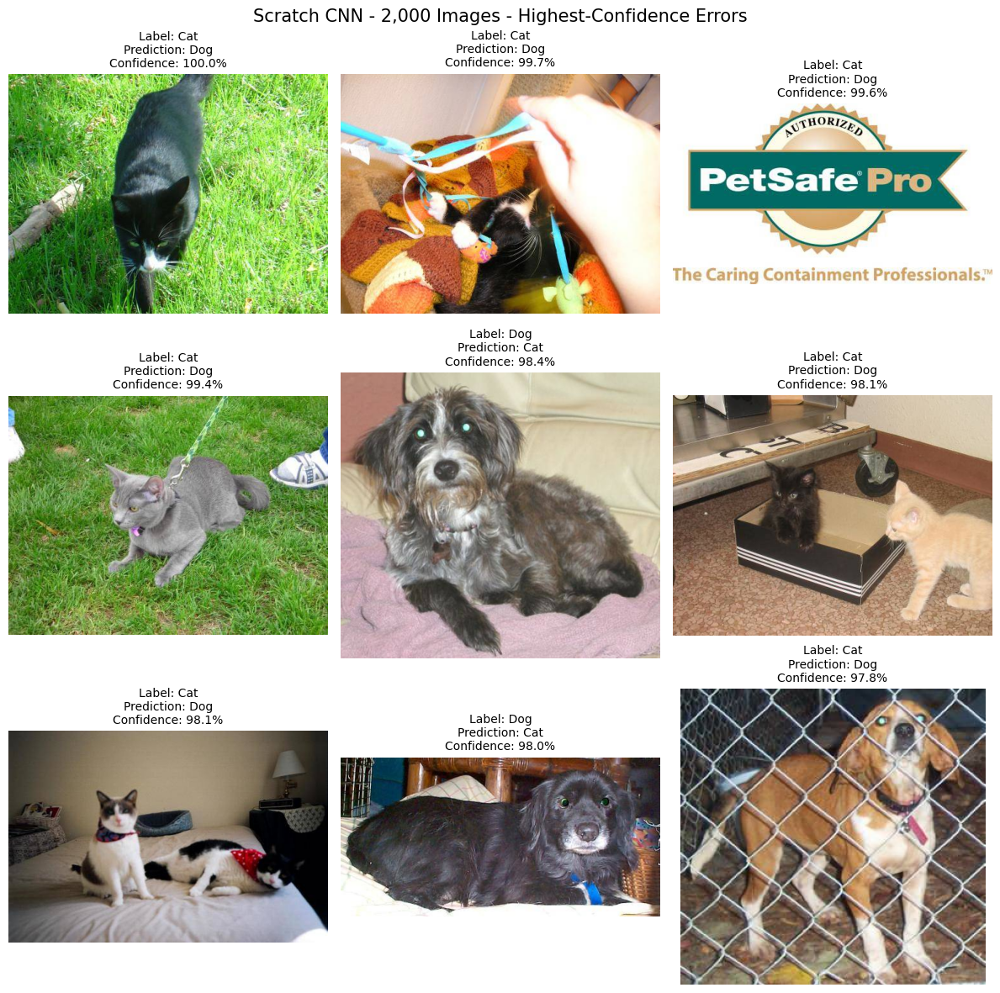


Scratch CNN - 12,000 Images
Total errors: 194


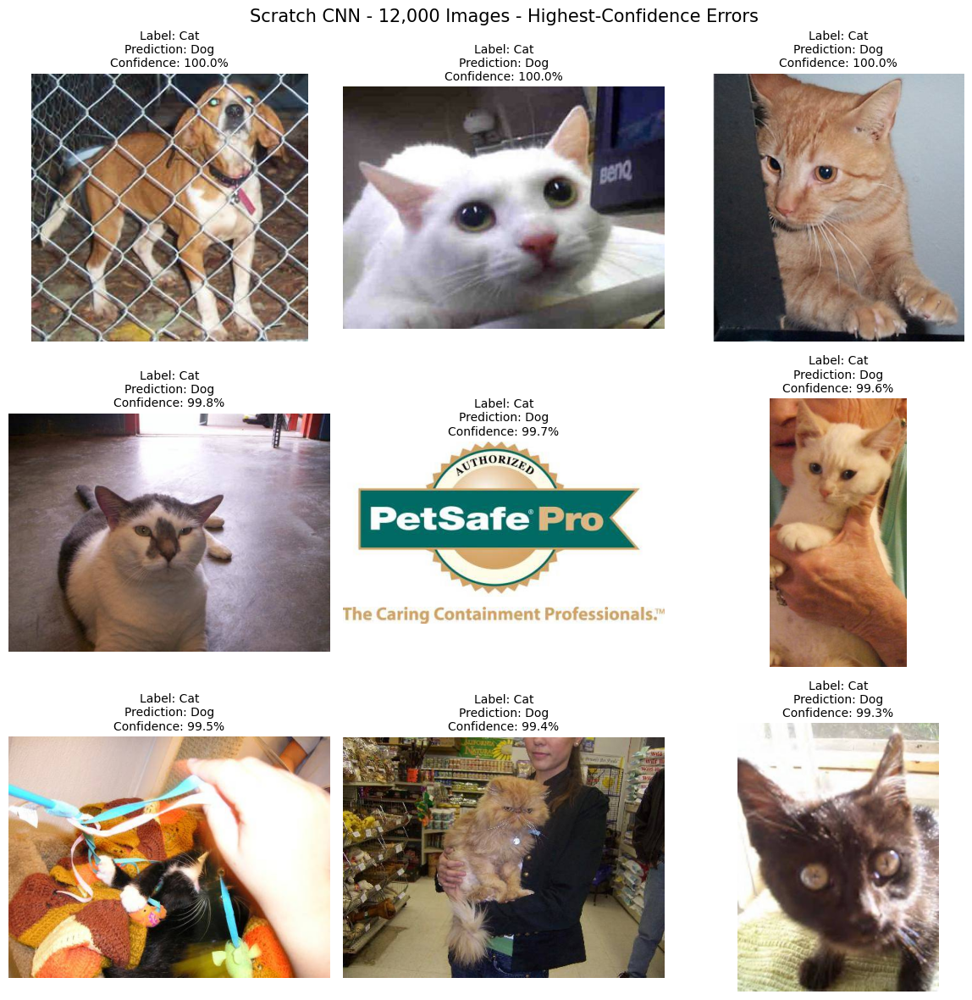


Scratch CNN - 18,000 Images
Total errors: 151


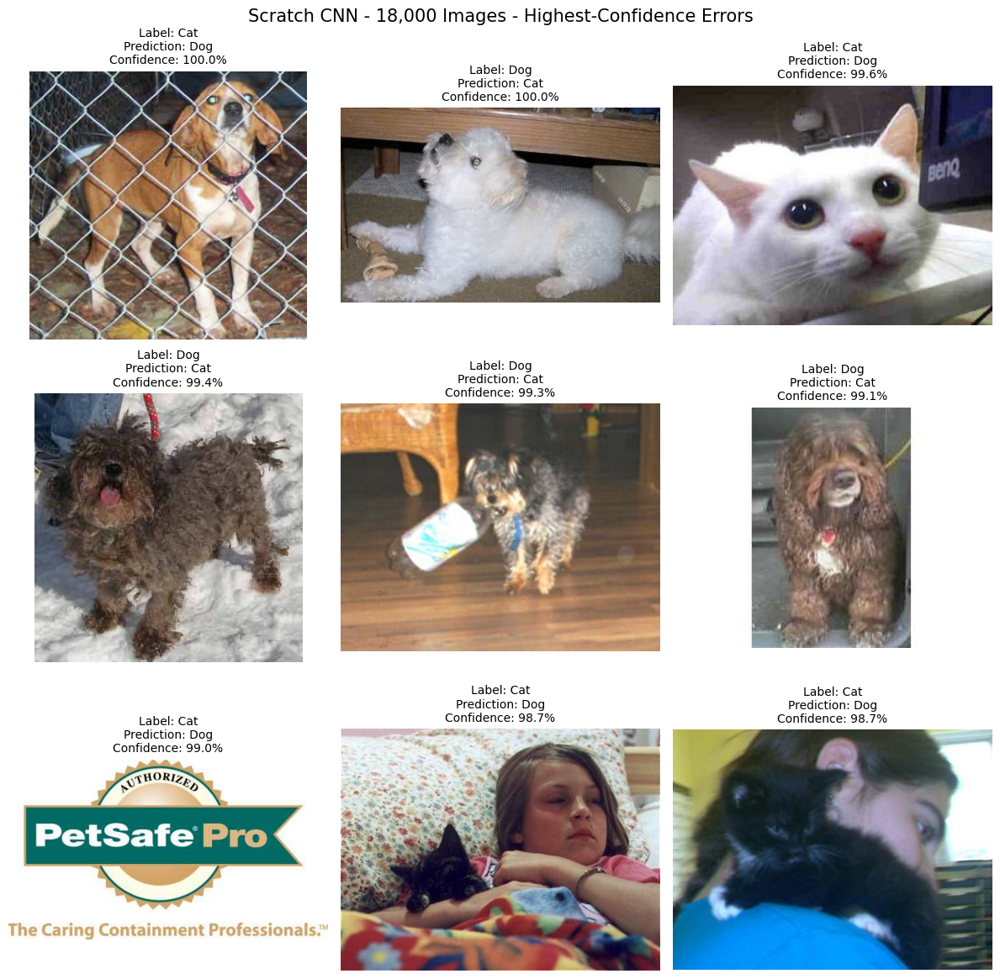


SCRATCH CNN ERROR REVIEW COMPLETE
Images flagged for review: 567
Audit file saved.


In [23]:

# =====================================================
# SCRATCH CNN MISCLASSIFICATION GALLERIES
# No training - uses previously saved predictions
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

root = Path("/kaggle/working")
output = root / "misclassification_study"

analysis = pd.read_csv(
    output / "all_predictions.csv"
)

models = [
    ("scratch_2k", "Scratch CNN - 2,000 Images"),
    ("scratch_12k", "Scratch CNN - 12,000 Images"),
    ("scratch_18k", "Scratch CNN - 18,000 Images")
]

for model_key, model_title in models:

    # Find incorrect predictions
    errors = analysis[
        analysis[f"wrong_{model_key}"]
    ].copy()

    # Highest-confidence errors first
    errors = errors.sort_values(
        f"confidence_{model_key}",
        ascending=False
    )

    print("\n" + "=" * 45)
    print(model_title)
    print("Total errors:", len(errors))
    print("=" * 45)

    fig, axes = plt.subplots(
        3, 3, figsize=(12, 12)
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, row) in zip(
        axes.flat,
        errors.head(9).iterrows()
    ):

        with Image.open(row["image_path"]) as img:
            ax.imshow(img.convert("RGB"))

        prediction = (
            "Dog"
            if row[f"prediction_{model_key}"] == 1
            else "Cat"
        )

        confidence = (
            row[f"confidence_{model_key}"] * 100
        )

        ax.set_title(
            f"Label: {row['label'].title()}\n"
            f"Prediction: {prediction}\n"
            f"Confidence: {confidence:.1f}%",
            fontsize=10
        )

    plt.suptitle(
        model_title + " - Highest-Confidence Errors",
        fontsize=15
    )

    plt.tight_layout()

    plt.savefig(
        output / f"{model_key}_error_gallery.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

# Prepare a list for manual label auditing
error_columns = [
    "wrong_scratch_2k",
    "wrong_scratch_12k",
    "wrong_scratch_18k",
    "wrong_pretrained_2k"
]

review = analysis[
    analysis[error_columns].any(axis=1)
].copy()

review["Human Review Label"] = ""
review["Possible Label Error"] = ""
review["Comments"] = ""

review.to_csv(
    output / "manual_label_audit.csv",
    index=False
)

print("\nSCRATCH CNN ERROR REVIEW COMPLETE")
print("Images flagged for review:", len(review))
print("Audit file saved.")


KNOWN LABEL ERROR: cat.4085.jpg
scratch_2k | Prediction: Dog | Wrong according to label: True
scratch_12k | Prediction: Dog | Wrong according to label: True
scratch_18k | Prediction: Dog | Wrong according to label: True
pretrained_2k | Prediction: Dog | Wrong according to label: True
Occurrences in holdout: 1


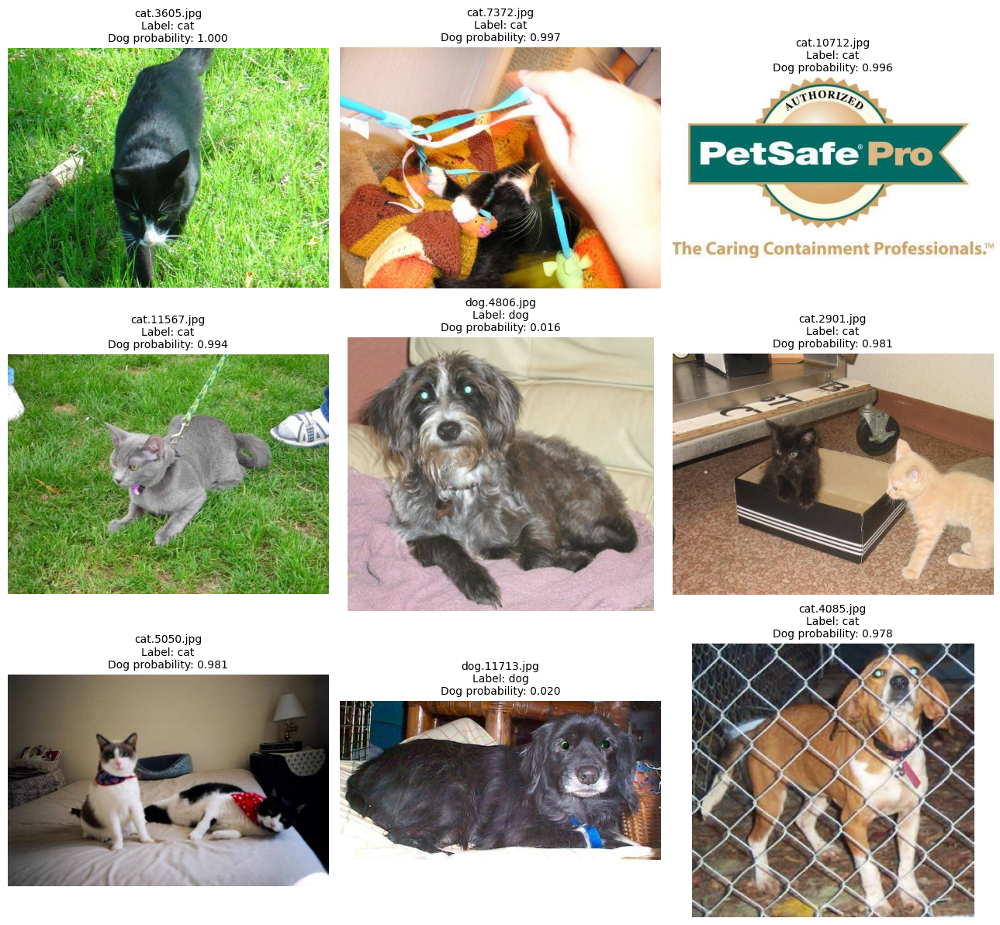

In [24]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

df = pd.read_csv(
    "/kaggle/working/misclassification_study/all_predictions.csv"
)

# 1. Check the known mislabeled dog
dog_error = df[
    df["filename"].astype(str).str.endswith("cat.4085.jpg")
]

print("KNOWN LABEL ERROR: cat.4085.jpg")

if len(dog_error):
    row = dog_error.iloc[0]

    for model in [
        "scratch_2k",
        "scratch_12k",
        "scratch_18k",
        "pretrained_2k"
    ]:
        prediction = (
            "Dog" if row[f"prediction_{model}"] == 1
            else "Cat"
        )

        print(
            model,
            "| Prediction:", prediction,
            "| Wrong according to label:",
            row[f"wrong_{model}"]
        )

    print("Occurrences in holdout:", len(dog_error))

# 2. Display scratch CNN high-confidence mistakes
# WITH original filenames
errors = df[
    df["wrong_scratch_2k"]
].sort_values(
    "confidence_scratch_2k",
    ascending=False
).head(9)

fig, axes = plt.subplots(3, 3, figsize=(13, 12))

for ax, (_, row) in zip(axes.flat, errors.iterrows()):

    with Image.open(row["image_path"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(
        f"{Path(row['filename']).name}\n"
        f"Label: {row['label']}\n"
        f"Dog probability: "
        f"{row['probability_scratch_2k']:.3f}",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()



EVALUATING: Scratch CNN - 1,000
Saved validation accuracy: 73.60%
Verified validation accuracy: 73.60%


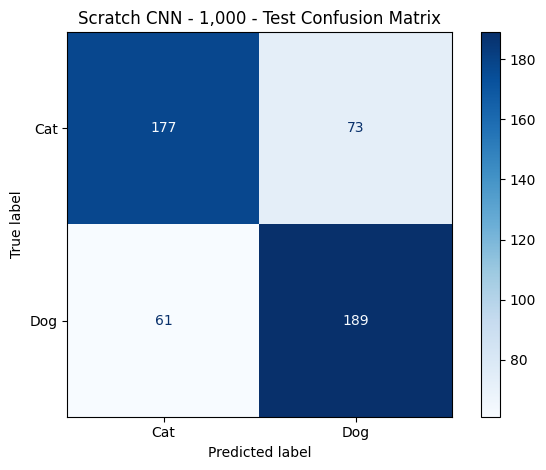


TEST RESULTS
Accuracy: 73.20%
Loss: 0.5761
Precision: 0.7214
Recall: 0.7560
F1 Score: 0.7383
Incorrect predictions: 134

EVALUATING: Scratch CNN - 1,500
Saved validation accuracy: 76.60%
Verified validation accuracy: 76.60%


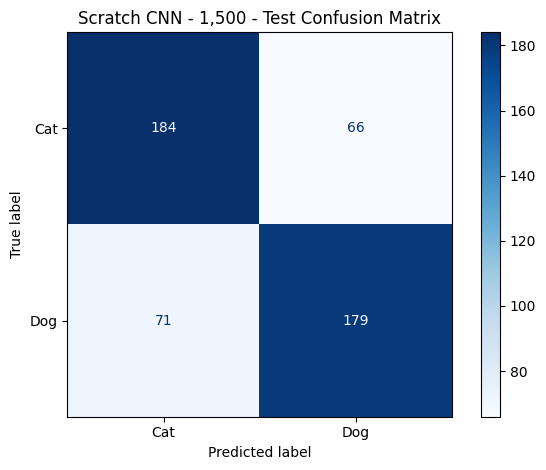


TEST RESULTS
Accuracy: 72.60%
Loss: 0.5990
Precision: 0.7306
Recall: 0.7160
F1 Score: 0.7232
Incorrect predictions: 137

EVALUATING: Pretrained CNN - 1,000
Saved validation accuracy: 97.40%
Verified validation accuracy: 97.40%


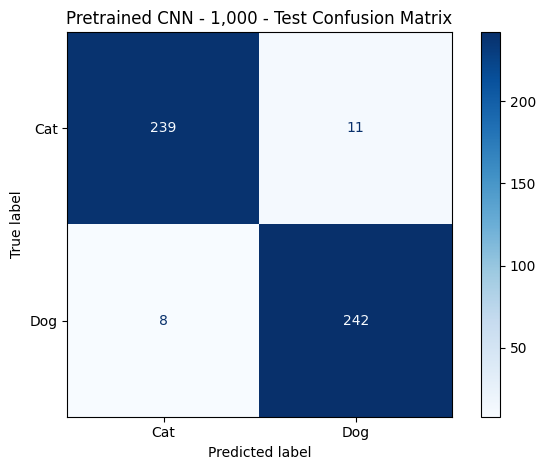


TEST RESULTS
Accuracy: 96.20%
Loss: 0.0857
Precision: 0.9565
Recall: 0.9680
F1 Score: 0.9622
Incorrect predictions: 19

EVALUATING: Pretrained CNN - 1,500
Saved validation accuracy: 97.40%
Verified validation accuracy: 97.40%


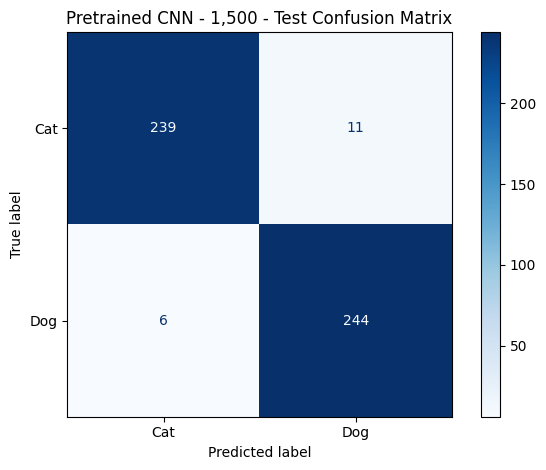


TEST RESULTS
Accuracy: 96.60%
Loss: 0.0787
Precision: 0.9569
Recall: 0.9760
F1 Score: 0.9663
Incorrect predictions: 17

ALL SIX CORE MODELS - FINAL TEST RESULTS
Model Type  Training Images  Validation Accuracy (%)  Test Accuracy (%)  Test Loss  Precision  Recall  F1 Score  Incorrect Predictions
Pretrained             1000                     97.4               96.2     0.0857     0.9565   0.968    0.9622                     19
Pretrained             1500                     97.4               96.6     0.0787     0.9569   0.976    0.9663                     17
Pretrained             2000                     97.6               96.4     0.0699     0.9603   0.968    0.9641                     18
   Scratch             1000                     73.6               73.2     0.5761     0.7214   0.756    0.7383                    134
   Scratch             1500                     76.6               72.6     0.5990     0.7306   0.716    0.7232                    137
   Scratch             2000 

In [25]:

# ============================================================
# ASSIGNMENT 2 - FINAL CORE TEST COMPLETION
# Test the 4 remaining CNN configurations
# No retraining or hyperparameter changes
# ============================================================

import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gc

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

root = Path("/kaggle/working")
output = root / "final_assignment_results"
output.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD ORIGINAL FIXED VALIDATION AND TEST DATA
# ------------------------------------------------------------

manifest = pd.read_csv(
    root / "assignment2_manifest.csv"
)

val_df = manifest[
    manifest["split"] == "validation"
].reset_index(drop=True)

test_df = manifest[
    manifest["split"] == "test"
].reset_index(drop=True)

assert len(val_df) == 500
assert len(test_df) == 500

assert val_df["label"].value_counts().to_dict() == {
    "cat": 250, "dog": 250
}

assert test_df["label"].value_counts().to_dict() == {
    "cat": 250, "dog": 250
}

assert set(val_df["filename"]).isdisjoint(
    set(test_df["filename"])
)

# ------------------------------------------------------------
# 2. DATA LOADER
# ------------------------------------------------------------

label_map = {"cat": 0, "dog": 1}

def make_dataset(frame):

    paths = frame["image_path"].astype(str).to_numpy()

    labels = frame["label"].map(
        label_map
    ).to_numpy(dtype="float32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.image.decode_jpeg(
            image, channels=3
        )
        image = tf.image.resize(
            image, (150, 150)
        )
        return image, tf.expand_dims(label, -1)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(
        tf.data.AUTOTUNE
    )

val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

actual = test_df["label"].map(
    label_map
).to_numpy()

# ------------------------------------------------------------
# 3. FOUR REMAINING MODELS TO TEST
# ------------------------------------------------------------

experiments = [
    {
        "type": "Scratch",
        "images": 1000,
        "folder": "q1_full25",
        "selection": root / "q1_training.csv"
    },
    {
        "type": "Scratch",
        "images": 1500,
        "folder": "q2_full25",
        "selection": root / "q2_full25/q2_training_selection.csv"
    },
    {
        "type": "Pretrained",
        "images": 1000,
        "folder": "q4a_pretrained",
        "selection": root / "q4a_pretrained/training_selection.csv"
    },
    {
        "type": "Pretrained",
        "images": 1500,
        "folder": "q4b_pretrained",
        "selection": root / "q4b_pretrained/training_selection.csv"
    }
]

# ------------------------------------------------------------
# 4. RUN FINAL EVALUATION
# ------------------------------------------------------------

results = []

for experiment in experiments:

    model_type = experiment["type"]
    n = experiment["images"]

    experiment_name = f"{model_type} CNN - {n:,}"

    folder = root / experiment["folder"]

    model_path = folder / "best_model.keras"
    summary_path = folder / "results_summary.csv"

    # Keep previous test measurements if this cell is rerun
    result_path = output / (
        f"core_test_{model_type.lower()}_{n}.csv"
    )

    if result_path.exists():
        print("Reusing recorded test result:", experiment_name)
        results.append(pd.read_csv(result_path).iloc[0].to_dict())
        continue

    assert model_path.exists(), f"Missing model: {model_path}"
    assert summary_path.exists(), f"Missing summary: {summary_path}"
    assert experiment["selection"].exists()

    train_df = pd.read_csv(experiment["selection"])

    assert len(train_df) == n

    assert set(train_df["filename"]).isdisjoint(
        set(val_df["filename"])
    )
    assert set(train_df["filename"]).isdisjoint(
        set(test_df["filename"])
    )

    print("\n" + "=" * 50)
    print("EVALUATING:", experiment_name)
    print("=" * 50)

    tf.keras.backend.clear_session()

    model = tf.keras.models.load_model(
        str(model_path)
    )

    saved_summary = pd.read_csv(
        summary_path
    ).iloc[0]

    expected_val_accuracy = float(
        saved_summary["best_val_accuracy"]
    )

    # Check checkpoint reproducibility
    val_loss, val_accuracy = model.evaluate(
        val_ds, verbose=0
    )

    print(
        "Saved validation accuracy:",
        f"{expected_val_accuracy * 100:.2f}%"
    )

    print(
        "Verified validation accuracy:",
        f"{val_accuracy * 100:.2f}%"
    )

    if abs(val_accuracy - expected_val_accuracy) >= 0.001:
        raise ValueError(
            f"Checkpoint mismatch for {experiment_name}. "
            "Do not continue until files are reconciled."
        )

    # Evaluate on original test set
    test_loss, test_accuracy = model.evaluate(
        test_ds, verbose=0
    )

    probabilities = model.predict(
        test_ds, verbose=0
    ).reshape(-1)

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    assert len(predictions) == len(actual)

    assert abs(
        accuracy_score(actual, predictions) - test_accuracy
    ) < 0.001

    # Classification metrics - Dog is positive class
    precision = precision_score(
        actual, predictions, zero_division=0
    )

    recall = recall_score(
        actual, predictions, zero_division=0
    )

    f1 = f1_score(
        actual, predictions, zero_division=0
    )

    incorrect = int(
        np.sum(predictions != actual)
    )

    result = {
        "Model Type": model_type,
        "Training Images": n,
        "Validation Accuracy (%)": round(
            val_accuracy * 100, 2
        ),
        "Test Accuracy (%)": round(
            test_accuracy * 100, 2
        ),
        "Test Loss": round(test_loss, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1 Score": round(f1, 4),
        "Incorrect Predictions": incorrect
    }

    results.append(result)

    # Save per-model result immediately
    pd.DataFrame([result]).to_csv(
        result_path,
        index=False
    )

    # Save individual image predictions
    pd.DataFrame({
        "filename": test_df["filename"],
        "actual": actual,
        "predicted": predictions,
        "dog_probability": probabilities
    }).to_csv(
        output / f"predictions_{model_type.lower()}_{n}.csv",
        index=False
    )

    # Confusion matrix
    cm = confusion_matrix(
        actual, predictions, labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Cat", "Dog"]
    )

    display.plot(
        cmap="Blues",
        values_format="d"
    )

    plt.title(
        f"{experiment_name} - Test Confusion Matrix"
    )

    plt.tight_layout()
    plt.savefig(
        output / f"confusion_{model_type.lower()}_{n}.png",
        dpi=200
    )
    plt.show()

    print("\nTEST RESULTS")
    print(f"Accuracy: {test_accuracy * 100:.2f}%")
    print(f"Loss: {test_loss:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print("Incorrect predictions:", incorrect)

    del model
    gc.collect()

# ------------------------------------------------------------
# 5. LOAD PREVIOUSLY TESTED CORE MODELS
# ------------------------------------------------------------

previous_file = (
    output / "final_test_results.csv"
)

assert previous_file.exists(), (
    "Previous Q3 and Q4C test results not found."
)

previous = pd.read_csv(previous_file)

combined = results.copy()

for _, row in previous.iterrows():

    if row["Model"] == "CNN From Scratch":
        model_type = "Scratch"

    elif row["Model"] == "Pretrained MobileNetV2":
        model_type = "Pretrained"

    else:
        continue

    n = int(row["Training Images"])

    # Verify saved validation result has not changed
    summary_folder = (
        root / "q3_full25"
        if model_type == "Scratch"
        else root / "q4c_pretrained"
    )

    recorded = pd.read_csv(
        summary_folder / "results_summary.csv"
    ).iloc[0]

    assert abs(
        float(recorded["best_val_accuracy"]) * 100
        - float(row["Validation Accuracy (%)"])
    ) < 0.1

    combined.append({
        "Model Type": model_type,
        "Training Images": n,
        "Validation Accuracy (%)":
            row["Validation Accuracy (%)"],
        "Test Accuracy (%)":
            row["Test Accuracy (%)"],
        "Test Loss": row["Test Loss"],
        "Precision": row["Precision"],
        "Recall": row["Recall"],
        "F1 Score": row["F1 Score"],
        "Incorrect Predictions": round(
            (1 - row["Test Accuracy (%)"] / 100) * 500
        )
    })

# ------------------------------------------------------------
# 6. FINAL SIX-MODEL COMPARISON
# ------------------------------------------------------------

comparison = pd.DataFrame(combined)

comparison = comparison.sort_values(
    ["Model Type", "Training Images"]
).reset_index(drop=True)

assert len(comparison) == 6
assert not comparison.duplicated(
    ["Model Type", "Training Images"]
).any()

comparison.to_csv(
    output / "all_six_core_test_results.csv",
    index=False
)

print("\n" + "=" * 60)
print("ALL SIX CORE MODELS - FINAL TEST RESULTS")
print("=" * 60)

print(comparison.to_string(index=False))

print("\nSaved to:")
print(output / "all_six_core_test_results.csv")
print("\nFINAL CORE TESTING COMPLETE")



===== MASTER: ALL EIGHT MODELS =====
Model Type  Training Images  Validation Accuracy (%)  Test Accuracy (%)  Test Loss  F1 Score
Pretrained             1000                     97.4               96.2     0.0857    0.9622
Pretrained             1500                     97.4               96.6     0.0787    0.9663
Pretrained             2000                     97.6               96.4     0.0699    0.9641
   Scratch             1000                     73.6               73.2     0.5761    0.7383
   Scratch             1500                     76.6               72.6     0.5990    0.7232
   Scratch             2000                     80.0               76.8     0.4798    0.7725
   Scratch            12000                     91.0               92.4     0.1926    0.9252
   Scratch            18000                     93.0               93.2     0.1667    0.9312


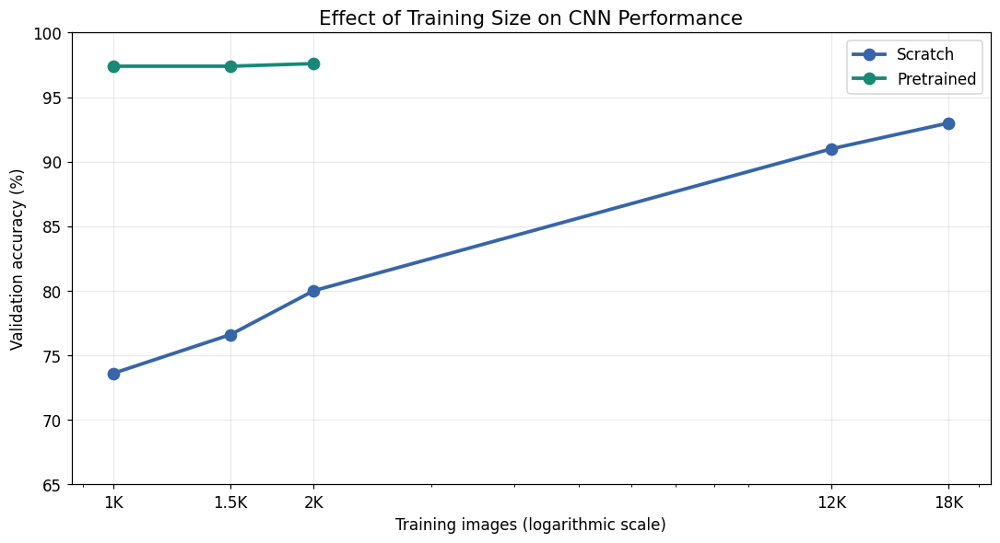

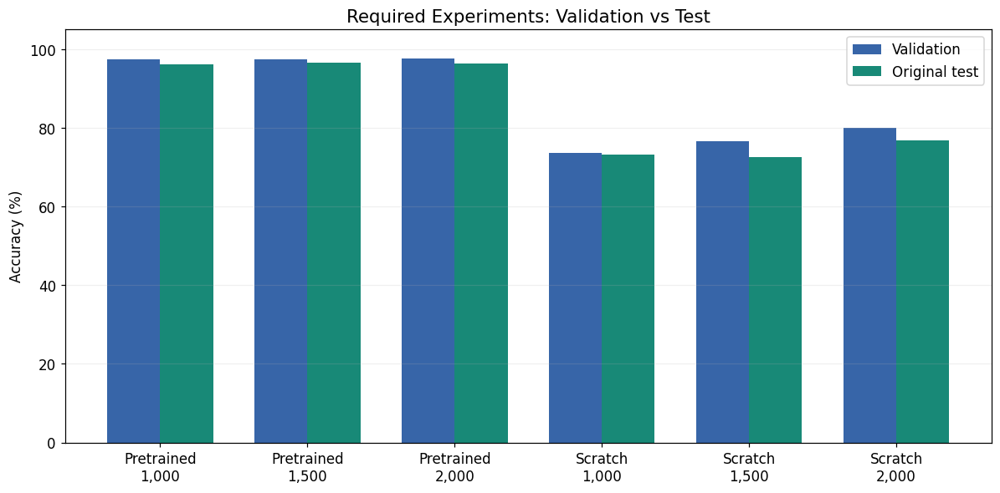

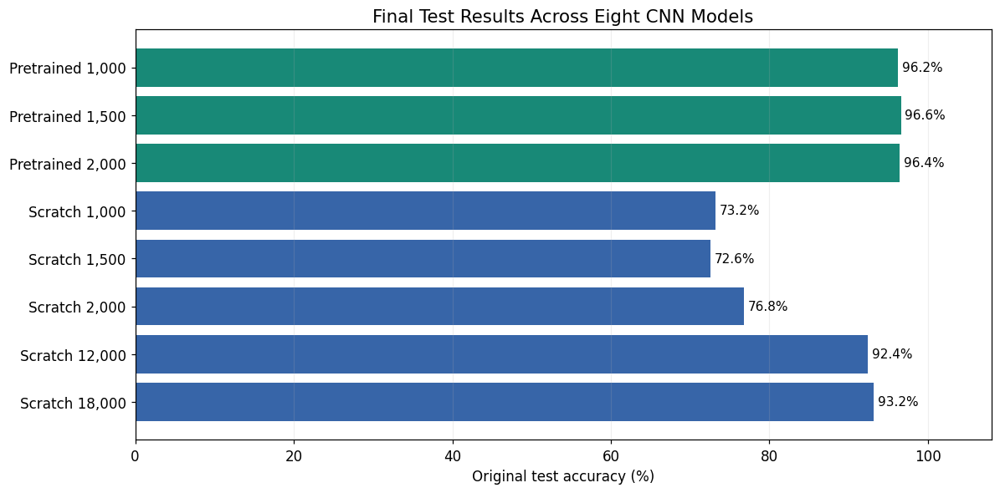

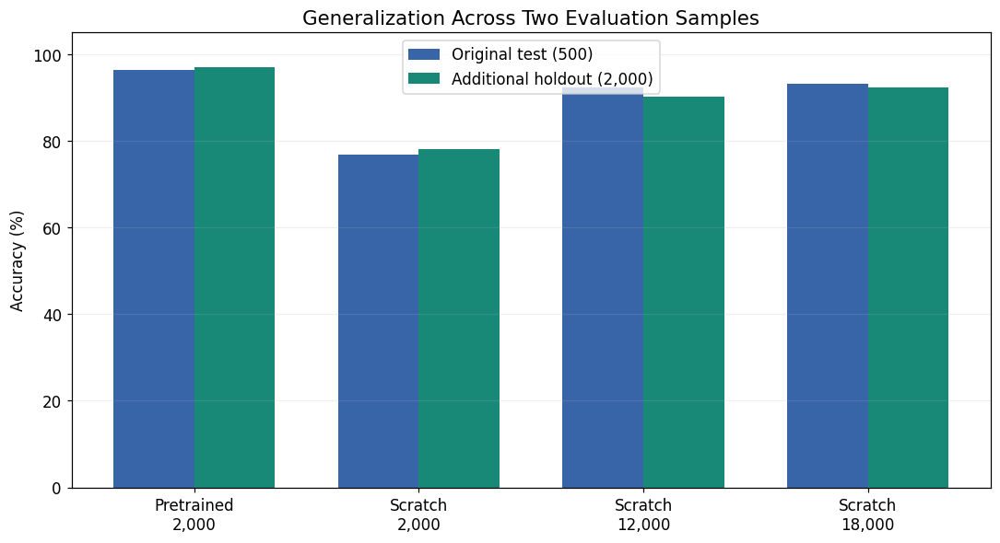

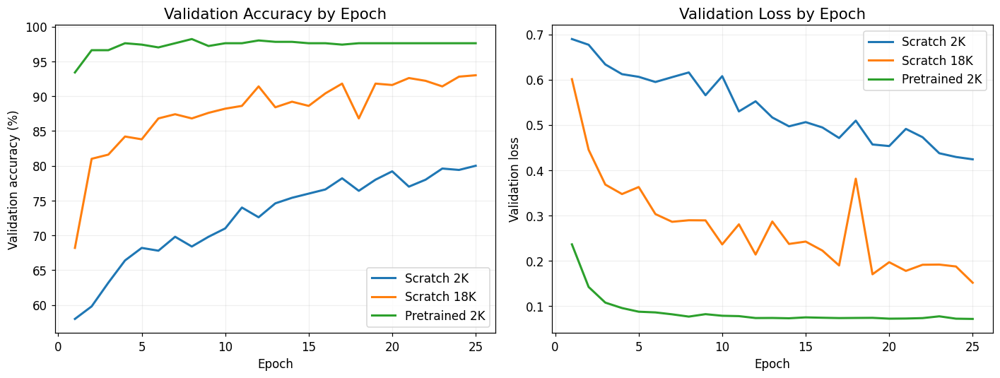

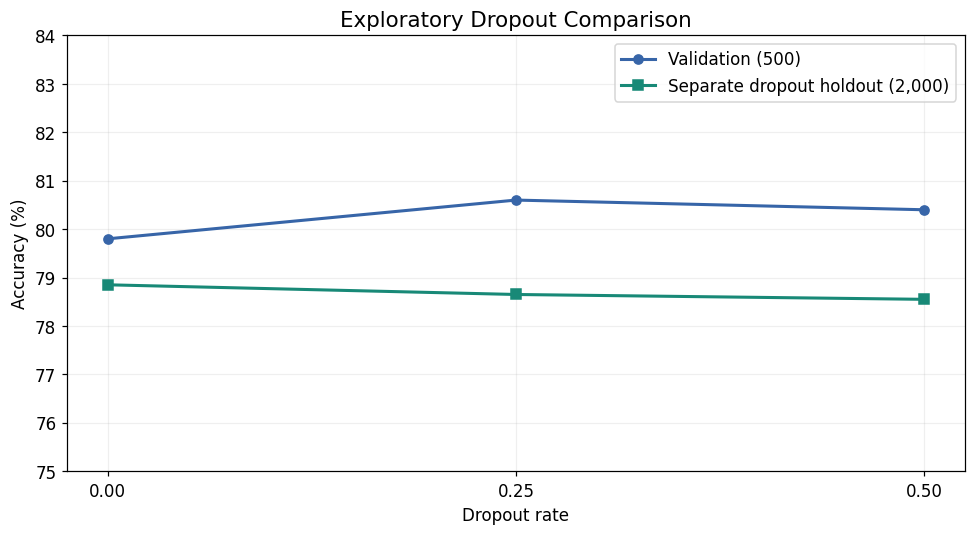

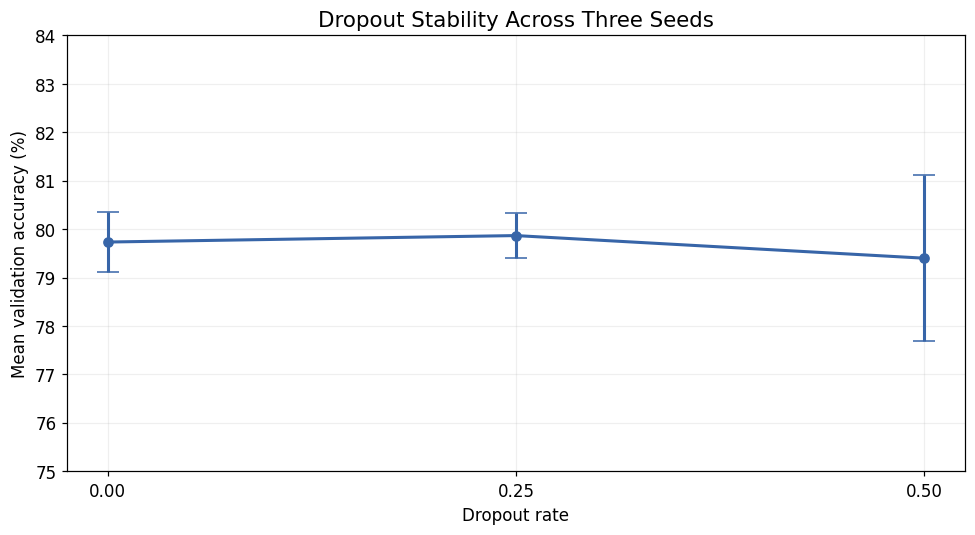

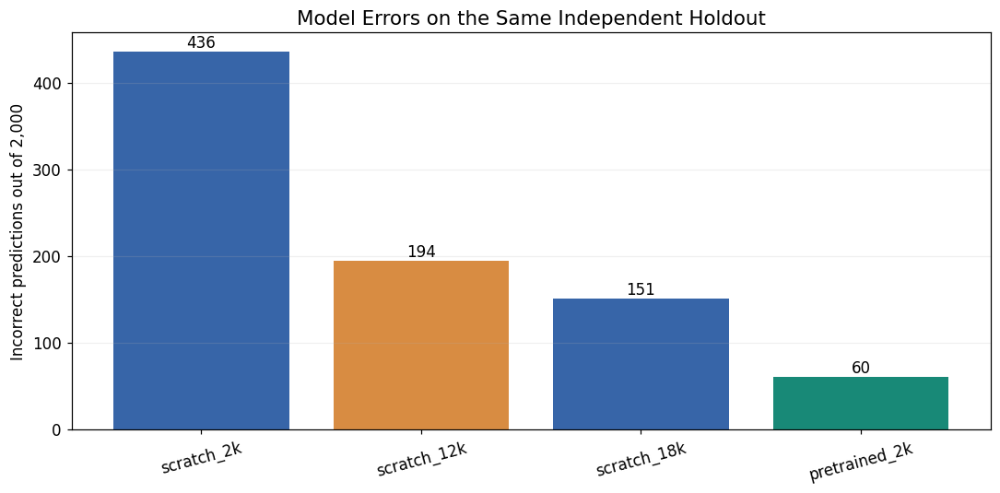


===== KEY FINDINGS =====
- Scratch validation gain, 1K to 2K: 6.40 percentage points
- Pretrained validation gain, 1K to 2K: 0.20 percentage points
- Scratch 18K test accuracy: 93.20%
- Pretrained 2K test accuracy: 96.40%
- Pretrained 2K minus Scratch 18K test: +3.20 percentage points
- Core models use the original 500-image test set.
- Additional 2000-image model holdout and dropout holdout are different samples.
- Model architecture and pretrained weights differ between scratch and pretrained comparisons.
- Known suspected source-label issue: cat.4085.jpg shows a dog; original scores preserved.
- Additional evaluations are descriptive, not a basis for further model tuning.

===== FINAL FIGURES =====
01_dataset_size_vs_accuracy.png
02_six_core_validation_vs_test.png
03_all_eight_test_accuracy.png
04_original_vs_additional_holdout.png
05_learning_curves.png
06_dropout_sensitivity.png
07_seed_stability.png
08_model_error_counts.png

MASTER VISUALIZATION COMPLETE
All outputs: /kaggle/wo

In [26]:

# ============================================================
# ASSIGNMENT 2 - MASTER RESULTS AND VISUALIZATIONS
# Uses saved experiment results only - NO RETRAINING
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

root = Path("/kaggle/working")
out = root / "assignment2_master_visuals"
out.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD AND VERIFY RESULTS
# ------------------------------------------------------------

paths = {
    "core": root / "final_assignment_results/all_six_core_test_results.csv",
    "overall": root / "final_assignment_results/overall_test_comparison.csv",
    "holdout": root / "additional_holdout_evaluation/additional_holdout_results.csv",
    "dropout": root / "dropout_experiments/dropout_comparison.csv",
    "dropout_test": root / "dropout_experiments/unused_holdout_results.csv",
    "seeds": root / "dropout_seed_study/seed_stability_summary.csv",
    "errors": root / "misclassification_study/error_summary.csv"
}

for name, path in paths.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {name}: {path}\n"
            "Check that the earlier experiment cell was saved."
        )

core = pd.read_csv(paths["core"])
overall = pd.read_csv(paths["overall"])
holdout = pd.read_csv(paths["holdout"])
dropout = pd.read_csv(paths["dropout"])
dropout_test = pd.read_csv(paths["dropout_test"])
seeds = pd.read_csv(paths["seeds"])
errors = pd.read_csv(paths["errors"])

assert len(core) == 6
assert set(core["Model Type"]) == {"Scratch", "Pretrained"}
assert not core.duplicated(
    ["Model Type", "Training Images"]
).any()

# Verify core results match their corresponding model summaries
core_folders = {
    ("Scratch", 1000): "q1_full25",
    ("Scratch", 1500): "q2_full25",
    ("Scratch", 2000): "q3_full25",
    ("Pretrained", 1000): "q4a_pretrained",
    ("Pretrained", 1500): "q4b_pretrained",
    ("Pretrained", 2000): "q4c_pretrained"
}

for (model_type, n), folder in core_folders.items():
    saved = pd.read_csv(
        root / folder / "results_summary.csv"
    ).iloc[0]

    recorded = core[
        (core["Model Type"] == model_type) &
        (core["Training Images"] == n)
    ].iloc[0]

    assert abs(
        float(saved["best_val_accuracy"]) * 100 -
        float(recorded["Validation Accuracy (%)"])
    ) < 0.11, f"Validation mismatch: {model_type}, {n}"

# Add the two extended scratch experiments
extended_rows = []

for n in [12000, 18000]:

    row = overall[
        overall["Training Images"] == n
    ]

    assert len(row) == 1, (
        f"Missing or duplicated {n}-image test result"
    )

    row = row.iloc[0]

    summary = pd.read_csv(
        root / f"extended_experiments/cnn_{n}/results_summary.csv"
    ).iloc[0]

    saved_val = float(
        summary["original_val_accuracy"]
    ) * 100

    assert abs(
        saved_val - float(row["Validation Accuracy (%)"])
    ) < 0.21, f"Extended model mismatch: {n}"

    extended_rows.append({
        "Model Type": "Scratch",
        "Training Images": n,
        "Validation Accuracy (%)": saved_val,
        "Test Accuracy (%)": float(row["Test Accuracy (%)"]),
        "Test Loss": float(row["Test Loss"]),
        "F1 Score": float(row["F1 Score"])
    })

# Main eight-model comparison
main_cols = [
    "Model Type",
    "Training Images",
    "Validation Accuracy (%)",
    "Test Accuracy (%)",
    "Test Loss",
    "F1 Score"
]

all8 = pd.concat(
    [
        core[main_cols],
        pd.DataFrame(extended_rows)[main_cols]
    ],
    ignore_index=True
)

all8 = all8.sort_values(
    ["Model Type", "Training Images"]
).reset_index(drop=True)

assert len(all8) == 8
assert not all8.duplicated(
    ["Model Type", "Training Images"]
).any()

all8.to_csv(
    out / "master_eight_model_comparison.csv",
    index=False
)

print("\n===== MASTER: ALL EIGHT MODELS =====")
print(all8.round(4).to_string(index=False))

# ------------------------------------------------------------
# 2. HELPER FOR SAVING GRAPHS
# ------------------------------------------------------------

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "figure.dpi": 110
})

SCRATCH = "#3765A8"
PRETRAINED = "#188977"
ORANGE = "#D88C42"

def save_chart(fig, filename):
    fig.tight_layout()
    fig.savefig(
        out / filename,
        dpi=220,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# FIGURE 1: TRAINING SIZE VS VALIDATION ACCURACY
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5.5))

for model_type, color in [
    ("Scratch", SCRATCH),
    ("Pretrained", PRETRAINED)
]:

    d = all8[
        all8["Model Type"] == model_type
    ].sort_values("Training Images")

    ax.plot(
        d["Training Images"],
        d["Validation Accuracy (%)"],
        marker="o",
        linewidth=2.5,
        markersize=8,
        color=color,
        label=model_type
    )

ax.set_xscale("log")
ax.set_xticks([1000, 1500, 2000, 12000, 18000])
ax.set_xticklabels(["1K", "1.5K", "2K", "12K", "18K"])

ax.set_ylim(65, 100)
ax.set_xlabel("Training images (logarithmic scale)")
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("Effect of Training Size on CNN Performance")
ax.legend()
ax.grid(alpha=0.25)

save_chart(fig, "01_dataset_size_vs_accuracy.png")

# ------------------------------------------------------------
# FIGURE 2: SIX REQUIRED MODELS - VALIDATION VS TEST
# ------------------------------------------------------------

d = core.sort_values(
    ["Model Type", "Training Images"]
).copy()

labels = [
    f"{r['Model Type']}\n{int(r['Training Images']):,}"
    for _, r in d.iterrows()
]

x = np.arange(len(d))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.bar(
    x - width/2,
    d["Validation Accuracy (%)"],
    width,
    label="Validation",
    color=SCRATCH
)

ax.bar(
    x + width/2,
    d["Test Accuracy (%)"],
    width,
    label="Original test",
    color=PRETRAINED
)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 105)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Required Experiments: Validation vs Test")
ax.legend()
ax.grid(axis="y", alpha=0.2)

save_chart(fig, "02_six_core_validation_vs_test.png")

# ------------------------------------------------------------
# FIGURE 3: ALL EIGHT MODELS - TEST ACCURACY
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5.5))

labels = [
    f"{r['Model Type']} {int(r['Training Images']):,}"
    for _, r in all8.iterrows()
]

colors = [
    PRETRAINED if m == "Pretrained" else SCRATCH
    for m in all8["Model Type"]
]

bars = ax.barh(
    labels,
    all8["Test Accuracy (%)"],
    color=colors
)

ax.invert_yaxis()
ax.set_xlim(0, 108)
ax.set_xlabel("Original test accuracy (%)")
ax.set_title("Final Test Results Across Eight CNN Models")

for bar, value in zip(
    bars, all8["Test Accuracy (%)"]
):
    ax.text(
        value + 0.5,
        bar.get_y() + bar.get_height()/2,
        f"{value:.1f}%",
        va="center",
        fontsize=10
    )

ax.grid(axis="x", alpha=0.2)

save_chart(fig, "03_all_eight_test_accuracy.png")

# ------------------------------------------------------------
# FIGURE 4: ORIGINAL TEST VS ADDITIONAL HOLDOUT
# Only four models were evaluated on that holdout.
# ------------------------------------------------------------

selected = all8[
    (
        (all8["Model Type"] == "Scratch") &
        (all8["Training Images"].isin([2000, 12000, 18000]))
    ) |
    (
        (all8["Model Type"] == "Pretrained") &
        (all8["Training Images"] == 2000)
    )
].copy()

holdout_map = {}

for _, r in holdout.iterrows():

    name = str(r["Model"]).lower()
    n = int(r["Training Images"])

    model_type = (
        "Pretrained" if "pretrained" in name else "Scratch"
    )

    holdout_map[(model_type, n)] = float(
        r["Accuracy (%)"]
    )

selected["Additional Holdout Accuracy (%)"] = [
    holdout_map[(r["Model Type"], int(r["Training Images"]))]
    for _, r in selected.iterrows()
]

fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(len(selected))
width = 0.36

ax.bar(
    x-width/2,
    selected["Test Accuracy (%)"],
    width,
    label="Original test (500)",
    color=SCRATCH
)

ax.bar(
    x+width/2,
    selected["Additional Holdout Accuracy (%)"],
    width,
    label="Additional holdout (2,000)",
    color=PRETRAINED
)

ax.set_xticks(x)

ax.set_xticklabels([
    f"{r['Model Type']}\n{int(r['Training Images']):,}"
    for _, r in selected.iterrows()
])

ax.set_ylim(0, 105)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Generalization Across Two Evaluation Samples")
ax.legend()
ax.grid(axis="y", alpha=0.2)

save_chart(fig, "04_original_vs_additional_holdout.png")

# ------------------------------------------------------------
# FIGURE 5: LEARNING CURVES
# Representative models using saved training histories
# ------------------------------------------------------------

history_files = {
    "Scratch 2K":
        root / "q3_full25/training_history.csv",
    "Scratch 18K":
        root / "extended_experiments/cnn_18000/training_history.csv",
    "Pretrained 2K":
        root / "q4c_pretrained/training_history.csv"
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, path in history_files.items():

    assert path.exists(), f"Missing history: {path}"

    h = pd.read_csv(path)
    epochs = np.arange(1, len(h) + 1)

    axes[0].plot(
        epochs,
        h["val_accuracy"] * 100,
        label=name,
        linewidth=2
    )

    axes[1].plot(
        epochs,
        h["val_loss"],
        label=name,
        linewidth=2
    )

axes[0].set_title("Validation Accuracy by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation accuracy (%)")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].set_title("Validation Loss by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation loss")
axes[1].legend()
axes[1].grid(alpha=0.2)

save_chart(fig, "05_learning_curves.png")

# ------------------------------------------------------------
# FIGURE 6: DROPOUT SENSITIVITY
# Note: validation and test use different evaluation sets
# ------------------------------------------------------------

d = dropout.merge(
    dropout_test[
        ["Dropout Rate", "Test Accuracy (%)"]
    ],
    on="Dropout Rate",
    validate="one_to_one"
).sort_values("Dropout Rate")

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    d["Dropout Rate"],
    d["Validation Accuracy (%)"],
    marker="o",
    linewidth=2,
    label="Validation (500)",
    color=SCRATCH
)

ax.plot(
    d["Dropout Rate"],
    d["Test Accuracy (%)"],
    marker="s",
    linewidth=2,
    label="Separate dropout holdout (2,000)",
    color=PRETRAINED
)

ax.set_xticks([0, 0.25, 0.5])
ax.set_ylim(75, 84)
ax.set_xlabel("Dropout rate")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Exploratory Dropout Comparison")
ax.legend()
ax.grid(alpha=0.2)

save_chart(fig, "06_dropout_sensitivity.png")

# ------------------------------------------------------------
# FIGURE 7: RANDOM-SEED STABILITY
# ------------------------------------------------------------

seeds = seeds.sort_values("Dropout")

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    seeds["Dropout"],
    seeds["Mean_Accuracy"],
    yerr=seeds["Std_Accuracy"],
    marker="o",
    linewidth=2,
    capsize=7,
    color=SCRATCH
)

ax.set_xticks([0, 0.25, 0.5])
ax.set_xlabel("Dropout rate")
ax.set_ylabel("Mean validation accuracy (%)")
ax.set_ylim(75, 84)
ax.set_title("Dropout Stability Across Three Seeds")
ax.grid(alpha=0.2)

save_chart(fig, "07_seed_stability.png")

# ------------------------------------------------------------
# FIGURE 8: MISCLASSIFICATION COUNTS
# Same 2000-image holdout for all four models
# ------------------------------------------------------------

errors = errors.sort_values(
    "Incorrect", ascending=False
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    errors["Model"],
    errors["Incorrect"],
    color=[SCRATCH, ORANGE, SCRATCH, PRETRAINED]
)

ax.set_ylabel("Incorrect predictions out of 2,000")
ax.set_title("Model Errors on the Same Independent Holdout")
ax.tick_params(axis="x", rotation=15)

for bar, value in zip(bars, errors["Incorrect"]):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 5,
        str(int(value)),
        ha="center"
    )

ax.grid(axis="y", alpha=0.2)

save_chart(fig, "08_model_error_counts.png")

# ------------------------------------------------------------
# 9. SAVE SUMMARIES AND HIGHLIGHTS
# ------------------------------------------------------------

core_scratch = core[
    core["Model Type"] == "Scratch"
].sort_values("Training Images")

core_pretrained = core[
    core["Model Type"] == "Pretrained"
].sort_values("Training Images")

scratch_val_gain = (
    core_scratch["Validation Accuracy (%)"].iloc[-1] -
    core_scratch["Validation Accuracy (%)"].iloc[0]
)

pretrained_val_gain = (
    core_pretrained["Validation Accuracy (%)"].iloc[-1] -
    core_pretrained["Validation Accuracy (%)"].iloc[0]
)

scratch18_test = float(
    all8[
        (all8["Model Type"] == "Scratch") &
        (all8["Training Images"] == 18000)
    ]["Test Accuracy (%)"].iloc[0]
)

pretrained2_test = float(
    all8[
        (all8["Model Type"] == "Pretrained") &
        (all8["Training Images"] == 2000)
    ]["Test Accuracy (%)"].iloc[0]
)

highlights = [
    f"Scratch validation gain, 1K to 2K: {scratch_val_gain:.2f} percentage points",
    f"Pretrained validation gain, 1K to 2K: {pretrained_val_gain:.2f} percentage points",
    f"Scratch 18K test accuracy: {scratch18_test:.2f}%",
    f"Pretrained 2K test accuracy: {pretrained2_test:.2f}%",
    f"Pretrained 2K minus Scratch 18K test: {pretrained2_test-scratch18_test:+.2f} percentage points",
    "Core models use the original 500-image test set.",
    "Additional 2000-image model holdout and dropout holdout are different samples.",
    "Model architecture and pretrained weights differ between scratch and pretrained comparisons.",
    "Known suspected source-label issue: cat.4085.jpg shows a dog; original scores preserved.",
    "Additional evaluations are descriptive, not a basis for further model tuning."
]

(out / "analysis_highlights.txt").write_text(
    "\n".join(highlights)
)

print("\n===== KEY FINDINGS =====")

for item in highlights:
    print("-", item)

print("\n===== FINAL FIGURES =====")

for file in sorted(out.glob("*.png")):
    print(file.name)

print("\nMASTER VISUALIZATION COMPLETE")
print("All outputs:", out)
